S1 B

C:\Users\Cornell\AppData\Local\Temp\ipykernel_29608\1392950794.py:546: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

C:\Users\Cornell\AppData\Local\Temp\ipykernel_29608\1392950794.py:546: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.


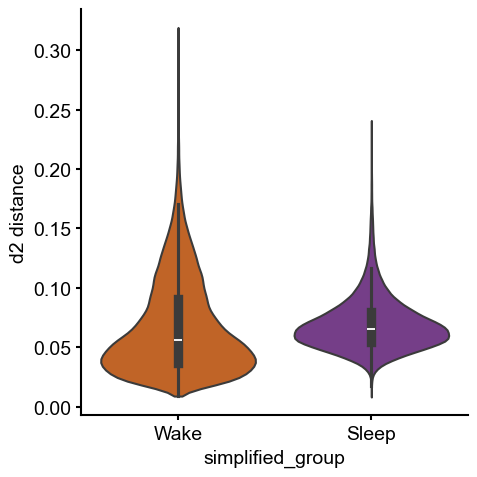

In [9]:
# # Global font: prefer Arial, with safe fallbacks
import matplotlib as mpl
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

# Make mathtext look like Arial
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Arial'
mpl.rcParams['mathtext.it'] = 'Arial:italic'
mpl.rcParams['mathtext.bf'] = 'Arial:bold' 

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
import os
import pickle
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import nelpy as nel
import nelpy.plotting as npl
import numpy as np
import seaborn as sns
from neuro_py.io import loading
from neuro_py.plotting.figure_helpers import set_size
from neuro_py.tuning import maps
import os, re, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ------------------ I/O helpers ------------------
def _load_mat_any(mat_path):
    from scipy.io import loadmat
    try:
        return loadmat(mat_path, squeeze_me=True, struct_as_record=False, simplify_cells=True)
    except TypeError:
        return loadmat(mat_path, squeeze_me=True, struct_as_record=False)
    except NotImplementedError:
        import mat73
        return mat73.loadmat(mat_path)

def _to_1d_array(x):
    if x is None:
        return np.array([], dtype=float)
    arr = np.asarray(x, dtype=object)
    if arr.ndim == 0:
        return np.atleast_1d(arr).astype(float, copy=False)
    try:
        return np.asarray(arr).ravel().astype(float, copy=False)
    except (ValueError, TypeError):
        return np.array([float(v) for v in np.ravel(arr)], dtype=float)

def _to_state_str(s):
    try:
        if isinstance(s, (bytes, bytearray)):
            return s.decode('utf-8', 'ignore')
        if isinstance(s, str):
            return s
        arr = np.asarray(s)
        if arr.ndim == 0:
            return str(arr.item())
        return ''.join(arr.tolist()) if arr.dtype.kind in ('U','S') else str(arr)
    except Exception:
        return str(s)

def _infer_animal_day_from_path(basepath):
    base = os.path.basename(basepath.rstrip("\\/"))
    animal = os.path.basename(os.path.dirname(basepath))
    mday = re.search(r"day(\d+)", base, flags=re.I)
    day = int(mday.group(1)) if mday else None
    return animal, day

# ------------------ extract center_s + d2 ------------------
def _extract_center_d2_by_state_from_mat(mat_path, region=None, animal=None, day=None):
    """
    Returns DataFrame with columns:
      state, center_s, d2, region, animal, day
    """
    mat = _load_mat_any(mat_path)
    results = mat.get("results", None)
    if results is None:
        return pd.DataFrame(columns=["state","center_s","d2","region","animal","day"])

    if isinstance(results, dict):
        iter_results = list(results.values())
    else:
        iter_results = list(results if isinstance(results, (list, tuple)) else np.atleast_1d(results))

    rows = []
    for it in iter_results:
        if hasattr(it, "get"):
            st = _to_state_str(it.get("state", "UNKNOWN"))
            c_raw = it.get("center", [])
            d2_raw = it.get("d2", [])
        elif isinstance(it, dict) or hasattr(it, "__getitem__"):
            st = _to_state_str(it.get("state", it["state"] if "state" in it else "UNKNOWN"))
            c_raw = it.get("center", it["center"] if "center" in it else [])
            d2_raw = it.get("d2", it["d2"] if "d2" in it else [])
        else:
            st, c_raw, d2_raw = "UNKNOWN", [], []

        centers = _to_1d_array(c_raw)
        d2_vals = _to_1d_array(d2_raw)
        ok = np.isfinite(centers) & np.isfinite(d2_vals)
        centers, d2_vals = centers[ok], d2_vals[ok]
        if centers.size == 0:
            continue

        st_up = _to_state_str(st).upper()
        if st_up == "WAKE":
            st_up = "AWAKE"
        if st_up not in ("NREM", "AWAKE", "REM"):
            continue

        rows.append(pd.DataFrame({
            "state": st_up,
            "center_s": centers.astype(float, copy=False),
            "d2": d2_vals.astype(float, copy=False),
            "region": region if region else "",
            "animal": animal if animal else "",
            "day": day if day is not None else ""
        }))

    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame(
        columns=["state","center_s","d2","region","animal","day"]
    )

def load_center_d2_from_session(basepath, region):
    """
    Loads newest 30s and newest 60s files (if any) and returns pooled
    center_s + d2 with a 'window' column ∈ {'30s','60s'}.
    """
    region = region.upper()
    search_dir = Path(basepath) / "complex_system"
    if not search_dir.exists():
        return pd.DataFrame(columns=["state","center_s","d2","window","region","animal","day"])

    pats = {
        "30s": f"*_{region}_D2_time_resolved_error_bar.mat",
    }
    animal, day = _infer_animal_day_from_path(basepath)

    out = []
    for win_label, pat in pats.items():
        files = glob.glob(str(search_dir / pat))
        if not files:
            continue
        mat_path = max(files, key=os.path.getmtime)
        df = _extract_center_d2_by_state_from_mat(mat_path, region=region, animal=animal, day=day)
        if df.empty:
            continue
        df["window"] = win_label
        out.append(df)

    return pd.concat(out, ignore_index=True) if out else pd.DataFrame(
        columns=["state","center_s","d2","window","region","animal","day"]
    )

# --- compute per-row durations from timestamps (not median step) ---
def add_duration_from_timestamps(df, fill_last="median"):
    """
    For each (animal, day, window, state), sort by center_s and compute row-wise
    duration as the forward difference: duration[i] = center[i+1] - center[i].
    The last row per group gets:
        - fill_last="median": group's median Δt
        - fill_last="drop": NaN (will be dropped later)
        - fill_last=float: a constant seconds value
    Returns a copy with a new 'duration_s' column.
    """
    d = df.copy()
    grp_cols = ["animal","day","window","state"]

    def _durations(g):
        g = g.sort_values("center_s")
        c = g["center_s"].to_numpy(dtype=float)
        dt = np.empty_like(c, dtype=float)
        if c.size == 1:
            dt[:] = np.nan
        else:
            dt[:-1] = np.diff(c)
            # last-row handling
            if fill_last == "median":
                med = np.nanmedian(dt[:-1]) if dt.size > 1 else np.nan
                dt[-1] = med if np.isfinite(med) and med > 0 else np.nan
            elif fill_last == "drop":
                dt[-1] = np.nan
            else:
                # numeric
                try:
                    dt[-1] = float(fill_last)
                except Exception:
                    dt[-1] = np.nan
        # negative/zero dt are invalid
        dt[~np.isfinite(dt) | (dt <= 0)] = np.nan
        g["duration_s"] = dt
        return g

    d = d.groupby(grp_cols, observed=True, group_keys=False).apply(_durations)
    # drop rows with no valid duration
    d = d[np.isfinite(d["duration_s"]) & (d["duration_s"] > 0)]
    return d

def compute_equal_width_bins(d, n_bins=10, by_window=False):
    """
    Equal-width bins on D² within each state (and optionally state×window).
    Adds 'd2_bin' ∈ {1..n_bins} as nullable Int64.
    Returns df_with_bins, edges_map.
    """
    d = d.copy()

    # Make sure d2 is numeric
    d["d2"] = pd.to_numeric(d["d2"], errors="coerce")

    # Pre-create a nullable integer column to avoid dtype thrash
    d["d2_bin"] = pd.Series([pd.NA] * len(d), dtype="Int64")

    edges_map = {}
    groups = (
        d.groupby(["state", "window"], observed=True)
        if by_window else
        d.groupby(["state"], observed=True)
    )

    for key, g in groups:
        idx = g.index
        vals = d.loc[idx, "d2"].to_numpy()

        if vals.size == 0 or not np.isfinite(vals).any():
            continue

        dmin, dmax = float(np.nanmin(vals)), float(np.nanmax(vals))
        if not np.isfinite(dmin) or not np.isfinite(dmax) or dmin == dmax:
            # degenerate case: single bin
            edges = np.array([dmin - 1e-12, dmax + 1e-12], dtype=float)
        else:
            edges = np.linspace(dmin, dmax, n_bins + 1, dtype=float)

        edges_map[key] = edges

        # labels=False -> integer codes [0..n_bins-1], NaN for out-of-bin
        codes = pd.cut(
            d.loc[idx, "d2"],
            bins=edges,
            labels=False,
            include_lowest=True
        )

        # Convert to nullable Int64 with 1-based labels
        # Note: adding 1 keeps NA as NA with pandas nullable integers
        codes = (pd.Series(codes, index=idx, dtype="Int64") + 1).astype("Int64")

        # Single assignment of a clean integer Series
        d.loc[idx, "d2_bin"] = codes

    # Ensure final dtype
    d["d2_bin"] = d["d2_bin"].astype("Int64")
    return d, edges_map





# ------------------ DRIVER ------------------
# Your session folders:
paths = [
    r"W:\data\PPP\PPP20\day4",
    r"W:\data\PPP\PPP20\day5",
    r"W:\data\PPP\PPP20\day7",
    r"W:\data\PPP\PPP20\day8",
    r"W:\data\PPP\PPP21\day5",
    r"W:\data\PPP\PPP21\day4",
    r"W:\data\PPP\PPP21\day7",
    r"W:\data\PPP\PPP21\day8",
    r"W:\data\PPP\PPP8\day8",
    r"W:\data\PPP\PPP4\day11",
    r"W:\data\PPP\PPP7\day7",
    r"W:\data\PPP\PPP7\day12",
    r"W:\data\PPP\PPP7\day10",
    r"W:\data\PPP\PPP23\day7",
    r"W:\data\PPP\PPP23\day8",
]
regions = ["CA1"]  # change if needed
save_root = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\figure_plan"

def _find_state_mat(basepath):
    """
    Heuristics to locate a MAT file holding state_dict/THETA.
    Searches common names in basepath and subfolders.
    """
    candidates = []
    basepath = Path(basepath)
    # common names / locations; extend as needed
    pats = [
        "*state*.mat",
        "*State*.mat",
        "states.mat",
        "state_dict.mat",
        "sleep_states.mat",
        str(basepath / "complex_system" / "*state*.mat"),
        str(basepath / "complex_system" / "state_dict.mat"),
    ]
    for pat in pats:
        candidates.extend(glob.glob(str(basepath / pat) if not pat.startswith(str(basepath)) else pat))
    # fall back: any .mat in basepath
    if not candidates:
        candidates.extend(glob.glob(str(basepath / "*.mat")))
    # pick the newest that actually contains THETA
    best = None
    best_mtime = -1
    for p in candidates:
        try:
            m = _load_mat_any(p)
            # look for THETA under state_dict or top-level
            has_theta = False
            if "state_dict" in m and isinstance(m["state_dict"], dict):
                has_theta = "THETA" in m["state_dict"]
            if ("THETA" in m) or has_theta:
                mt = os.path.getmtime(p)
                if mt > best_mtime:
                    best, best_mtime = p, mt
        except Exception:
            continue
    return best  # may be None


def load_theta_epochs(basepath):
    """
    Returns Nx2 float array of [start, stop] seconds for THETA epochs,
    or an empty (0,2) array if not found.
    """
    state_dict = loading.load_SleepState_states(basepath)
    theta_epochs = nel.EpochArray(
    state_dict["THETA"],
    )
    arr = np.asarray(theta_epochs.data, float)
    return arr
def annotate_with_epochs(df_session, epoch_df):
    """
    For each row in df_session, assign:
        - epoch_name: which epoch its center_s falls into
        - environment: epoch_df['environment'] for that epoch

    epoch_df is expected to have columns: 'name', 'startTime', 'stopTime', 'environment'.
    """
    d = df_session.copy()

    if d.empty or epoch_df is None or len(epoch_df) == 0:
        d["epoch_name"] = pd.NA
        d["environment"] = pd.NA
        return d

    # Extract arrays
    names = epoch_df["name"].astype(str).to_numpy()
    starts = pd.to_numeric(epoch_df["startTime"], errors="coerce").to_numpy(float)
    stops  = pd.to_numeric(epoch_df["stopTime"],  errors="coerce").to_numpy(float)
    envs   = epoch_df.get("environment", pd.Series([""] * len(epoch_df))).astype(str).to_numpy()

    # Sort epochs by start time (assumed non-overlapping)
    order = np.argsort(starts)
    starts = starts[order]
    stops  = stops[order]
    names  = names[order]
    envs   = envs[order]

    centers = pd.to_numeric(d["center_s"], errors="coerce").to_numpy(float)

    # For each center: find rightmost start <= center, then check center < stop
    idx = np.searchsorted(starts, centers, side="right") - 1
    valid = (idx >= 0) & (centers < stops[np.clip(idx, 0, len(stops)-1)])

    epoch_name = np.full(centers.shape, None, dtype=object)
    environment = np.full(centers.shape, None, dtype=object)

    good_idx = np.where(valid)[0]
    if good_idx.size > 0:
        epoch_idx = idx[good_idx]
        epoch_name[good_idx] = names[epoch_idx]
        environment[good_idx] = envs[epoch_idx]

    d["epoch_name"] = pd.Series(epoch_name, index=d.index, dtype="object")
    d["environment"] = pd.Series(environment, index=d.index, dtype="object")

    return d


def centers_in_intervals_bool(centers, intervals):
    """
    Vectorized: for each center (1D), test if it falls within ANY [start,stop) row in intervals (Nx2).
    Assumes intervals are unsorted; we sort once.
    """
    centers = np.asarray(centers, float)
    if intervals.size == 0 or centers.size == 0:
        return np.zeros_like(centers, dtype=bool)
    starts = np.asarray(intervals[:,0], float)
    stops  = np.asarray(intervals[:,1], float)
    order = np.argsort(starts)
    starts = starts[order]
    stops  = stops[order]
    # For each center c: find the rightmost start <= c, then check c < corresponding stop
    idx = np.searchsorted(starts, centers, side="right") - 1  # -1 if all starts > c
    ok = (idx >= 0) & (centers < stops[np.clip(idx, 0, len(stops)-1)])
    return ok


def split_wake_into_theta_nontheta(df_session, theta_intervals):
    """
    Takes a single-session DataFrame with columns ['state','center_s', ...].
    Returns a copy where AWAKE rows are split into 'THETA' or 'nonTHETA'
    based on whether center_s ∈ theta_intervals.
    """
    d = df_session.copy()
    awake_mask = d["state"].astype(str).str.upper().eq("AWAKE")
    if awake_mask.any() and theta_intervals.size > 0:
        c = d.loc[awake_mask, "center_s"].to_numpy(float)
        in_theta = centers_in_intervals_bool(c, theta_intervals)
        # assign new state labels
        new_state = d.loc[awake_mask, "state"].copy()
        new_state.values[:] = "nonTHETA"
        new_state.values[in_theta] = "THETA"
        d.loc[awake_mask, "state"] = new_state.values
    else:
        # no θ-epochs found → leave AWAKE as nonTHETA
        d.loc[awake_mask, "state"] = "nonTHETA"
    return d
# --- DRIVER ---


pooled = []
missing = []
for basepath in paths:
    for reg in regions:
        try:
            df_sess = load_center_d2_from_session(basepath, reg)
            if df_sess.empty:
                missing.append((basepath, reg))
                continue

            # Split AWAKE → THETA / nonTHETA
            theta_ep = load_theta_epochs(basepath)    # Nx2
            df_sess = split_wake_into_theta_nontheta(df_sess, theta_ep)

            # load epoch table and annotate each row
            try:
                epoch_df = loading.load_epoch(str(basepath))
            except Exception as e_ep:
                print(f"⚠️ Failed to load epoch for {basepath}: {e_ep}")
                epoch_df = None

            df_sess = annotate_with_epochs(df_sess, epoch_df)

            pooled.append(df_sess)
        except Exception as e:
            print(f"⚠️ {reg} @ {basepath}: {e}")
            missing.append((basepath, reg))

if not pooled:
    raise RuntimeError("No usable sessions found.")

df_all = pd.concat(pooled, ignore_index=True)



import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
# Map state to group labels
state_to_group = {
    "THETA": "Wake θ",
    "nonTHETA": "Wake non-θ", 
    "NREM": "NREM",
    "REM": "REM"
}

# Create the group column
df_all["group"] = df_all["state"].map(state_to_group)

# (Optional) fix the display order of the state groups
group_order = ["Wake θ", "Wake non-θ", "NREM", "REM"]
if set(group_order).issuperset(set(df_all["group"].unique())):
    df_all["group"] = pd.Categorical(df_all["group"], categories=group_order, ordered=True)

# Combine all CA1 data only
combined_df = df_all
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# (Optional) fix the display order of the state groups
group_order = ["Wake θ", "Wake non-θ", "NREM", "REM"]
if set(group_order).issuperset(set(combined_df["group"].unique())):
    combined_df["group"] = pd.Categorical(combined_df["group"], categories=group_order, ordered=True)

# Plot 2: Simplified Wake vs Sleep grouping
# Create simplified grouping
combined_df_simplified = combined_df.copy()
combined_df_simplified['simplified_group'] = combined_df_simplified['group'].map({
    'Wake θ': 'Wake',
    'Wake non-θ': 'Wake',
    'NREM': 'Sleep',
    'REM': 'Sleep'
})

# Filter out any unmapped values
combined_df_simplified = combined_df_simplified.dropna(subset=['simplified_group'])
combined_df_simplified = combined_df_simplified.dropna(subset=['simplified_group'])

import seaborn as sns
import matplotlib.pyplot as plt


# ---------- FIGURE 2: Simplified Wake vs Sleep ----------
# ---------- FIGURE 2: Simplified Wake vs Sleep (violin with custom colors) ----------
fig2, ax2 = plt.subplots(figsize=(5, 5))
order2   = ['Wake', 'Sleep']
palette2 = {'Wake': '#d95f0e', 'Sleep': '#7b3294'}  # custom colors
sns.violinplot(
    data=combined_df_simplified,
    x="simplified_group", y="d2",
    order=order2, ax=ax2,
    palette=palette2,
    cut=0,              # don't extend beyond data range
    scale='width',      # same width per group
    inner='box',        # show median & IQR inside
    linewidth=1.5
)

ax2.set_ylabel("d2 distance")
ax2.grid(False)
# remove top & right frame lines
for s in ("top", "right"):
    ax2.spines[s].set_visible(False)

# also stop ticks on those sides (optional)
ax2.tick_params(top=False, right=False)

# # n annotations
# counts2 = combined_df_simplified.groupby('simplified_group').size()
# y0, y1 = ax2.get_ylim()
# for i, g in enumerate(order2):
#     if g in counts2.index:
#         ax2.text(i, y0 - 0.05*(y1 - y0), f"n={counts2[g]}",
#                  ha='center', va='top', fontweight='bold')
# Annotate sample sizes below each violin
save_path = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\figS1_B_wake_sleep.svg"
fig2.savefig(save_path, dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

In [13]:
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import norm, stats
def wake_vs_sleep_session_summary_p(model_df, aggfunc='median'):
    """
    1. Aggregates d2 within each (animal_day, state) to a single value (median/mean).
    2. Ranks those summaries within each animal_day.
    3. Fits a Nested LMM: rank ~ state + (1|animal).
    """
    # 1. Prep and Aggregate
    df = (model_df
          .dropna(subset=['d2','simplified_group','animal','day'])
          .copy())
    df['animal'] = df['animal'].astype(str)
    df['animal_day'] = df['animal'] + '_' + df['day'].astype(str)
    
    # Session-level aggregation (e.g., median d2 per state per day)
    session_df = (df.groupby(['animal', 'animal_day', 'simplified_group'], observed=True)['d2']
                  .agg(aggfunc)
                  .reset_index())
    
    # 2. Rank within each animal_day
    # Since we only have 2 states (Sleep/Wake) per day, 
    # the ranks will be 1 and 2 (or 1.5 if tied).
    session_df['d2_rank'] = session_df.groupby('animal_day')['d2'].rank(method='average')
    
    # 3. Fit Nested LMM
    # With N=15 sessions, we use a simpler intercept for 'animal'
    try:
        model = smf.mixedlm("d2_rank ~ simplified_group", 
                            data=session_df, 
                            groups=session_df["animal"])
        res = model.fit(method='lbfgs', disp=False)
        
        term = 'simplified_group[T.Wake]'
        beta = res.params[term]
        se = res.bse[term]
        
        # Exact P-value calculation
        exact_p_str = pfmt_extreme(beta, se)
        ci = res.conf_int().loc[term].to_numpy()
        
        print(f"=== Session-Level Nested LMM ({aggfunc}) ===")
        print(f"Total Summary Points: {len(session_df)}")
        print(f"Animals: {session_df['animal'].nunique()}, Sessions: {session_df['animal_day'].nunique()}")
        print(f"Δ rank (Wake−Sleep) β = {beta:.4f}")
        print(f"SE = {se:.6f}")
        print(f"p-value = {exact_p_str}")
        
        return np.exp(np.log(2.0) + norm.logsf(abs(beta/se)))

    except Exception as e:
        print(f"Session LMM failed: {e}")
        return np.nan

# Execution
pval_session = wake_vs_sleep_session_summary_p(combined_df_simplified, aggfunc='median')

=== Session-Level Nested LMM (median) ===
Total Summary Points: 30
Animals: 6, Sessions: 15
Δ rank (Wake−Sleep) β = -0.6000
SE = 0.151186
p-value = 7.229e-5


c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2054: UserWarning: The random effects covariance matrix is singular.
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2245: UserWarning: The random effects covariance matrix is singular.


C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\770989861.py:152: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(


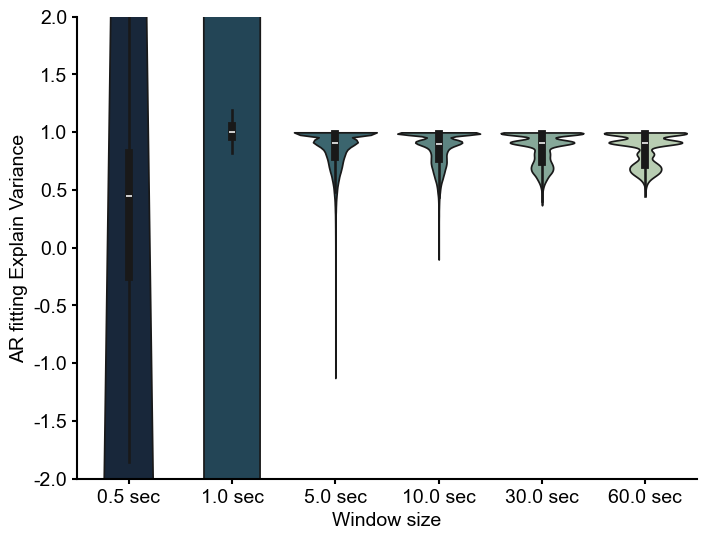

Number of animals per condition:
win5: 6 animals
win10: 6 animals
win50: 6 animals
win100: 6 animals
win300: 6 animals
win600: 6 animals

Pairwise comparisons (Wilcoxon signed-rank if paired):
win5 vs win10 (Wilcoxon): p = 0
win5 vs win50 (Wilcoxon): p = 0
win5 vs win100 (Wilcoxon): p = 1.842e-194
win5 vs win300 (Wilcoxon): p = 0
win5 vs win600 (Wilcoxon): p = 6.2e-264
win10 vs win50 (Wilcoxon): p = 0
win10 vs win100 (Wilcoxon): p = 0
win10 vs win300 (Wilcoxon): p = 0
win10 vs win600 (Wilcoxon): p = 0
win50 vs win100 (Wilcoxon): p = 0
win50 vs win300 (Wilcoxon): p = 1.198e-268
win50 vs win600 (Wilcoxon): p = 1.184e-151
win100 vs win300 (Wilcoxon): p = 1.955e-06
win100 vs win600 (Wilcoxon): p = 3.616e-65
win300 vs win600 (Wilcoxon): p = 1.284e-53


In [3]:
import scipy.io as sio
import numpy as np
import re
import matplotlib.pyplot as plt
import os, re, pickle, glob
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
import matplotlib as mpl
# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# Load the dataset (update the filename as needed)
file_path = r'D:\Documents\GitHub\R_Project\PPP\codebook\Criticality_analysis\ddc\data\coarse_grain_bin_explore\20250324timebin_grainedmouse.mat'
mat_data = sio.loadmat(file_path, squeeze_me=True, struct_as_record=False)

# Exclude MATLAB's default keys (like __header__, __version__, __globals__)
all_field_names = [key for key in mat_data.keys() if not key.startswith('__')]

# Group data by window size into a dictionary
groupData = {}  # keys like 'win5', 'win600', etc.
for field_name in all_field_names:
    # Extract window_size using regex
    m = re.search(r'win(\d+)', field_name)
    if m is None:
        continue  # skip if no match
    window_size = int(m.group(1))
    fieldKey = f'win{window_size}'
    
    # Group the data into lists. Each entry corresponds to one animal.
    if fieldKey not in groupData:
        groupData[fieldKey] = [mat_data[field_name]]
    else:
        groupData[fieldKey].append(mat_data[field_name])

# Prepare pooled explain_variance data for the boxplot.
# We'll also build a list of group labels corresponding to each data point.
allData = []       # list of explain_variance values
groupLabels = []   # list of labels (same length as allData)

# Also create a dictionary to hold the group-wise explain_variance (for boxplot input)
group_values_dict = {}

for key in groupData:
    group_values = []  # explain_variance values for this condition
    for animalData in groupData[key]:
        # animalData is a struct or array of structs with attribute 'explain_variance'; normalize to a list
        if not hasattr(animalData, '__iter__'):
            animalData = [animalData]
        else:
            # if animalData is a numpy.ndarray, we convert it to a list.
            if isinstance(animalData, np.ndarray):
                animalData = animalData.tolist()

        for entry in animalData:
            # explain_variance may be an attribute or a dict key depending on how the struct loaded
            try:
                # Try attribute first
                ev = entry.explain_variance
            except AttributeError:
                # If not an attribute, try dictionary access
                ev = entry['explain_variance']
            # Ensure ev is a numpy array (flatten if needed)
            ev = np.array(ev).flatten()
            group_values.extend(ev.tolist())
    
    group_values = np.array(group_values)
    group_values_dict[key] = group_values
    allData.extend(group_values.tolist())
    groupLabels.extend([key]*len(group_values))

# Create converted labels: e.g., 'win5' becomes '0.5 sec'
fields_order = list(groupData.keys())  # original condition order (order is arbitrary in a dict)
convertedLabels = {}
for key in fields_order:
    m = re.search(r'win(\d+)', key)
    if m:
        numeric_val = int(m.group(1))
        converted_time = numeric_val / 10.0
        convertedLabels[key] = f"{converted_time:.1f} sec"
    else:
        convertedLabels[key] = key

# For boxplot, create a list of data arrays in the order of the conditions
boxplot_data = []
xlabels = []
for key in sorted(groupData.keys(), key=lambda x: int(re.search(r'\d+', x).group())):
    boxplot_data.append(group_values_dict[key])
    xlabels.append(convertedLabels[key])

# Custom teal palette
teal_palette = [
    '#122740',  # Teal 6 (original last)
    '#1b485e',  # Teal 5
    '#326b77',  # Teal 4
    '#568b87',  # Teal 3
    '#80ae9a',  # Teal 2
    '#b5d1ae'   # Teal 1 (original first)
]


plot_df = pd.DataFrame({
    "ExplainVariance": np.concatenate(boxplot_data),
    "Window": np.repeat(xlabels, [len(d) for d in boxplot_data])
})

# --- Create violin plot ---
fig, ax = plt.subplots(figsize=(8, 6))
sns.violinplot(
    data=plot_df,
    x="Window",
    y="ExplainVariance",
    palette=teal_palette[:len(xlabels)],
    cut=0,          # don't extend violins beyond min/max
    inner="box",    # draw mini boxplot inside violin
    ax=ax
)

# Style
ax.set_xlabel("Window size")
ax.set_ylabel("AR fitting Explain Variance")
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.ylim([-2, 2])
save_path=r'D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\figS1B_explain_variance_violin_diff_window.svg'
plt.savefig(save_path, format='svg', dpi=300)
plt.show()
print("Number of animals per condition:")
for key in sorted(groupData.keys(), key=lambda x: int(re.search(r'\d+', x).group())):
    num_animals = len(groupData[key])
    print(f"{key}: {num_animals} animals")
from itertools import combinations
from scipy.stats import wilcoxon, mannwhitneyu

print("\nPairwise comparisons (Wilcoxon signed-rank if paired):")
keys_sorted = sorted(group_values_dict.keys(), key=lambda x: int(re.search(r'\d+', x).group()))

for k1, k2 in combinations(keys_sorted, 2):
    vals1 = group_values_dict[k1]
    vals2 = group_values_dict[k2]

    # If the same animals appear in both, a paired Wilcoxon signed-rank test applies.
    # If not, fallback to Mann-Whitney U (independent).
    try:
        stat, pval = wilcoxon(vals1[:len(vals2)], vals2[:len(vals1)])
        test_name = "Wilcoxon"
    except ValueError:  # unequal sizes etc.
        stat, pval = mannwhitneyu(vals1, vals2, alternative="two-sided")
        test_name = "Mann-Whitney U"
    
    print(f"{k1} vs {k2} ({test_name}): p = {pval:.4g}")

C.Uncertainty


✅ Used 12 files; skipped 0.
tile
1    11152
2     8641
3     7892
4     8268
5     7956
6     6913
Name: count_by_tile, dtype: int64

📊 Linear trend on pooled means (Ripple rate quantiles (low → high)):
   R² = 0.942, p = 0.001
   counts per tile:
 tile
1    12
2    12
3    12
4    12
5    12
6    12
Figure saved to D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\S1_C_ripple_rate_by_d2_tile_pooled.svg


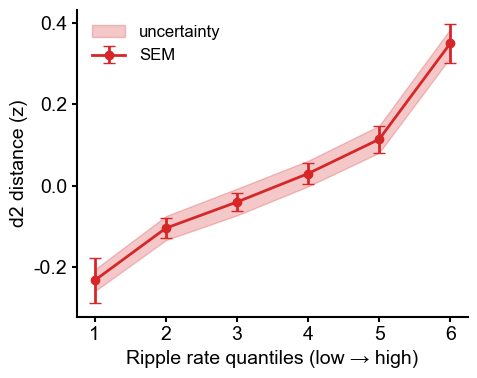


✅ Used 12 files; skipped 0.
tile
1    8852
2    8374
3    8436
4    8408
5    8313
6    8439
Name: count_by_tile, dtype: int64

📊 Linear trend on pooled means (Barrage rate quantiles (low → high)):
   R² = 0.974, p = 2.59e-04
   counts per tile:
 tile
1    12
2    12
3    12
4    12
5    12
6    12
Figure saved to D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\S1_C_barrage_rate_by_d2_tile_pooled.svg


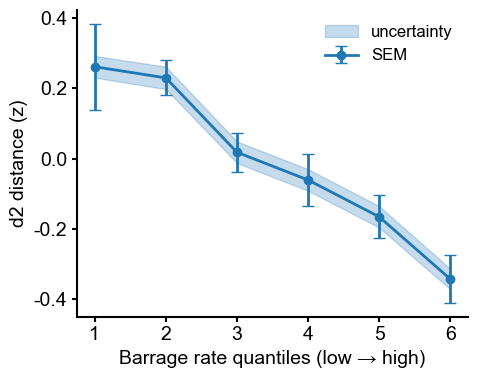

In [172]:
import os, pickle
import numpy as np
import pandas as pd
from scipy.stats import sem, linregress
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path # Added Path
import matplotlib as mpl
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

# Make mathtext look like Arial
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Arial'
mpl.rcParams['mathtext.it'] = 'Arial:italic'
mpl.rcParams['mathtext.bf'] = 'Arial:bold' 

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# ==========================
import numpy as np
import pandas as pd
from pathlib import Path
import pickle

# -------------------------------------------------
# Helper: force sextiles (or k-tiles) 1..k
# -------------------------------------------------
def _force_sextiles(series, k=6):
    """
    Return Int64 tiles 1..k. Try qcut; if it yields <k bins, fall back to
    rank-based qcut that still returns k bins when N>=k. If N<k -> all NA.
    """
    s = pd.to_numeric(series, errors="coerce")
    s = s.replace([np.inf, -np.inf], np.nan)

    # 1) Try ordinary quantile sextiles
    try:
        t = pd.qcut(s, q=k, labels=False, duplicates="drop")
        if pd.Series(t).nunique(dropna=True) == k:
            return t.astype("Int64") + 1
    except Exception:
        pass

    # 2) Fallback: rank-based sextiles (equal-count by rank)
    rk = s.rank(method="first")
    if rk.notna().sum() >= k:
        t = pd.qcut(rk, q=k, labels=False)
        return t.astype("Int64") + 1

    # 3) Not enough rows to form k bins
    return pd.Series(pd.NA, index=s.index, dtype="Int64")


# -------------------------------------------------
# Main loader
# -------------------------------------------------
def load_pool_rate_binned(
    pkl_dir,
    rate_col,                 # "ripple_rate_hz" or "barrage_rate_hz"
    d2_col="d2",              # D2 column name in source file
    d2_err_col="d2_err",      # D2 error column name in source file
    state="NREM",
    n_bins=6,
    min_bins_required=2,      # skip a file if effective bins < min_bins_required
):
    pooled = []
    n_files_used = 0
    n_files_skipped = 0
    
    # Use Path to handle directory
    pkl_dir = Path(pkl_dir)

    for file_path in pkl_dir.glob("*.pkl"):
        try:
            with open(file_path, "rb") as f:
                # Load the entire pickled object
                data_obj = pickle.load(f)

            # Try to find the dataframe, assuming it might be in a dict
            df = None
            if isinstance(data_obj, pd.DataFrame):
                df = data_obj
            elif isinstance(data_obj, dict):
                # Check for common keys
                if "ca1_complete_df" in data_obj:
                    df = data_obj["ca1_complete_df"]
                elif "df" in data_obj:
                    df = data_obj["df"]
                
            if df is None or len(df) == 0:
                print(f"⚠️ Skipped {file_path.name} (no usable DataFrame)")
                n_files_skipped += 1
                continue

            # state filter
            if "state" not in df.columns:
                print(f"⚠️ Skipped {file_path.name} (no 'state' column)")
                n_files_skipped += 1
                continue
                
            df = df[df["state"] == state].copy()
            if df.empty:
                print(f"⚠️ Skipped {file_path.name} (no {state} rows)")
                n_files_skipped += 1
                continue

            # keep only needed cols, drop NaNs
            need = [d2_col, rate_col]
            has_d2err = d2_err_col in df.columns
            if has_d2err:
                need.append(d2_err_col)
            
            if not set(need).issubset(df.columns):
                missing = set(need) - set(df.columns)
                print(f"⚠️ Skipped {file_path.name} (missing {missing})")
                n_files_skipped += 1
                continue
                
            df = df[need].dropna()
            if df.empty:
                print(f"⚠️ Skipped {file_path.name} (NaNs after subset)")
                n_files_skipped += 1
                continue

            # z-normalize D² within this file
            d2_mean = df[d2_col].mean()
            d2_std = df[d2_col].std(ddof=0)  # Use ddof=0 for population std
            
            if d2_std == 0 or np.isnan(d2_std):
                print(f"⚠️ Skipped {file_path.name} (zero/NaN std of d2)")
                n_files_skipped += 1
                continue
                
            df["d2_norm"] = (df[d2_col] - d2_mean) / d2_std
            
            # Normalize the d2_err as well
            if has_d2err:
                df["d2_err_norm"] = df[d2_err_col] / d2_std
            else:
                df["d2_err_norm"] = np.nan  # Ensure column exists

            # -------------------------------------------------
            # per-file RATE bins using forced sextiles 1..n_bins
            # -------------------------------------------------
            df["tile"] = _force_sextiles(df[rate_col], k=n_bins)

            # how many unique bins for this file (ignoring NA)?
            n_uniq = df["tile"].nunique(dropna=True)
            if n_uniq < min_bins_required:
                print(f"⚠️ Skipped {file_path.name} (effective bins = {n_uniq})")
                n_files_skipped += 1
                continue

            # attach file id & metadata
            file_id = file_path.stem
            df["file_id"] = file_id
            df["state"] = state
            df["rate_col"] = rate_col

            cols_to_pool = [
                "file_id", "state", "rate_col",
                "d2_norm", "d2_err_norm",
                rate_col, "tile"
            ]
            pooled.append(df[cols_to_pool])
            n_files_used += 1

        except Exception as e:
            print(f"❌ Failed to process {file_path.name}: {e}")
            n_files_skipped += 1

    if not pooled:
        raise ValueError("No usable data loaded after per-file binning.")

    pooled_df = pd.concat(pooled, ignore_index=True)
    print(f"\n✅ Used {n_files_used} files; skipped {n_files_skipped}.")
    # Show per-tile counts (pooled)
    print(pooled_df.groupby("tile")["d2_norm"].count().rename("count_by_tile"))
    return pooled_df


def plot_d2_by_rate_tile_pooled(
    pooled_df, 
    n_bins=6, 
    title=None, 
    color="tab:blue",
    save_path=None,
    d2_norm_col="d2_norm",
    d2_err_col_norm="d2_err_norm"
):
    # Keep only tiles within 1..n_bins (some files may have fewer bins)
    df = pooled_df.copy()
    df = df[df["tile"].between(1, n_bins, inclusive='both')]

    # Check if we have propagated error data
    has_d2err = d2_err_col_norm in df.columns and df[d2_err_col_norm].notna().any()

    # aggregate across files within each tile
    grp = df.groupby("tile")[d2_norm_col]
    grp_err = df.groupby("tile")[d2_err_col_norm]
    
    means = grp.mean()
    errs_sem = grp.apply(sem) # SEM (across-sample variability)
    counts = grp.size()
    file_col = "file_id"

    df = pooled_df.copy()
    df = df[df["tile"].between(1, n_bins, inclusive="both")]

    has_d2err = d2_err_col_norm in df.columns and df[d2_err_col_norm].notna().any()

    # ---------- per-(tile, file) means ----------
    per_file = (
        df.groupby(["tile", file_col])[d2_norm_col]
        .mean()
        .reset_index()
    )

    # group over files within each tile
    grp = per_file.groupby("tile")[d2_norm_col]

    # cross-file mean and SEM
    means     = grp.mean()                         # mean across files
    errs_sem  = grp.apply(sem, nan_policy="omit")  # SEM across files
    counts    = grp.size()                         # number of files per tile

    # --- Calculate Propagated Error ---
# ---------- per-(tile, file) stats ----------
    # We calculate the mean D2 AND the propagated error for that specific file/tile
    
    def calc_file_propagated_error(x_err):
        # Formula: sqrt(sum(sigma^2)) / N
        if len(x_err) == 0:
            return np.nan
        return np.sqrt(np.nansum(x_err**2)) / len(x_err)

    per_file = (
        df.groupby(["tile", file_col])
        .agg({
            d2_norm_col: "mean",
            d2_err_col_norm: calc_file_propagated_error  # Calc error for this file
        })
        .rename(columns={d2_norm_col: "mean_d2", d2_err_col_norm: "prop_err"})
        .reset_index()
    )

    # ---------- cross-file stats ----------
    grp = per_file.groupby("tile")

    # 1. The Line Plot: Mean across files
    means = grp["mean_d2"].mean()

    # 2. The Error Bars: Biological Variability (SEM across files)
    errs_sem = grp["mean_d2"].apply(sem, nan_policy="omit")

    # 3. The Shaded Region: Average Measurement Uncertainty
    # We simply average the measurement errors of the files to show "typical" uncertainty
    if has_d2err:
        propagated_err = grp["prop_err"].mean() 
    else:
        propagated_err = pd.Series(0, index=means.index)
    # ---------------------------------------------
    
    # linear trend on aggregated means (tile index 1..n_bins)
    xs = means.index.astype(int).values
    lr = linregress(xs, means.values)
    r2 = lr.rvalue ** 2
    p = lr.pvalue

    # pretty p
    if p < 1e-45:
        p_str = "p < 1e-45"
    elif p < 0.001:
        p_str = f"p = {p:.2e}"
    else:
        p_str = f"p = {p:.3f}"


    print(f"\n📊 Linear trend on pooled means ({title}):")
    print(f"   R² = {r2:.3f}, {p_str}")
    print("   counts per tile:\n", counts.to_string())

    # plot
    plt.figure(figsize=(5,4))
    ax = plt.gca()
    
    # --- Plot Shaded Band ---
    if has_d2err:
        lower = means.values - propagated_err.values
        upper = means.values + propagated_err.values
        ax.fill_between(xs, lower, upper, alpha=0.25, color=color, 
                        label="uncertainty")
    # -----------------------------

    # Plot SEM whiskers
    plt.errorbar(xs, means.values, yerr=errs_sem.values, fmt='-o', capsize=4, 
                 color=color, linewidth=2, label="SEM")
                 
    plt.legend(frameon=False, fontsize=12)

    plt.xticks(xs)
    # Use title for x-axis, get y-label from rate_col
    rate_name = df["rate_col"].iloc[0].replace("_rate_hz", "").replace("_"," ").capitalize()
    plt.ylabel("d2 distance (z)")
    plt.xlabel(title)
    sns.despine()
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()

    if save_path:
        # Ensure save directory exists
        save_dir = Path(save_path).parent
        save_dir.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=300)
        print(f"Figure saved to {save_path}")
        
    plt.show()

# --- 3. Run Analysis ---
pkl_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\d2_uncertainty"

# Define save directory for figures
save_fig_dir = Path(r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary")
save_fig_dir.mkdir(parents=True, exist_ok=True)


# Ripple: per-file quantile binning, then pool
try:
    df_ripple_pooled = load_pool_rate_binned(
        pkl_dir, 
        rate_col="ripple_rate_hz", 
        d2_col="d2",        # Column name in source file
        d2_err_col="d2_err",  # Error column name in source file
        state="NREM", 
        n_bins=6
    )
    
    plot_d2_by_rate_tile_pooled(
        df_ripple_pooled, 
        n_bins=6,
        title="Ripple rate quantiles (low → high)",
        color="tab:red",
        d2_norm_col="d2_norm",       # Column to plot (z-scored)
        d2_err_col_norm="d2_err_norm", # Column for shaded band (z-scored)
        save_path=save_fig_dir / "S1_C_ripple_rate_by_d2_tile_pooled.svg"
    )
except ValueError as e:
    print(f"Could not process ripple data: {e}")


# Barrage: per-file quantile binning, then pool
try:
    df_barrage_pooled = load_pool_rate_binned(
        pkl_dir, 
        rate_col="barrage_rate_hz", 
        d2_col="d2",
        d2_err_col="d2_err",
        state="NREM", 
        n_bins=6
    )
    
    plot_d2_by_rate_tile_pooled(
        df_barrage_pooled, 
        n_bins=6,
        title="Barrage rate quantiles (low → high)",
        color="tab:blue",
        d2_norm_col="d2_norm",
        d2_err_col_norm="d2_err_norm",
        save_path=save_fig_dir / "S1_C_barrage_rate_by_d2_tile_pooled.svg"
    )
except ValueError as e:
    print(f"Could not process barrage data: {e}")


✅ Used 12 files; skipped 0.
tile
1    11152
2     8641
3     7892
4     8268
5     7956
6     6913
Name: count_by_tile, dtype: int64

📊 Linear trend on pooled means (Ripple rate quantiles (low → high)):
   R² = 0.942, p = 0.001
   counts per tile:
 tile
1    12
2    12
3    12
4    12
5    12
6    12
Figure saved to D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\S1_C_ripple_rate_by_d2_tile_pooled_std.svg


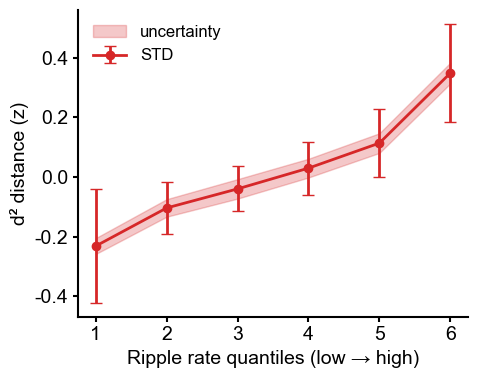


✅ Used 12 files; skipped 0.
tile
1    8852
2    8374
3    8436
4    8408
5    8313
6    8439
Name: count_by_tile, dtype: int64

📊 Linear trend on pooled means (Barrage rate quantiles (low → high)):
   R² = 0.974, p = 2.59e-04
   counts per tile:
 tile
1    12
2    12
3    12
4    12
5    12
6    12
Figure saved to D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\S1_C_barrage_rate_by_d2_tile_pooled_std.svg


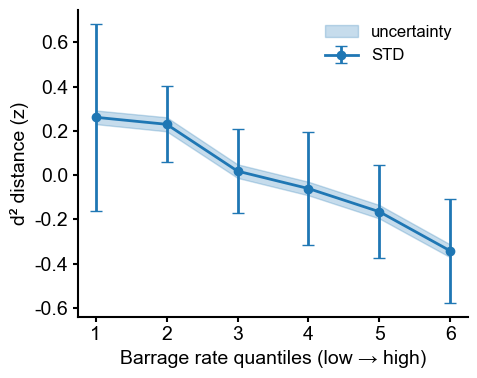

In [173]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import sem, linregress
import seaborn as sns


def plot_d2_by_rate_tile_pooled(
    pooled_df, 
    n_bins=6, 
    title=None, 
    color="tab:blue",
    save_path=None,
    d2_norm_col="d2_norm",
    d2_err_col_norm="d2_err_norm",   # column with per-event d2 uncertainty (already normalized)
    err_type="std",                  # "sem" (default) or "std" for cross-file variability
):
    """
    Plot pooled d² vs rate tiles across files, with:
      - Line: mean d² per tile across files
      - Whiskers: SEM or STD across files (err_type)
      - Shaded band: average propagated measurement error per tile

    pooled_df must contain columns:
      - "tile"        : integer tile index (1..n_bins)
      - "file_id"     : file identifier
      - d2_norm_col   : normalized d² values
      - d2_err_col_norm (optional): per-event uncertainty on d² (same units as d2_norm_col)
      - "rate_col"    : string with the rate variable name (for x-label)
    """

    # -----------------------------
    # 0) Filter tiles that exist
    # -----------------------------
    df = pooled_df.copy()
    df = df[df["tile"].between(1, n_bins, inclusive="both")]

    if df.empty:
        print("[WARN] No data after filtering tiles 1..n_bins")
        return

    file_col = "file_id"   # change here if using another column name for file identity

    has_d2err = d2_err_col_norm in df.columns and df[d2_err_col_norm].notna().any()

    # -----------------------------
    # 1) per-(tile, file) stats
    # -----------------------------
    def calc_file_propagated_error(x_err):
        """
        Propagated error for one (tile, file) group:
        sqrt(sum(sigma_i^2)) / N
        """
        x_err = np.asarray(x_err, float)
        x_err = x_err[np.isfinite(x_err)]
        if x_err.size == 0:
            return np.nan
        return np.sqrt(np.nansum(x_err**2)) / x_err.size

    g = df.groupby(["tile", file_col])

    mean_d2 = g[d2_norm_col].mean()

    if has_d2err:
        prop_err = g[d2_err_col_norm].apply(calc_file_propagated_error)
    else:
        # no measurement error available
        prop_err = pd.Series(np.nan, index=mean_d2.index)

    per_file = pd.DataFrame({
        "tile":   mean_d2.index.get_level_values("tile"),
        "file_id": mean_d2.index.get_level_values(file_col),
        "mean_d2": mean_d2.values,
        "prop_err": prop_err.values,
    })

    # -----------------------------
    # 2) cross-file stats per tile
    # -----------------------------
    grp = per_file.groupby("tile")

    # 1. line = mean across files
    means = grp["mean_d2"].mean()

    # 2. whiskers = SEM or STD across files
    if err_type.lower() == "std":
        errs = grp["mean_d2"].std()  # NaN-robust by default
        err_label = "STD"
    else:
        errs = grp["mean_d2"].apply(sem, nan_policy="omit")
        err_label = "SEM"

    counts = grp.size()

    # 3. shaded band = average measurement uncertainty
    if has_d2err:
        propagated_err = grp["prop_err"].mean()
    else:
        propagated_err = pd.Series(0.0, index=means.index)

    # -----------------------------
    # 3) linear trend on tile index
    # -----------------------------
    xs = means.index.astype(int).values
    if len(xs) >= 2:
        lr = linregress(xs, means.values)
        r2 = lr.rvalue ** 2
        p = lr.pvalue

        if p < 1e-45:
            p_str = "p < 1e-45"
        elif p < 0.001:
            p_str = f"p = {p:.2e}"
        else:
            p_str = f"p = {p:.3f}"

        print(f"\n📊 Linear trend on pooled means ({title}):")
        print(f"   R² = {r2:.3f}, {p_str}")
    else:
        print("\n[INFO] Not enough tiles for linear regression.")

    print("   counts per tile:\n", counts.to_string())

    # -----------------------------
    # 4) plotting
    # -----------------------------
    plt.figure(figsize=(5, 4))
    ax = plt.gca()

    # shaded band for typical measurement uncertainty
    if has_d2err:
        lower = means.values - propagated_err.values
        upper = means.values + propagated_err.values
        ax.fill_between(
            xs, lower, upper,
            alpha=0.25,
            color=color,
            label="uncertainty"
        )

    # SEM or STD whiskers
    plt.errorbar(
        xs, means.values,
        yerr=errs.values,
        fmt='-o',
        capsize=4,
        color=color,
        linewidth=2,
        label=err_label
    )

    plt.xticks(xs)

    # x-label: from rate_col
    if "rate_col" in df.columns and len(df["rate_col"].dropna()) > 0:
        rate_name = (
            df["rate_col"].iloc[0]
            .replace("_rate_hz", "")
            .replace("_", " ")
            .capitalize()
        )
    else:
        rate_name = "Rate tile"

    plt.ylabel("d² distance (z)")
    plt.xlabel(rate_name if title is None else title)

    sns.despine()
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.legend(frameon=False, fontsize=12)
    plt.tight_layout()

    if save_path:
        save_dir = Path(save_path).parent
        save_dir.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=300)
        print(f"Figure saved to {save_path}")

    plt.show()
try:
    df_ripple_pooled = load_pool_rate_binned(
        pkl_dir, 
        rate_col="ripple_rate_hz", 
        d2_col="d2",        # Column name in source file
        d2_err_col="d2_err",  # Error column name in source file
        state="NREM", 
        n_bins=6
    )
    
    plot_d2_by_rate_tile_pooled(
        df_ripple_pooled, 
        n_bins=6,
        title="Ripple rate quantiles (low → high)",
        color="tab:red",
        d2_norm_col="d2_norm",       # Column to plot (z-scored)
        d2_err_col_norm="d2_err_norm", # Column for shaded band (z-scored)
        save_path=save_fig_dir / "S1_C_ripple_rate_by_d2_tile_pooled_std.svg"
    )
except ValueError as e:
    print(f"Could not process ripple data: {e}")


# Barrage: per-file quantile binning, then pool
try:
    df_barrage_pooled = load_pool_rate_binned(
        pkl_dir, 
        rate_col="barrage_rate_hz", 
        d2_col="d2",
        d2_err_col="d2_err",
        state="NREM", 
        n_bins=6
    )
    
    plot_d2_by_rate_tile_pooled(
        df_barrage_pooled, 
        n_bins=6,
        title="Barrage rate quantiles (low → high)",
        color="tab:blue",
        d2_norm_col="d2_norm",
        d2_err_col_norm="d2_err_norm",
        save_path=save_fig_dir / "S1_C_barrage_rate_by_d2_tile_pooled_std.svg"
    )
except ValueError as e:
    print(f"Could not process barrage data: {e}")


✅ Used 12 files; skipped 0.
tile
1    11152
2     8641
3     7892
4     8268
5     7956
6     6913
Name: count_by_tile, dtype: int64

📊 Linear trend on pooled means (Ripple rate quantiles (low → high)):
   OLS (unweighted): slope=0.09884, SE≈0.01245, R²=0.940, p=0.001
   WLS[SEM]:        slope=0.09587, SE=0.01193, R²=0.942, p=0.001
   WLS[prop.err]:   slope=0.09549, SE=0.01143, R²=0.946, p=0.001
   counts per tile:
 tile
1    11152
2     8641
3     7892
4     8268
5     7956
6     6913


C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\838683172.py:173: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
C:\Users\Cornell\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.


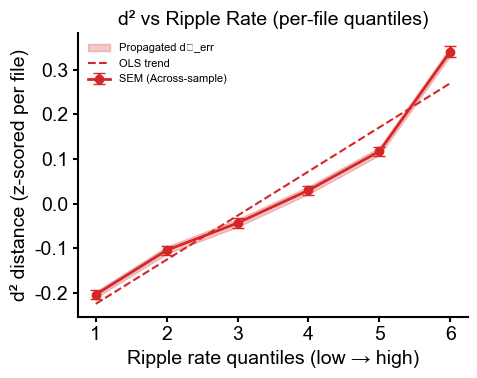


✅ Used 12 files; skipped 0.
tile
1    8852
2    8374
3    8436
4    8408
5    8313
6    8439
Name: count_by_tile, dtype: int64

📊 Linear trend on pooled means (Barrage rate quantiles (low → high)):
   OLS (unweighted): slope=-0.1319, SE≈0.004896, R²=0.995, p=1.13e-05
   WLS[SEM]:        slope=-0.1329, SE=0.004812, R²=0.995, p=1.02e-05
   WLS[prop.err]:   slope=-0.1322, SE=0.004829, R²=0.995, p=1.06e-05
   counts per tile:
 tile
1    8852
2    8374
3    8436
4    8408
5    8313
6    8439


C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\838683172.py:173: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
C:\Users\Cornell\AppData\Roaming\Python\Python311\site-packages\IPython\core\pylabtools.py:152: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.


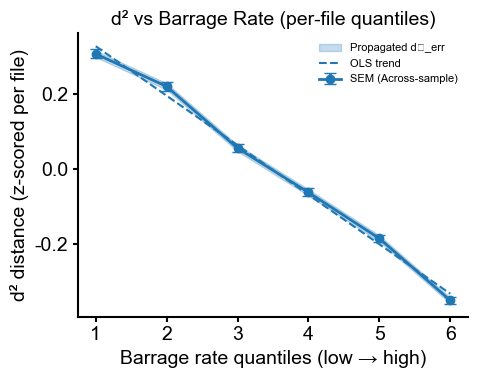

In [175]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from scipy.stats import linregress, t as t_dist, sem

# --- Helper: Weighted least squares (WLS) slope test ---
def _wls_trend(x, y, sigma):
    """
    Weighted linear regression y ~ a + b*x with weights w = 1/sigma^2.
    Returns dict with slope, intercept, their SEs, t, p, and weighted R^2.
    sigma: per-point standard errors (same units as y). If None or invalid, returns None.
    """
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    if sigma is None:
        return None
    sigma = np.asarray(sigma, float)

    # valid points: finite and positive sigma
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(sigma) & (sigma > 0)
    if ok.sum() < 3:
        return None

    x = x[ok]; y = y[ok]; sigma = sigma[ok]
    w = 1.0 / (sigma**2)

    # Weighted means
    W = w.sum()
    xw = np.sum(w * x) / W
    yw = np.sum(w * y) / W

    # Weighted slope and intercept
    Sxx = np.sum(w * (x - xw)**2)
    if Sxx <= 0:
        return None
    b = np.sum(w * (x - xw) * (y - yw)) / Sxx
    a = yw - b * xw

    # Residuals and weighted residual variance
    yhat = a + b * x
    # For WLS with known sigmas, an unbiased variance estimate uses weights:
    # SSE = sum(w * (y - yhat)^2); df = n - 2
    n = x.size
    df = n - 2
    if df <= 0:
        return None
    SSE = np.sum(w * (y - yhat)**2)
    # Variance of slope:
    var_b = SSE / df / Sxx
    se_b = np.sqrt(var_b)

    # t-test for slope != 0
    t_stat = b / se_b if se_b > 0 else np.nan
    p_val = 2 * (1 - t_dist.cdf(np.abs(t_stat), df=df))

    # Weighted R^2 (pseudo): 1 - (weighted SSE / weighted SST)
    SST = np.sum(w * (y - yw)**2)
    R2 = 1 - (SSE / SST) if SST > 0 else np.nan

    return {
        "slope": b, "intercept": a,
        "se_slope": se_b, "t": t_stat, "p": p_val, "r2": R2, "n": n, "df": df
    }
def plot_d2_by_rate_tile_pooled(
    pooled_df, 
    n_bins=6, 
    title=None, 
    color="tab:blue",
    save_path=None,
    d2_norm_col="d2_norm",
    d2_err_col_norm="d2_err_norm"  # used for propagated band and WLS(propagated)
):
    # Keep only tiles within 1..n_bins (some files may have fewer bins)
    df = pooled_df.copy()
    df = df[df["tile"].between(1, n_bins, inclusive='both')]

    # Do we have per-sample uncertainty?
    has_d2err = d2_err_col_norm in df.columns and df[d2_err_col_norm].notna().any()

    # Aggregate across files within each tile
    grp = df.groupby("tile")[d2_norm_col]
    grp_err = df.groupby("tile")[d2_err_col_norm] if has_d2err else None

    means = grp.mean()
    errs_sem = grp.apply(sem)                 # SEM of the *pooled samples*
    counts = grp.size()

    # --- Propagated band from per-sample d2_err_norm (same units as d2_norm) ---
    if has_d2err:
        propagated_err = grp_err.apply(
            lambda x_err: np.sqrt(np.nansum(x_err**2)) / len(x_err) if len(x_err) > 0 else np.nan
        )
    else:
        propagated_err = pd.Series(np.nan, index=means.index)
        print("Note: No d2_err data found. Skipping propagated shaded band.")

    # --- Linear trend tests on aggregated means vs tile index ---
    xs = means.index.astype(int).values
    ys = means.values

    # (A) Unweighted OLS (same as before)
    lr = linregress(xs, ys)
    r2_ols = lr.rvalue ** 2
    p_ols = lr.pvalue

    # (B) WLS using SEM as sigma
    sem_sigmas = errs_sem.values
    wls_sem = _wls_trend(xs, ys, sem_sigmas)

    # (C) WLS using propagated d2_err as sigma
    prop_sigmas = propagated_err.values
    wls_prop = _wls_trend(xs, ys, prop_sigmas)

    # Pretty-print stats
    print(f"\n📊 Linear trend on pooled means ({title}):")
    print(f"   OLS (unweighted): slope={lr.slope:.4g}, SE≈{(lr.stderr or np.nan):.4g}, R²={r2_ols:.3f}, "
          f"p={'<1e-45' if p_ols < 1e-45 else (f'{p_ols:.2e}' if p_ols < 0.001 else f'{p_ols:.3f}')}")
    if wls_sem is not None:
        p = wls_sem["p"]
        print(f"   WLS[SEM]:        slope={wls_sem['slope']:.4g}, SE={wls_sem['se_slope']:.4g}, "
              f"R²={wls_sem['r2']:.3f}, p={'<1e-45' if p < 1e-45 else (f'{p:.2e}' if p < 0.001 else f'{p:.3f}')}")
    else:
        print("   WLS[SEM]:        insufficient/invalid SEM to compute.")

    if wls_prop is not None:
        p = wls_prop["p"]
        print(f"   WLS[prop.err]:   slope={wls_prop['slope']:.4g}, SE={wls_prop['se_slope']:.4g}, "
              f"R²={wls_prop['r2']:.3f}, p={'<1e-45' if p < 1e-45 else (f'{p:.2e}' if p < 0.001 else f'{p:.3f}')}")
    else:
        print("   WLS[prop.err]:   insufficient/invalid propagated errors to compute.")

    print("   counts per tile:\n", counts.to_string())

    # --- Plot ---
    plt.figure(figsize=(5,4))
    ax = plt.gca()

    # Shaded propagated band
    if has_d2err and np.isfinite(propagated_err.values).any():
        lower = ys - propagated_err.values
        upper = ys + propagated_err.values
        ax.fill_between(xs, lower, upper, alpha=0.25, color=color, label="Propagated d₂_err")

    # Mean ± SEM whiskers
    plt.errorbar(xs, ys, yerr=errs_sem.values, fmt='-o', capsize=4,
                 color=color, linewidth=2, label="SEM (Across-sample)")

    # Optional: overlay OLS fit line for reference
    y_fit = lr.intercept + lr.slope * xs
    plt.plot(xs, y_fit, linestyle="--", linewidth=1.5, label="OLS trend", color=color)

    plt.legend(frameon=False, fontsize=8)
    plt.xticks(xs)

    # Labeling
    try:
        rate_name = df["rate_col"].iloc[0].replace("_rate_hz", "").replace("_"," ").capitalize()
    except Exception:
        rate_name = "Rate"
    plt.xlabel(title or "Rate quantiles (low → high)")
    plt.ylabel("d² distance (z-scored per file)")
    plt.title(f"d² vs {rate_name} Rate (per-file quantiles)")

    # Style
    try:
        import seaborn as sns
        sns.despine()
    except Exception:
        pass
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()

    if save_path:
        save_dir = Path(save_path).parent
        save_dir.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=300)
        print(f"Figure saved to {save_path}")

    plt.show()
# Barrage: per-file quantile binning, then pool
# Ripple: per-file quantile binning, then pool
try:
    df_ripple_pooled = load_pool_rate_binned(
        pkl_dir, 
        rate_col="ripple_rate_hz", 
        d2_col="d2",        # Column name in source file
        d2_err_col="d2_err",  # Error column name in source file
        state="NREM", 
        n_bins=6
    )
    
    plot_d2_by_rate_tile_pooled(
        df_ripple_pooled, 
        n_bins=6,
        title="Ripple rate quantiles (low → high)",
        color="tab:red",
        d2_norm_col="d2_norm",       # Column to plot (z-scored)
        d2_err_col_norm="d2_err_norm", # Column for shaded band (z-scored)
        save_path=None
    )
except ValueError as e:
    print(f"Could not process ripple data: {e}")

try:
    df_barrage_pooled = load_pool_rate_binned(
        pkl_dir, 
        rate_col="barrage_rate_hz", 
        d2_col="d2",
        d2_err_col="d2_err",
        state="NREM", 
        n_bins=6
    )
    
    plot_d2_by_rate_tile_pooled(
        df_barrage_pooled, 
        n_bins=6,
        title="Barrage rate quantiles (low → high)",
        color="tab:blue",
        d2_norm_col="d2_norm",
        d2_err_col_norm="d2_err_norm",
        save_path=None
    )
except ValueError as e:
    print(f"Could not process barrage data: {e}")
import statsmodels.formula.api as smf
import statsmodels.api as sm
from sklearn.metrics import r2_score
import numpy as np
import pandas as pd



📊 Linear trend on pooled means (Ripple rate quantiles (low → high)):
   OLS (unweighted): slope=0.09884, SE≈0.01245, R²=0.940, p=0.001
   WLS[STD]:   slope=0.09841, SE=0.01275, R²=0.937, p=0.002
   WLS[prop.err]:   slope=0.09549, SE=0.01143, R²=0.946, p=0.001
   counts per tile:
 tile
1    11152
2     8641
3     7892
4     8268
5     7956
6     6913


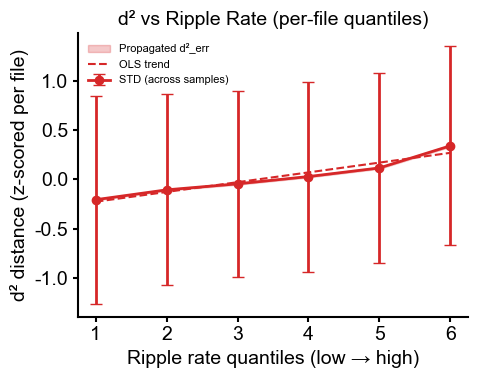


📊 Linear trend on pooled means (Barrage rate quantiles (low → high)):
   OLS (unweighted): slope=-0.1319, SE≈0.004896, R²=0.995, p=1.13e-05
   WLS[STD]:   slope=-0.1331, SE=0.004828, R²=0.995, p=1.03e-05
   WLS[prop.err]:   slope=-0.1322, SE=0.004829, R²=0.995, p=1.06e-05
   counts per tile:
 tile
1    8852
2    8374
3    8436
4    8408
5    8313
6    8439


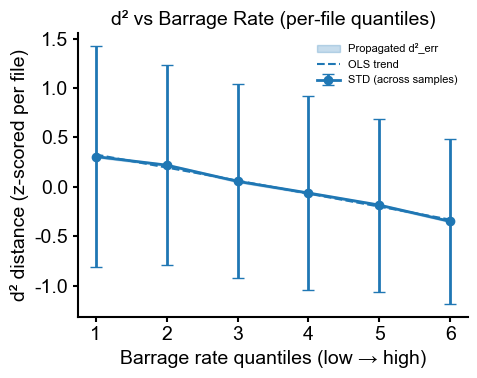

In [176]:
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from scipy.stats import linregress, t as t_dist, sem

# --- Helper: Weighted least squares (WLS) slope test ---
def _wls_trend(x, y, sigma):
    """
    Weighted linear regression y ~ a + b*x with weights w = 1/sigma^2.
    Returns dict with slope, intercept, their SEs, t, p, and weighted R^2.
    sigma: per-point standard errors (same units as y). If None or invalid, returns None.
    """
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    if sigma is None:
        return None
    sigma = np.asarray(sigma, float)

    # valid points: finite and positive sigma
    ok = np.isfinite(x) & np.isfinite(y) & np.isfinite(sigma) & (sigma > 0)
    if ok.sum() < 3:
        return None

    x = x[ok]; y = y[ok]; sigma = sigma[ok]
    w = 1.0 / (sigma**2)

    # Weighted means
    W = w.sum()
    xw = np.sum(w * x) / W
    yw = np.sum(w * y) / W

    # Weighted slope and intercept
    Sxx = np.sum(w * (x - xw)**2)
    if Sxx <= 0:
        return None
    b = np.sum(w * (x - xw) * (y - yw)) / Sxx
    a = yw - b * xw

    # Residuals and weighted residual variance
    yhat = a + b * x
    n = x.size
    df = n - 2
    if df <= 0:
        return None
    SSE = np.sum(w * (y - yhat)**2)

    # Variance of slope:
    var_b = SSE / df / Sxx
    se_b = np.sqrt(var_b)

    # t-test for slope != 0
    t_stat = b / se_b if se_b > 0 else np.nan
    p_val = 2 * (1 - t_dist.cdf(np.abs(t_stat), df=df))

    # Weighted R^2 (pseudo): 1 - (weighted SSE / weighted SST)
    SST = np.sum(w * (y - yw)**2)
    R2 = 1 - (SSE / SST) if SST > 0 else np.nan

    return {
        "slope": b, "intercept": a,
        "se_slope": se_b, "t": t_stat, "p": p_val, "r2": R2, "n": n, "df": df
    }


def plot_d2_by_rate_tile_pooled(
    pooled_df, 
    n_bins=6, 
    title=None, 
    color="tab:blue",
    save_path=None,
    d2_norm_col="d2_norm",
    d2_err_col_norm="d2_err_norm",  # used for propagated band and WLS(propagated)
    err_type="sem",                 # "sem" or "std" for across-sample variability
):
    # Keep only tiles within 1..n_bins (some files may have fewer bins)
    df = pooled_df.copy()
    df = df[df["tile"].between(1, n_bins, inclusive='both')]

    if df.empty:
        print("[WARN] No data in selected tiles.")
        return

    # Do we have per-sample uncertainty?
    has_d2err = d2_err_col_norm in df.columns and df[d2_err_col_norm].notna().any()

    # Aggregate across samples within each tile
    grp = df.groupby("tile")[d2_norm_col]
    if has_d2err:
        grp_err = df.groupby("tile")[d2_err_col_norm]
    else:
        grp_err = None

    means = grp.mean()
    errs_sem = grp.apply(sem)        # SEM of the *pooled samples*
    errs_std = grp.std(ddof=1)       # STD of the pooled samples

    # choose which to use
    if err_type.lower() == "std":
        errs = errs_std
        sigma_label = "STD"
    else:
        errs = errs_sem
        sigma_label = "SEM"

    counts = grp.size()

    # --- Propagated band from per-sample d2_err_norm (same units as d2_norm) ---
    if has_d2err:
        propagated_err = grp_err.apply(
            lambda x_err: np.sqrt(np.nansum(np.asarray(x_err, float)**2)) / len(x_err)
            if len(x_err) > 0 else np.nan
        )
    else:
        import pandas as pd
        propagated_err = pd.Series(np.nan, index=means.index)
        print("Note: No d2_err data found. Skipping propagated shaded band.")

    # --- Linear trend tests on aggregated means vs tile index ---
    xs = means.index.astype(int).values
    ys = means.values

    # (A) Unweighted OLS (same as before)
    lr = linregress(xs, ys)
    r2_ols = lr.rvalue ** 2
    p_ols = lr.pvalue

    # (B) WLS using chosen across-sample variability (SEM or STD) as sigma
    sigmas = errs.values
    wls_sigma = _wls_trend(xs, ys, sigmas)

    # (C) WLS using propagated d2_err as sigma
    prop_sigmas = propagated_err.values
    wls_prop = _wls_trend(xs, ys, prop_sigmas)

    # Pretty-print stats
    print(f"\n📊 Linear trend on pooled means ({title}):")
    print(
        "   OLS (unweighted): "
        f"slope={lr.slope:.4g}, SE≈{(lr.stderr or np.nan):.4g}, "
        f"R²={r2_ols:.3f}, "
        f"p={'<1e-45' if p_ols < 1e-45 else (f'{p_ols:.2e}' if p_ols < 0.001 else f'{p_ols:.3f}')}"
    )

    if wls_sigma is not None:
        p = wls_sigma["p"]
        print(
            f"   WLS[{sigma_label}]:   "
            f"slope={wls_sigma['slope']:.4g}, SE={wls_sigma['se_slope']:.4g}, "
            f"R²={wls_sigma['r2']:.3f}, "
            f"p={'<1e-45' if p < 1e-45 else (f'{p:.2e}' if p < 0.001 else f'{p:.3f}')}"
        )
    else:
        print(f"   WLS[{sigma_label}]:   insufficient/invalid sigma to compute.")

    if wls_prop is not None:
        p = wls_prop["p"]
        print(
            "   WLS[prop.err]:   "
            f"slope={wls_prop['slope']:.4g}, SE={wls_prop['se_slope']:.4g}, "
            f"R²={wls_prop['r2']:.3f}, "
            f"p={'<1e-45' if p < 1e-45 else (f'{p:.2e}' if p < 0.001 else f'{p:.3f}')}"
        )
    else:
        print("   WLS[prop.err]:   insufficient/invalid propagated errors to compute.")

    print("   counts per tile:\n", counts.to_string())

    # --- Plot ---
    plt.figure(figsize=(5,4))
    ax = plt.gca()

    # Shaded propagated band
    if has_d2err and np.isfinite(propagated_err.values).any():
        lower = ys - propagated_err.values
        upper = ys + propagated_err.values
        ax.fill_between(
            xs, lower, upper,
            alpha=0.25,
            color=color,
            label="Propagated d²_err"
        )

    # Mean ± chosen whisker (SEM or STD)
    plt.errorbar(
        xs, ys,
        yerr=errs.values,
        fmt='-o', capsize=4,
        color=color, linewidth=2,
        label=f"{sigma_label} (across samples)"
    )

    # Optional: overlay OLS fit line for reference
    y_fit = lr.intercept + lr.slope * xs
    plt.plot(xs, y_fit, linestyle="--", linewidth=1.5,
             label="OLS trend", color=color)

    plt.legend(frameon=False, fontsize=8)
    plt.xticks(xs)

    # Labeling
    try:
        rate_name = df["rate_col"].iloc[0].replace("_rate_hz", "").replace("_"," ").capitalize()
    except Exception:
        rate_name = "Rate"
    plt.xlabel(title or "Rate quantiles (low → high)")
    plt.ylabel("d² distance (z-scored per file)")
    plt.title(f"d² vs {rate_name} Rate (per-file quantiles)")

    # Style
    try:
        import seaborn as sns
        sns.despine()
    except Exception:
        pass
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    plt.tight_layout()

    if save_path:
        save_dir = Path(save_path).parent
        save_dir.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=300)
        print(f"Figure saved to {save_path}")

    plt.show()


plot_d2_by_rate_tile_pooled(
    df_ripple_pooled,
    n_bins=6,
    title="Ripple rate quantiles (low → high)",
    color="tab:red",
    d2_norm_col="d2_norm",
    d2_err_col_norm="d2_err_norm",
    err_type="std",   # use STD for whiskers + WLS
)
plot_d2_by_rate_tile_pooled(
    df_barrage_pooled,
    n_bins=6,
    title="Barrage rate quantiles (low → high)",
    color="tab:blue",
    d2_norm_col="d2_norm",
    d2_err_col_norm="d2_err_norm",
    err_type="std",   # use STD for whiskers + WLS
)

S1_C SNR uncertainty


[CA1] pooled rows: 282816
   state window       n
0  AWAKE    30s  107598
1  AWAKE    60s   29589
2   NREM    30s  110682
3   NREM    60s   31562
4    REM    30s    2939
5    REM    60s     446
Saved: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\S2_E_CA1_snr_box_30s_vs_60s.svg


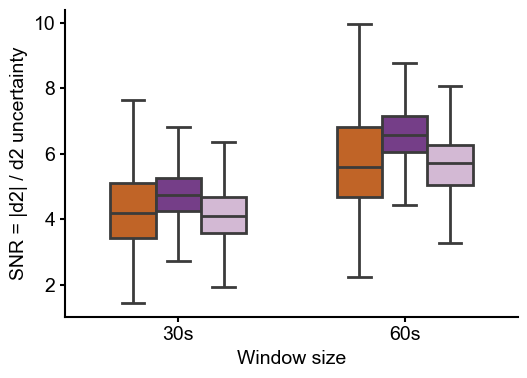


🔹 Running two-way ANOVA on 282816 SNR samples ...

📊 ANOVA results (state × window):
                           sum_sq        df              F         PR(>F)
C(state)             21355.794407       2.0   10000.346873   0.000000e+00
C(window)           136601.664318       1.0  127933.805748   0.000000e+00
C(state):C(window)    1469.623278       2.0     688.185243  7.077391e-299
Residual            301971.136244  282810.0            NaN            NaN

🔹 Paired state comparisons per session (animal × day):

Window = 30s
  AWAKE vs NREM: n=24, p=0.000278
  NREM vs REM:  n=19, p=0.00021

Window = 60s
  AWAKE vs NREM: n=20, p=0.000322
  NREM vs REM:  n=15, p=0.00427

🔹 Paired comparison of window length (30s vs 60s, across all states):
  30s vs 60s: n=20, p=1.91e-06


In [1]:
import os, re, glob
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib as mpl
# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# ------------------ Helpers ------------------
def _load_mat_any(mat_path):
    from scipy.io import loadmat
    try:
        return loadmat(mat_path, squeeze_me=True, struct_as_record=False, simplify_cells=True)
    except TypeError:
        return loadmat(mat_path, squeeze_me=True, struct_as_record=False)
    except NotImplementedError:
        import mat73
        return mat73.loadmat(mat_path)

def _to_1d_array(x):
    if x is None:
        return np.array([], dtype=float)
    arr = np.asarray(x, dtype=object)
    if arr.ndim == 0:
        return np.atleast_1d(arr).astype(float, copy=False)
    try:
        return np.asarray(arr).ravel().astype(float, copy=False)
    except (ValueError, TypeError):
        return np.array([float(v) for v in np.ravel(arr)], dtype=float)

def _to_state_str(s):
    try:
        if isinstance(s, (bytes, bytearray)):
            return s.decode('utf-8', 'ignore')
        if isinstance(s, str):
            return s
        arr = np.asarray(s)
        if arr.ndim == 0:
            return str(arr.item())
        return ''.join(arr.tolist()) if arr.dtype.kind in ('U','S') else str(arr)
    except Exception:
        return str(s)

# Reuse: _load_mat_any, _to_1d_array, _to_state_str, _infer_animal_day_from_path

def _extract_d2_and_err_by_state_from_mat(mat_path, region=None, animal=None, day=None):
    """
    Extract both d2 and d2_err pooled by state.
    Returns DataFrame with columns: state, d2, d2_err, region, animal, day
    (Rows are per-window; missing d2_err become NaN.)
    """
    mat = _load_mat_any(mat_path)
    results = mat.get('results', None)
    if results is None:
        return pd.DataFrame(columns=["state","d2","d2_err","region","animal","day"])

    if isinstance(results, dict):
        iter_results = list(results.values())
    else:
        iter_results = list(results if isinstance(results, (list, tuple)) else np.atleast_1d(results))

    rows = []
    for it in iter_results:
        if hasattr(it, 'get'):
            st = _to_state_str(it.get('state', 'UNKNOWN'))
            d2_raw = it.get('d2', [])
            d2err_raw = it.get('d2_err', [])
        elif isinstance(it, dict) or hasattr(it, '__getitem__'):
            st = _to_state_str(it.get('state', it['state'] if 'state' in it else 'UNKNOWN'))
            d2_raw = it.get('d2', it['d2'] if 'd2' in it else [])
            d2err_raw = it.get('d2_err', it['d2_err'] if 'd2_err' in it else [])
        else:
            st, d2_raw, d2err_raw = 'UNKNOWN', [], []

        d2_vals = _to_1d_array(d2_raw)
        d2_vals = d2_vals[np.isfinite(d2_vals)]
        if d2_vals.size == 0:
            continue

        d2_err = _to_1d_array(d2err_raw)
        d2_err = d2_err[np.isfinite(d2_err)] if d2_err.size else np.array([], float)

        st_up = st.upper()
        if st_up == "WAKE":
            st_up = "AWAKE"
        if st_up not in ("NREM", "AWAKE", "REM"):
            continue

        # Align lengths if both present; otherwise, pad err with NaN
        n = d2_vals.size
        if d2_err.size >= n:
            d2_err = d2_err[:n]
        elif d2_err.size == 0:
            d2_err = np.full(n, np.nan)
        else:
            # rare mismatch; trim both to min
            m = min(n, d2_err.size)
            d2_vals = d2_vals[:m]
            d2_err = d2_err[:m]

        rows.append(pd.DataFrame({
            "state": st_up,
            "d2": d2_vals,
            "d2_err": d2_err,
            "region": region if region else "",
            "animal": animal if animal else "",
            "day": day if day is not None else ""
        }))

    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame(
        columns=["state","d2","d2_err","region","animal","day"]
    )

def _infer_animal_day_from_path(basepath):
    base = os.path.basename(basepath.rstrip("\\/"))
    # try ...\PPP20\day4 or ...\NN2\day24 etc.
    animal = os.path.basename(os.path.dirname(basepath))
    mday = re.search(r"day(\d+)", base, flags=re.I)
    day = int(mday.group(1)) if mday else None
    return animal, day
def load_d2_and_err_30s_60s_from_session(basepath, region):
    """
    For a single basepath+region, load newest 30s and 60s files and return
    pooled d2 and d2_err with a 'window' column ∈ {'30s','60s'}.
    """
    region = region.upper()
    search_dir = Path(basepath) / "complex_system"
    if not search_dir.exists():
        return pd.DataFrame(columns=["state","d2","d2_err","window","region","animal","day"])

    pats = {
        "30s": f"*_{region}_D2_time_resolved_error_bar.mat",
        "60s": f"*_{region}_D2_time_resolved_error_bar_60sec.mat",
    }
    animal, day = _infer_animal_day_from_path(basepath)
    out = []
    for win_label, pat in pats.items():
        files = glob.glob(str(search_dir / pat))
        if not files:
            continue
        mat_path = max(files, key=os.path.getmtime)
        df = _extract_d2_and_err_by_state_from_mat(mat_path, region=region, animal=animal, day=day)
        if df.empty:
            continue
        df["window"] = win_label
        out.append(df)

    return pd.concat(out, ignore_index=True) if out else pd.DataFrame(
        columns=["state","d2","d2_err","window","region","animal","day"]
    )

def plot_box_by_window(df, ycol, region, title=None, save_path=None, zscore_per_session=False):
    """
    Generic box plot for ycol ∈ {'d2','d2_err'} comparing 30s vs 60s per state.
    If zscore_per_session=True and ycol=='d2', d2 is z-scored within (animal, day, window, state).
    """
    if df.empty:
        print(f"[{region}] No data to plot for {ycol}.")
        return

    order = ["NREM", "AWAKE", "REM"]
    df = df[df["state"].isin(order)].copy()
    df["state"] = pd.Categorical(df["state"], categories=order, ordered=True)

    data = df.copy()
    if zscore_per_session and ycol == "d2":
        # z-score d2 within session-window-state to reduce across-session scale differences
        def _zs(g):
            v = g[ycol].values
            m, s = np.nanmean(v), np.nanstd(v, ddof=0)
            if not np.isfinite(s) or s == 0:
                return pd.Series(np.zeros_like(v), index=g.index)
            return pd.Series((v - m) / s, index=g.index)
        data[ycol + "_z"] = data.groupby(["animal","day","window","state"], observed=True).apply(_zs).reset_index(level=[0,1,2,3], drop=True)
        ycol_plot = ycol + "_z"
        ylab = f"{ycol} (z-scored per session/window/state)"
    else:
        ycol_plot = ycol
        ylab = ycol

    plt.figure(figsize=(7,4))
    ax = sns.boxplot(data=data, x="state", y=ycol_plot, hue="window",
                     showcaps=True, width=0.7, boxprops=dict(alpha=0.8))
    sns.despine()
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_xlabel("State")
    ax.set_ylabel(ylab if ycol != "d2_err" else "d² uncertainty (d2_err)")
    ax.set_title(title or f"{region}: {ycol} (30s vs 60s)")
    ax.legend(title="Window", frameon=False)
    plt.tight_layout()
    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=300)
        print(f"Saved: {save_path}")
    plt.show()
paths = [
    r"W:\data\PPP\PPP20\day4",
    r"W:\data\PPP\PPP20\day5",
    r"W:\data\PPP\PPP20\day7",
    r"W:\data\PPP\PPP20\day8",
    r"W:\data\PPP\PPP21\day7",
    r"W:\data\PPP\PPP21\day8",
    r"W:\data\PPP\PPP21\day5",
    r"W:\data\PPP\PPP21\day4",
    r"W:\data\PPP\PPP8\day8",
    r"W:\data\PPP\PPP4\day11",
    r"W:\data\PPP\PPP7\day7",
    r"W:\data\PPP\PPP7\day10",
    r"W:\data\PPP\PPP23\day7",
    r"W:\data\PPP\PPP23\day8",
    r"X:\data\Barrage\NN8\day7",
    r"X:\data\Barrage\NN3\day15",
    r"X:\data\Barrage\NN2\day24",
    r"X:\data\Barrage\NN2\day10",
    r"W:\data\PPP\CA2\PPP7\day12",
    r"X:\data\Barrage\NN2\day10_3",
    r"X:\data\Barrage\NN3\day12",
    r"X:\data\Barrage\NN3\day16",
    r"X:\data\Barrage\NN3\day25",
    r"X:\data\Barrage\NN8\day6",
    r"X:\data\Barrage\NN16\day13",
]
# === Main pooling across all sessions ===
regions = ["CA1"]
pooled_all = {reg: [] for reg in regions}
missing = []

for basepath in paths:
    for reg in regions:
        try:
            df_session = load_d2_and_err_30s_60s_from_session(basepath, reg)
            if not df_session.empty:
                pooled_all[reg].append(df_session)
            else:
                missing.append((basepath, reg))
        except Exception as e:
            print(f"⚠️ {reg} @ {basepath}: {e}")
            missing.append((basepath, reg))

save_root = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary"
for reg in regions:
    if not pooled_all[reg]:
        print(f"\n[{reg}] No data found across all sessions.")
        continue

    df_reg = pd.concat(pooled_all[reg], ignore_index=True)
    # Quick counts
    print(f"\n[{reg}] pooled rows: {len(df_reg)}")
    print(df_reg.groupby(["state","window"]).size().rename("n").reset_index())

    # # --- Plot d2_err (uncertainty) as before ---
    # plot_box_by_window(
    #     df_reg, ycol="d2_err", region=reg,
    #     title=f"{reg}: d² uncertainty (30s vs 60s)",
    #     save_path=os.path.join(save_root, f"{reg}_d2err_box_30s_vs_60s.svg")
    # )

    # # --- Plot d2 itself (raw) ---
    # plot_box_by_window(
    #     df_reg, ycol="d2", region=reg,
    #     title=f"{reg}: d² (30s vs 60s, pooled)",
    #     save_path=os.path.join(save_root, f"{reg}_d2_box_30s_vs_60s_raw.svg"),
    #     zscore_per_session=False   # True: per-session normalization
    # )
# ---------- SNR helpers ----------
def add_snr(df, eps=1e-12):
    """Add SNR = |d2| / (d2_err + eps). Leaves existing columns untouched."""
    d = df.copy()
    if "d2_err" not in d.columns or "d2" not in d.columns:
        raise KeyError("DataFrame must contain 'd2' and 'd2_err' columns to compute SNR.")
    d["snr"] = np.abs(d["d2"]) / (np.asarray(d["d2_err"]) + eps)
    # cleanup non-finite
    d.loc[~np.isfinite(d["snr"]), "snr"] = np.nan
    return d

def plot_snr_by_window(df, region, title=None, save_path=None, log10=False):
    """
    Box plot of SNR comparing sleep states (NREM/AWAKE/REM) within each window (30s vs 60s).
    x-axis = window (30s, 60s), hue = state.
    """
    if df.empty:
        print(f"[{region}] No data to plot for SNR.")
        return

    order_states = ["NREM", "AWAKE", "REM"]
    order_windows = ["30s", "60s"]

    d = df[df["state"].isin(order_states) & df["window"].isin(order_windows)].copy()
    if d.empty:
        print(f"[{region}] No valid rows for SNR plotting.")
        return
    d["state"] = pd.Categorical(d["state"], categories=order_states, ordered=True)
    d["window"] = pd.Categorical(d["window"], categories=order_windows, ordered=True)

    ycol = "snr"
    ylabel = "SNR = |d2| / d2 uncertainty"
    if log10:
        d[ycol] = np.clip(d[ycol].values, 1e-12, np.inf)
        d["log10_snr"] = np.log10(d[ycol].values)
        ycol = "log10_snr"
        ylabel = "log10 SNR"

    plt.figure(figsize=(5.5, 4))

    palette = {
    "AWAKE": "#d95f0e",  # green
    "NREM":  "#7b3294",  # blue
    "REM":  "#d7b5d8",  # red
     }
    order_states = ["AWAKE","NREM",  "REM"]
    ax = sns.boxplot(
        data=d,
        x="window",          # window on x-axis
        y=ycol,
        hue="state",         # states as hue groups
        showcaps=True,
        boxprops=dict(alpha=1),
        hue_order=order_states,
        palette=palette,
        showfliers=False,
        width=0.6,
        linewidth=2
    )

    sns.despine()
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("Window size")
    leg = ax.get_legend()
    if leg is not None:
        leg.remove()   # or: leg.set_visible(False)
    plt.tight_layout()

    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(save_path, dpi=300)
        print(f"Saved: {save_path}")

    plt.show()


def summarize_snr(df):
    """
    Print quick summary stats for SNR per state x window:
    median, IQR, and fraction SNR<1.
    """
    d = df.dropna(subset=["snr"]).copy()
    if d.empty:
        print("No finite SNR to summarize.")
        return
    grp = d.groupby(["state","window"])
    summary = grp["snr"].agg(
        n="size",
        median=np.median,
        q25=lambda x: np.quantile(x, 0.25),
        q75=lambda x: np.quantile(x, 0.75),
        frac_snr_lt1=lambda x: np.mean(np.asarray(x) < 1.0)
    ).reset_index()
    print("\nSNR summary (per state × window):")
    print(summary.to_string(index=False))
    return summary


# --- Compute and plot SNR ---
df_reg_snr = add_snr(df_reg)

# Linear SNR
plot_snr_by_window(
    df_reg_snr, region=reg,
    title=f"{reg}: SNR (30s vs 60s)",
    save_path=os.path.join(save_root, f"S2_E_{reg}_snr_box_30s_vs_60s.svg"),
    log10=False
)

import pingouin as pg   # clean, statsmodels-based ANOVA lib
import statsmodels.api as sm
from statsmodels.formula.api import ols
import pingouin as pg
import statsmodels.api as sm
from statsmodels.formula.api import ols

from scipy.stats import ttest_ind

from scipy.stats import wilcoxon

from scipy.stats import wilcoxon

def run_anova_snr(df):
    """
    Two-way ANOVA on SNR with factors:
        - state (NREM / AWAKE / REM)
        - window (30s / 60s)
    
    PLUS paired comparisons across sessions (animal × day):

      (A) Within each window:
          - AWAKE vs NREM
          - NREM vs REM

      (B) Across windows (pooling all states):
          - 30s vs 60s (per-session mean over states)
    """
    # ---------------------------------------
    # 1. Basic cleanup
    # ---------------------------------------
    d = df.dropna(subset=["snr"]).copy()

    # filters
    d = d[d["state"].isin(["NREM", "AWAKE", "REM"])]
    d = d[d["window"].isin(["30s", "60s"])]

    if d.empty:
        print("No valid SNR data for ANOVA.")
        return None, None

    # Session identity = animal × day
    d["session"] = d["animal"].astype(str) + "_" + d["day"].astype(str)

    print(f"\n🔹 Running two-way ANOVA on {len(d)} SNR samples ...")

    # ---------------------------------------
    # 2. Two-way ANOVA (state × window)
    # ---------------------------------------
    model = ols("snr ~ C(state) * C(window)", data=d).fit()
    table = sm.stats.anova_lm(model, typ=2)

    print("\n📊 ANOVA results (state × window):")
    print(table)

    # ---------------------------------------
    # 3. Paired state comparisons per window
    # ---------------------------------------
    print("\n🔹 Paired state comparisons per session (animal × day):")

    pairwise_rows = []

    for win in sorted(d["window"].unique()):
        print(f"\nWindow = {win}")

        dw = d[d["window"] == win].copy()

        # Per session × state mean SNR
        pivot = (
            dw.groupby(["session", "state"])["snr"]
              .mean()
              .unstack("state")
        )

        # AWAKE vs NREM
        if {"AWAKE", "NREM"}.issubset(pivot.columns):
            x = pivot["AWAKE"]
            y = pivot["NREM"]
            mask = x.notna() & y.notna()
            if mask.sum() > 1:
                stat, p = wilcoxon(x[mask], y[mask])
                print(f"  AWAKE vs NREM: n={mask.sum()}, p={p:.3g}")
                pairwise_rows.append(
                    {"type": "state",
                     "window": win,
                     "contrast": "AWAKE vs NREM",
                     "p": p,
                     "n": mask.sum()}
                )
            else:
                print("  AWAKE vs NREM: insufficient paired samples.")

        # NREM vs REM
        if {"NREM", "REM"}.issubset(pivot.columns):
            x = pivot["NREM"]
            y = pivot["REM"]
            mask = x.notna() & y.notna()
            if mask.sum() > 1:
                stat, p = wilcoxon(x[mask], y[mask])
                print(f"  NREM vs REM:  n={mask.sum()}, p={p:.3g}")
                pairwise_rows.append(
                    {"type": "state",
                     "window": win,
                     "contrast": "NREM vs REM",
                     "p": p,
                     "n": mask.sum()}
                )
            else:
                print("  NREM vs REM: insufficient paired samples.")

    # ---------------------------------------
    # 4. Paired comparison of window length (30s vs 60s),
    #    pooling across states
    # ---------------------------------------
    print("\n🔹 Paired comparison of window length (30s vs 60s, across all states):")

    # Per session × window mean SNR (averaged over all states)
    pivot_win = (
        d.groupby(["session", "window"])["snr"]
          .mean()
          .unstack("window")
    )

    if {"30s", "60s"}.issubset(pivot_win.columns):
        x = pivot_win["30s"]
        y = pivot_win["60s"]
        mask = x.notna() & y.notna()
        if mask.sum() > 1:
            stat, p = wilcoxon(x[mask], y[mask])
            print(f"  30s vs 60s: n={mask.sum()}, p={p:.3g}")
            pairwise_rows.append(
                {"type": "window",
                 "window": "all_states",
                 "contrast": "30s vs 60s",
                 "p": p,
                 "n": mask.sum()}
            )
        else:
            print("  30s vs 60s: insufficient paired samples.")
    else:
        print("  30s vs 60s: not both windows present.")

    pairwise_df = pd.DataFrame(pairwise_rows) if pairwise_rows else None

    return table, pairwise_df


df_reg_snr = add_snr(df_reg)

anova_table, pairwise_df = run_anova_snr(df_reg_snr)

S1_E

C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\1771173591.py:109: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(
C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\1771173591.py:109: FutureWarning: 

The `scale` parameter has been renamed and will be removed in v0.15.0. Pass `density_norm='width'` for the same effect.
  sns.violinplot(


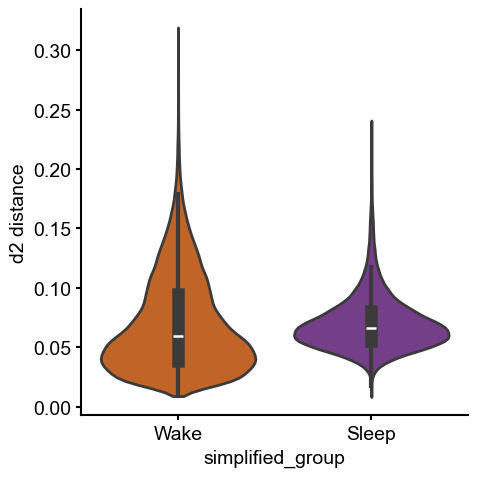

N=110134  groups=11 (pairs=11)  scope=within
Δ rank (Wake−Sleep) = -0.0603 (on 0–1 rank scale)  95% CI [-0.0638, -0.0568]  p=5.23e-246
Returned p-value (rank-LMM): 5.230869806014322e-246


c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2054: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2245: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values

In [ ]:

import matplotlib as mpl
# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# Directory
data_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\cross_state\mice_d2"

# Collect all pickle files
pkl_files = [f for f in os.listdir(data_dir) if f.endswith(".pkl")]

# Storage
all_data = []

for f in pkl_files:
    file_path = os.path.join(data_dir, f)
    with open(file_path, "rb") as handle:
        data = pickle.load(handle)
        
        # Add region label and metadata - ONLY CA1
        if "box_df_ca1" in data:
            df_ca1 = data["box_df_ca1"].copy()
            df_ca1["region"] = "CA1"
            df_ca1["animal"] = data.get("ca1_complete_meta", {}).get("animal_name", f)
            df_ca1["day"] = data.get("ca1_complete_meta", {}).get("day", "unknown")
            all_data.append(df_ca1)

# Combine all CA1 data only
combined_df = pd.concat(all_data, ignore_index=True)

import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# (Optional) fix the display order of the state groups
group_order = ["Wake θ", "Wake non-θ", "NREM", "REM"]
if set(group_order).issuperset(set(combined_df["group"].unique())):
    combined_df["group"] = pd.Categorical(combined_df["group"], categories=group_order, ordered=True)

# Combine all CA1 data only
combined_df = pd.concat(all_data, ignore_index=True)

# (Optional) fix the display order of the state groups
group_order = ["Wake θ", "Wake non-θ", "NREM", "REM"]
if set(group_order).issuperset(set(combined_df["group"].unique())):
    combined_df["group"] = pd.Categorical(combined_df["group"], categories=group_order, ordered=True)


# Plot 2: Simplified Wake vs Sleep grouping
# Create simplified grouping
combined_df_simplified = combined_df.copy()
combined_df_simplified['simplified_group'] = combined_df_simplified['group'].map({
    'Wake θ': 'Wake',
    'Wake non-θ': 'Wake',
    'NREM': 'Sleep',
    'REM': 'Sleep'
})

combined_df_simplified = combined_df_simplified.dropna(subset=['simplified_group'])

import seaborn as sns

# ---------- FIGURE 2: Simplified Wake vs Sleep ----------
# ---------- FIGURE 2: Simplified Wake vs Sleep (violin with custom colors) ----------
fig2, ax2 = plt.subplots(figsize=(5, 5))
order2   = ['Wake', 'Sleep']
palette2 = {'Wake': '#d95f0e', 'Sleep': '#7b3294'}  # custom colors

sns.violinplot(
    data=combined_df_simplified,
    x="simplified_group", y="d2",
    order=order2, ax=ax2,
    palette=palette2,
    cut=0,              # don't extend beyond data range
    scale='width',      # same width per group
    inner='box',        # show median & IQR inside
    linewidth=2
)

ax2.set_ylabel("d2 distance")
ax2.grid(False)
# remove top & right frame lines
for s in ("top", "right"):
    ax2.spines[s].set_visible(False)

# also stop ticks on those sides (optional)
ax2.tick_params(top=False, right=False)

# # n annotations
# counts2 = combined_df_simplified.groupby('simplified_group').size()
# y0, y1 = ax2.get_ylim()
# for i, g in enumerate(order2):
#     if g in counts2.index:
#         ax2.text(i, y0 - 0.05*(y1 - y0), f"n={counts2[g]}",
#                  ha='center', va='top', fontweight='bold')
# Annotate sample sizes below each violin
save_path = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\S1_E_wake_sleep.svg"
fig2.savefig(save_path, dpi=300, bbox_inches='tight')
plt.tight_layout()
plt.show()
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy import stats

def wake_vs_sleep_rank_p(model_df, scope='within', normalize=True):
    """
    Rank-transform LMM: d2_rank ~ simplified_group + (1|animal_day).
    scope: 'within'  -> rank within animal_day (recommended)
           'global'  -> rank across all rows
    normalize: if True, convert ranks to ~[0,1] (mid-ranks scaled), so beta is on a 0-1 scale.
    Returns p-value for Wake−Sleep.
    """
    # prep
    df = (model_df
          .dropna(subset=['d2','simplified_group','animal','day'])
          .assign(animal_day=lambda x: x['animal'].astype(str)+'_'+x['day'].astype(str))
          .copy())
    df['simplified_group'] = pd.Categorical(df['simplified_group'], ['Sleep','Wake'])

    # rank transform
    if scope == 'within':
        # mid-ranks within subject/day
        df['d2_rank'] = df.groupby('animal_day')['d2'].rank(method='average')
        if normalize:
            n_per = df.groupby('animal_day')['d2'].transform('size')
            df['d2_rank'] = (df['d2_rank'] - 0.5) / n_per   # ≈ in (0,1)
    elif scope == 'global':
        df['d2_rank'] = df['d2'].rank(method='average')
        if normalize:
            n = len(df)
            df['d2_rank'] = (df['d2_rank'] - 0.5) / n
    else:
        raise ValueError("scope must be 'within' or 'global'")

    # fit LMM on ranks
    try:
        res = smf.mixedlm("d2_rank ~ simplified_group", data=df, groups=df["animal_day"]).fit(method='lbfgs')
        beta = res.params['simplified_group[T.Wake]']
        p    = res.pvalues['simplified_group[T.Wake]']
        ci   = res.conf_int().loc['simplified_group[T.Wake]'].to_numpy()
        n_groups = df['animal_day'].nunique()
        n_pairs  = (df.groupby('animal_day')['simplified_group'].nunique()==2).sum()

        scale_note = " (on 0–1 rank scale)" if normalize else " (rank units)"
        print(f"N={len(df)}  groups={n_groups} (pairs={n_pairs})  scope={scope}")
        print(f"Δ rank (Wake−Sleep) = {beta:.4f}{scale_note}  95% CI [{ci[0]:.4f}, {ci[1]:.4f}]  p={p:.3g}")
        return p
    except Exception as e:
        print(f"Rank-LMM failed: {e}\n→ Falling back to paired Wilcoxon on per-animal_day medians.")
        piv = (df.pivot_table(index='animal_day', columns='simplified_group',
                              values='d2', aggfunc='median').dropna())
        if len(piv) >= 2:
            stat, p = stats.wilcoxon(piv['Wake'], piv['Sleep'])
            print(f"Wilcoxon: n={len(piv)}, W={stat:.0f}, p={p:.3g}, median diff={np.median(piv['Wake']-piv['Sleep']):.4f}")
            return p
        else:
            print("Not enough paired animal_day entries for Wilcoxon.")
            return np.nan

pval_rank = wake_vs_sleep_rank_p(combined_df_simplified, scope='within', normalize=True)
print("Returned p-value (rank-LMM):", pval_rank)

S1_F EMG

C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\3348417565.py:173: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(sub["emg_tile"]):
C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\3348417565.py:173: DeprecationWarning: is_categorical_dtype is deprecated and will be removed in a future version. Use isinstance(dtype, pd.CategoricalDtype) instead
  if pd.api.types.is_categorical_dtype(sub["emg_tile"]):


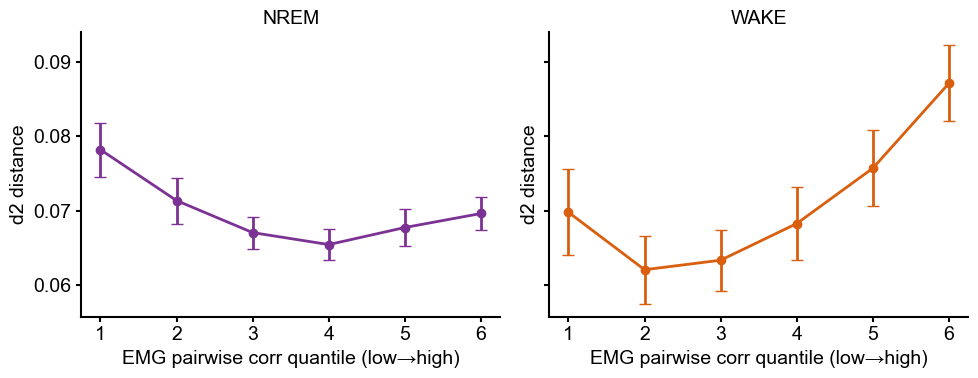

NREM: mean slope = -0.00158 (n=11 files), one-sample t vs 0 → p = 0.0893
NREM: mean Spearman ρ = -0.2571 (n=11 files), t vs 0 → p = 0.196
WAKE: mean slope = 0.003783 (n=11 files), one-sample t vs 0 → p = 0.004
WAKE: mean Spearman ρ = 0.5325 (n=11 files), t vs 0 → p = 0.00114
NREM mixed model: beta(tile_idx) = -0.001446, p = 4.78e-157
WAKE mixed model: beta(tile_idx) = 0.00447, p = 0


c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects covariance is singular
  warnings.warn(msg)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2054: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2245: UserWarning: The random effects covariance matrix is singular.
  warnings.warn(_warn_cov_sing)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:2261: ConvergenceWarning: The Hessian matrix at the estimated parameter values

In [37]:
import os
import glob
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import pearsonr
import matplotlib as mpl
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

# Make mathtext look like Arial
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Arial'
mpl.rcParams['mathtext.it'] = 'Arial:italic'
mpl.rcParams['mathtext.bf'] = 'Arial:bold' 

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# ==========================
# ====== directory containing all .pkl ======
base_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\control\EMG"

# ====== load all .pkl ======
files = glob.glob(os.path.join(base_dir, "*.pkl"))
dfs = []
for f in files:
    try:
        df = pd.read_pickle(f)
        # extract animal and day from filename (e.g., PPP7_day10.pkl)
        name = os.path.splitext(os.path.basename(f))[0]
        parts = name.split("_")
        if len(parts) >= 2:
            df["animal_name"] = parts[0]
            df["day"] = parts[1]
        else:
            df["animal_name"] = "unknown"
            df["day"] = "unknown"
        dfs.append(df)
    except Exception as e:
        print(f"⚠️ Failed to load {f}: {e}")

# ====== concatenate all ======
pooled_df = pd.concat(dfs, ignore_index=True)
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import ttest_1samp
import statsmodels.api as sm

# ---------- 0) convenience IDs ----------
pooled_df["animal_day"] = pooled_df["animal_name"].astype(str) + "_" + pooled_df["day"].astype(str)

# ---------- 1) robust within-file tiler (Q1..Qm, m<=6) ----------
def _make_tiles(values, k=6):
    v = pd.Series(values, dtype=float)
    ok = np.isfinite(v.values)
    if ok.sum() == 0:
        return pd.Categorical([np.nan]*len(v), categories=[f"Q{i}" for i in range(1, k+1)], ordered=True)
    labels_full = [f"Q{i}" for i in range(1, k+1)]
    def _qcut_values(v_, q): return pd.qcut(v_, q=q, labels=labels_full[:q], duplicates="drop")
    def _qcut_ranks(v_, q):  return pd.qcut(v_.rank(method="first"), q=q, labels=labels_full[:q])
    try:
        lab = _qcut_values(v[ok], k)
        m = lab.cat.categories.size
        if m < k:
            lab = _qcut_ranks(v[ok], m)
    except ValueError:
        m = min(k, max(1, v[ok].nunique()))
        lab = _qcut_ranks(v[ok], m)
    m = lab.cat.categories.size
    lab = lab.cat.rename_categories([f"Q{i}" for i in range(1, m+1)])
    lab = lab.cat.set_categories([f"Q{i}" for i in range(1, m+1)], ordered=True)
    out = pd.Series(pd.Categorical([np.nan]*len(v), categories=lab.cat.categories, ordered=True), index=v.index)
    out.iloc[np.where(ok)[0]] = lab.values
    return out

# ---------- 2) assign tiles *within each file and state* ----------
# ---------- 2) assign tiles *within each file and state*, after z-scoring ----------
def add_emg_tiles_within_file(df, k=6):
    df = df.loc[np.isfinite(df["emg_amp"]) & np.isfinite(df["d2"])].copy()

    # --- Z-score EMG amplitude within each file (animal_day) ---
    df["emg_amp_z"] = (
        df.groupby("animal_day")["emg_amp"]
          .transform(lambda x: (x - np.nanmean(x)) / (np.nanstd(x, ddof=1) or np.nan))
    )

    # --- Create tiles using the z-scored EMG amplitude ---
    df["emg_tile"] = (
        df.groupby(["animal_day", "state"], group_keys=False)["emg_amp_z"]
          .apply(lambda s: _make_tiles(s, k=k))
    )

    # numeric index for convenience
    df["tile_idx"] = df["emg_tile"].cat.codes.replace(-1, np.nan) + 1
    return df


pooled_tiled = add_emg_tiles_within_file(pooled_df, k=6)

# ---------- 3A) PLOT: mean±SEM D² per tile, pooled across files fairly ----------
# Per-file tiling already done in `pooled_tiled`
per_file_tile = (
    pooled_tiled
    .dropna(subset=["emg_tile", "d2"])
    .copy()
)

# ensure categorical + global order Q1..Q6
per_file_tile["emg_tile"] = per_file_tile["emg_tile"].astype("category")
if not per_file_tile["emg_tile"].cat.ordered:
    per_file_tile["emg_tile"] = per_file_tile["emg_tile"].cat.as_ordered()

# per (animal_day, state, tile): mean D²
per_file_means = (
    per_file_tile
    .groupby(["state", "animal_day", "emg_tile"], observed=True)["d2"]
    .mean()
    .reset_index(name="d2_mean")
)

# make a numeric tile index once (Q1->1, Q2->2, ...)
per_file_means["tile_idx"] = per_file_means["emg_tile"].cat.codes + 1

# now average across files (each file contributes equally)
plot_df = (
    per_file_means
    .groupby(["state", "emg_tile"], observed=True)["d2_mean"]
    .agg(mean="mean", sem=lambda x: x.std(ddof=1)/np.sqrt(len(x)))
    .reset_index()
)

def _style(ax):
    ax.grid(False); ax.spines["top"].set_visible(False); ax.spines["right"].set_visible(False)

# ====== color-coded version (NREM = blue, WAKE = red) ======
state_colors = {"NREM": "#7b3294", "WAKE": "#d95f0e"}

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)

for ax, state in zip(axes, ["NREM", "WAKE"]):
    sub = plot_df[plot_df["state"].astype(str).str.upper() == state]
    if sub.empty:
        ax.text(0.5, 0.5, "No data", ha="center", va="center")
        _style(ax)
        ax.set_title(state)
        continue

    if pd.api.types.is_categorical_dtype(sub["emg_tile"]):
        sub = sub.sort_values("emg_tile")

    x = np.arange(len(sub))
    color = state_colors.get(state, "black")
    ax.errorbar(
        x, sub["mean"], yerr=sub["sem"],
        fmt="-o", color=color, capsize=4, linewidth=2
    )

    ax.set_xticks(x)
    ax.set_xticklabels(np.arange(1, len(sub) + 1))

    ax.set_xlabel("EMG pairwise corr quantile (low→high)")
    ax.set_ylabel("d2 distance")
    ax.set_title(state)
    _style(ax)

fig.tight_layout()
save_path = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\figS1_F_emg_tile_vs_d2.svg"
fig.savefig(save_path, dpi=300)
plt.show()

# ---------- 3B) TEST: per-file linear trend of D² vs tile index ----------
from scipy.stats import ttest_1samp, spearmanr
import statsmodels.api as sm

slopes = []
spears = []
for (ad, st), g in per_file_means.groupby(["animal_day", "state"], observed=True):
    g = g.sort_values("tile_idx")
    x = g["tile_idx"].to_numpy(float)
    y = g["d2_mean"].to_numpy(float)
    if len(x) >= 2 and np.isfinite(x).all() and np.isfinite(y).all():
        # OLS slope per file
        beta = sm.OLS(y, sm.add_constant(x)).fit().params[1]
        slopes.append({"animal_day": ad, "state": st, "slope": beta})
        # Spearman rank trend (robust to nonlinearity)
        rho, _ = spearmanr(x, y)
        spears.append({"animal_day": ad, "state": st, "rho": rho})

slopes_df  = pd.DataFrame(slopes)
spears_df  = pd.DataFrame(spears)

for state in ["NREM", "WAKE"]:
    s = slopes_df.loc[slopes_df["state"].astype(str).str.upper()==state, "slope"]
    if len(s) >= 3:
        t, p = ttest_1samp(s, 0.0, nan_policy="omit")
        print(f"{state}: mean slope = {np.nanmean(s):.4g} (n={s.notna().sum()} files), one-sample t vs 0 → p = {p:.3g}")
    else:
        print(f"{state}: insufficient files for slope test.")
    rhos = spears_df.loc[spears_df["state"].astype(str).str.upper()==state, "rho"]
    if len(rhos) >= 3:
        t, p = ttest_1samp(rhos, 0.0, nan_policy="omit")
        print(f"{state}: mean Spearman ρ = {np.nanmean(rhos):.4g} (n={rhos.notna().sum()} files), t vs 0 → p = {p:.3g}")

# ---------- 3C) (Optional) Mixed-effects trend on all windows ----------
# Treat tile index as numeric, random intercept by file
try:
    import statsmodels.formula.api as smf
    tiled_valid = pooled_tiled.dropna(subset=["tile_idx", "d2"]).copy()
    tiled_valid["state_upper"] = tiled_valid["state"].astype(str).str.upper()
    for state in ["NREM", "WAKE"]:
        sub = tiled_valid[tiled_valid["state_upper"]==state]
        if len(sub) < 50:
            print(f"{state}: too few rows for mixed model.")
            continue
        model = smf.mixedlm("d2 ~ tile_idx", data=sub, groups=sub["animal_day"])
        res = model.fit(method="lbfgs")
        print(f"{state} mixed model: beta(tile_idx) = {res.params.get('tile_idx', np.nan):.4g}, p = {res.pvalues.get('tile_idx', np.nan):.3g}")
except Exception as e:
    print(f"Mixed model skipped: {e}")

S6 A and B Ablate ripples

Loaded: PPP20_day4_CA1.pkl, n=11310
Loaded: PPP20_day5_CA1.pkl, n=10734
Loaded: PPP21_day4_CA1.pkl, n=11386
Loaded: PPP21_day5_CA1.pkl, n=11331
Loaded: PPP4_day11_CA1.pkl, n=9197
Loaded: PPP7_day10_CA1.pkl, n=7910
Loaded: PPP7_day7_CA1.pkl, n=10516
Loaded: PPP8_day8_CA1.pkl, n=10311
Total rows: 82695
Done z-scoring within each file.
   ripple_tile      mean       std  count       sem
0            0 -0.084652  0.176489      8  0.062398
1            1 -0.046499  0.181644      8  0.064221
2            2  0.036634  0.190969      8  0.067518
3            3  0.098970  0.232541      8  0.082216
4            4  0.144796  0.257026      8  0.090873
5            5  0.338170  0.232784      8  0.082302

===== Linear Trend Test (Parametric) =====
Slope = 0.07858
Intercept = -0.11522
r = 0.55036
p-value = 0.000051
Std error = 0.01758

===== Linear Trend Test (Spearman) =====
Spearman rho = 0.52834
p-value = 0.000113


C:\Users\Cornell\AppData\Local\Temp\ipykernel_71820\4050323046.py:234: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax2.boxplot(


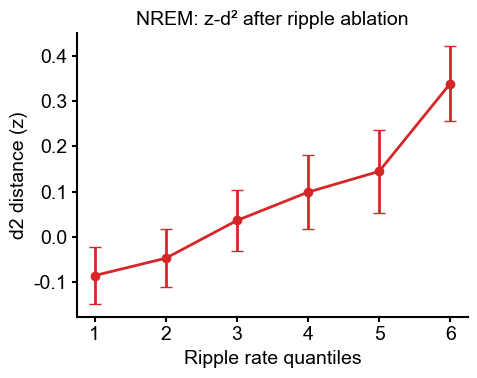

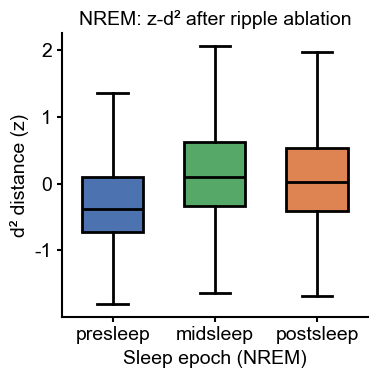

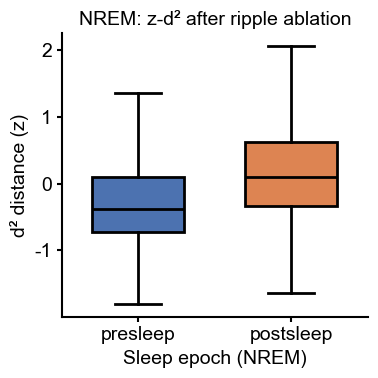

                                 Mixed Linear Model Regression Results
Model:                            MixedLM                Dependent Variable:                d2_z       
No. Observations:                 40134                  Method:                            ML         
No. Groups:                       8                      Scale:                             0.5715     
Min. group size:                  3632                   Log-Likelihood:                    -45744.8009
Max. group size:                  6002                   Converged:                         Yes        
Mean group size:                  5016.8                                                               
-------------------------------------------------------------------------------------------------------
                                                             Coef.  Std.Err.   z    P>|z| [0.025 0.975]
-------------------------------------------------------------------------------------------------

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# ---------------------------------------
# 1) Load all PKL files from out_dir
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1) Load all PKLs with filename column attached
# ---------------------------------------------------------
out_dir = Path(r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\ripple_ablate")

all_dfs = []
for p in out_dir.glob("*.pkl"):
    try:
        df = pd.read_pickle(p)
        df["file_id"] = p.name   # file name identifies the file
        all_dfs.append(df)
        print(f"Loaded: {p.name}, n={len(df)}")
    except Exception as e:
        print(f"!! Failed to load {p}: {e}")

if not all_dfs:
    raise RuntimeError("No PKL files found")

ca1_all_df = pd.concat(all_dfs, ignore_index=True)
print("Total rows:", len(ca1_all_df))


# ---------------------------------------------------------
# 2) Z-score d² WITHIN each file_id
# ---------------------------------------------------------
def zscore(x):
    return (x - x.mean()) / x.std(ddof=0)

ca1_all_df["d2_z"] = (
    ca1_all_df.groupby("file_id")["d2"]
              .transform(zscore)
)

print("Done z-scoring within each file.")


# ---------------------------------------------------------
# 3) Restrict to NREM
# ---------------------------------------------------------
nrem = ca1_all_df[ca1_all_df["state"] == "NREM"].copy()
nrem = nrem[np.isfinite(nrem["d2_z"])]


# =========================================================
# 4) Plot 1: d²_z vs ripple tiles (6 tiles: mean ± SEM)
# =========================================================
# =========================================================
# 4) Cross-file SEM for ripple tiles
# =========================================================

rate_col = "ripple_rate_30s"

nrem_rt = nrem[np.isfinite(nrem[rate_col])].copy()
NTILES = 6

# assign tiles (global quantiles)
nrem_rt["ripple_tile"] = pd.qcut(
    nrem_rt[rate_col],
    q=NTILES,
    labels=False,
    duplicates="drop"
)

# ---- compute tile mean *per file* ----
per_file_tile = (
    nrem_rt
    .groupby(["file_id", "ripple_tile"])["d2_z"]
    .mean()
    .reset_index()
)

# ---- now compute mean & SEM across files ----
tile_stats = (
    per_file_tile
    .groupby("ripple_tile")["d2_z"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

tile_stats["sem"] = tile_stats["std"] / np.sqrt(tile_stats["count"])

print(tile_stats)

# Plot mean ± SEM
fig1, ax1 = plt.subplots(figsize=(5, 4))  # 6 inches wide, 4 inches tall



tile_x = tile_stats["ripple_tile"] + 1   # shift so tiles = 1..6

ax1.errorbar(
    tile_x,
    tile_stats["mean"],
    yerr=tile_stats["sem"],
    color="tab:red",
    marker="o",
    linestyle="-", capsize=4, linewidth=2
)

ax1.set_xlabel("Ripple rate quantiles")
ax1.set_ylabel("d2 distance (z)")
ax1.set_title("NREM: z-d² after ripple ablation")
ax1.set_xticks([1,2,3,4,5,6])
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
save_fig_path=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\S3_A_ripple_ablate_d2z_vs_ripplerate.svg"
fig1.savefig(save_fig_path)
plt.tight_layout()
# =========================================================
# 6) Linear trend test across ripple tiles
# =========================================================
import scipy.stats as stats

# Prepare vectors
x = per_file_tile["ripple_tile"].astype(float)
y = per_file_tile["d2_z"].astype(float)

# -------- Linear regression (parametric) --------
lr = stats.linregress(x, y)

print("\n===== Linear Trend Test (Parametric) =====")
print(f"Slope = {lr.slope:.5f}")
print(f"Intercept = {lr.intercept:.5f}")
print(f"r = {lr.rvalue:.5f}")
print(f"p-value = {lr.pvalue:.6f}")
print(f"Std error = {lr.stderr:.5f}")

# -------- Spearman rank correlation (non-parametric) --------
rho, p_s = stats.spearmanr(x, y)

print("\n===== Linear Trend Test (Spearman) =====")
print(f"Spearman rho = {rho:.5f}")
print(f"p-value = {p_s:.6f}")


# =========================================================
# 5) Plot 2: boxplot of z-d² across sleep epochs
# =========================================================

import matplotlib.pyplot as plt

epoch_order = ["presleep", "midsleep", "postsleep"]
epoch_colors = {
    "presleep": "#4c72b0",
    "midsleep": "#55a868",
    "postsleep": "#dd8452",
}

# keep only epochs that actually exist, in desired order
available_epochs = [e for e in epoch_order if e in nrem["sleep_epoch"].unique()]

# collect data in the same order
data = [
    nrem.loc[nrem["sleep_epoch"] == e, "d2_z"].dropna().values
    for e in available_epochs
]

import matplotlib.pyplot as plt

epoch_order = ["presleep", "midsleep", "postsleep"]
epoch_colors = {
    "presleep": "#4c72b0",
    "midsleep": "#55a868",
    "postsleep": "#dd8452",
}

# keep only epochs that actually exist
available_epochs = [e for e in epoch_order if e in nrem["sleep_epoch"].unique()]

data = [
    nrem.loc[nrem["sleep_epoch"] == e, "d2_z"].dropna().values
    for e in available_epochs
]

fig2, ax2 = plt.subplots(figsize=(4, 4))

# ✅ REMOVE linewidths FROM boxplot CALL
bp = ax2.boxplot(
    data,
    labels=available_epochs,
    showfliers=False,
    widths=0.6,
    patch_artist=True,
)

# ✅ apply colors and line widths AFTER creation
for box, e in zip(bp["boxes"], available_epochs):
    box.set_facecolor(epoch_colors[e])
    box.set_edgecolor("black")
    box.set_linewidth(2)

for w in bp["whiskers"]:
    w.set_linewidth(2)

for c in bp["caps"]:
    c.set_linewidth(2)

for m in bp["medians"]:
    m.set_color("black")
    m.set_linewidth(2)

ax2.set_xlabel("Sleep epoch (NREM)")
ax2.set_ylabel("d² distance (z)")
ax2.set_title("NREM: z-d² after ripple ablation")

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()
# fig2.savefig(r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\S6_B_ripple_ablate_d2z_vs_sleepepoch.svg")
plt.show()
# only use presleep and midsleep data
plot_epochs = ["presleep", "midsleep"]

data = [
    nrem.loc[nrem["sleep_epoch"] == e, "d2_z"].dropna().values
    for e in plot_epochs
]

fig2, ax2 = plt.subplots(figsize=(4, 4))

bp = ax2.boxplot(
    data,
    widths=0.6,
    patch_artist=True,
    showfliers=False,
)

# relabel midsleep -> postsleep
xtick_labels = ["presleep", "postsleep"]
ax2.set_xticks(range(1, len(xtick_labels) + 1))
ax2.set_xticklabels(xtick_labels)

# colors (map midsleep data to postsleep color)
epoch_color_map = {
    "presleep": epoch_colors["presleep"],
    "midsleep": epoch_colors["postsleep"],  # intentional remap
}

for box, e in zip(bp["boxes"], plot_epochs):
    box.set_facecolor(epoch_color_map[e])
    box.set_edgecolor("black")
    box.set_linewidth(2)

for w in bp["whiskers"]:
    w.set_linewidth(2)
for c in bp["caps"]:
    c.set_linewidth(2)
for m in bp["medians"]:
    m.set_color("black")
    m.set_linewidth(2)

ax2.set_xlabel("Sleep epoch (NREM)")
ax2.set_ylabel("d² distance (z)")
ax2.set_title("NREM: z-d² after ripple ablation")

ax2.spines["top"].set_visible(False)
ax2.spines["right"].set_visible(False)

plt.tight_layout()
fig2.savefig(r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\S6_B_ripple_ablate_d2z_vs_sleepepoch_prepost.svg")
plt.show()

import pandas as pd

import pandas as pd
import statsmodels.formula.api as smf

# Keep only NREM windows from the three epochs
df_lmm = nrem[nrem["sleep_epoch"].isin(["presleep", "midsleep", "postsleep"])].copy()

# Make sure sleep_epoch is a categorical with correct order
df_lmm["sleep_epoch"] = pd.Categorical(
    df_lmm["sleep_epoch"],
    categories=["presleep", "midsleep", "postsleep"],
    ordered=True,
)

model_all = smf.mixedlm(
    'd2_z ~ C(sleep_epoch, Treatment(reference="presleep"))',
    df_lmm,
    groups=df_lmm["file_id"],
).fit(reml=False)

print(model_all.summary())
import numpy as np

beta = model_all.params
cov  = model_all.cov_params()

# midsleep vs postsleep contrast: (mid - post)
name_mid  = 'C(sleep_epoch, Treatment(reference="presleep"))[T.midsleep]'
name_post = 'C(sleep_epoch, Treatment(reference="presleep"))[T.postsleep]'

L = np.zeros(len(beta))
L[beta.index.get_loc(name_mid)]  = 1
L[beta.index.get_loc(name_post)] = -1
import scipy.stats
z = (L @ beta) / np.sqrt(L @ cov @ L)
p_mid_post = 2 * (1 - scipy.stats.norm.cdf(abs(z)))

print(f"Midsleep vs Postsleep: z = {z:.3f}, p = {p_mid_post:.3e}")
p_mid = model_all.pvalues[name_mid]
p_post = model_all.pvalues[name_post]
p_mid_post = p_mid_post
print(f"Mid vs Pre:  p = {p_mid:.2e}")
print(f"Post vs Pre: p = {p_post:.2e}")
print(f"Mid vs Post: p = {p_mid_post:.2e}")

In [4]:
nrem

,center_s,d2,d2_err,state,MUA,ripple_rate_hz,sleep_epoch,ripple_rate_30s,file_id,d2_z
204,624.0,0.063366,0.995809,NREM,428.416667,0.50,presleep,0.600000,PPP20_day4_CA1.pkl,0.082609
205,626.0,0.063477,0.995339,NREM,410.816667,0.25,presleep,0.500000,PPP20_day4_CA1.pkl,0.086309
206,628.0,0.065266,0.995267,NREM,411.366667,0.00,presleep,0.500000,PPP20_day4_CA1.pkl,0.145865
207,630.0,0.079928,0.994899,NREM,396.700000,0.25,presleep,0.466667,PPP20_day4_CA1.pkl,0.633829
208,632.0,0.064722,0.995356,NREM,403.600000,1.00,presleep,0.466667,PPP20_day4_CA1.pkl,0.127742
...,...,...,...,...,...,...,...,...,...,...
82690,26212.0,0.030114,0.994449,NREM,319.833333,2.00,postsleep,1.066667,PPP8_day8_CA1.pkl,-1.475072
82691,26214.0,0.034092,0.994270,NREM,324.850000,1.25,postsleep,1.066667,PPP8_day8_CA1.pkl,-1.348419
82692,26216.0,0.033979,0.994575,NREM,347.033333,2.00,postsleep,1.200000,PPP8_day8_CA1.pkl,-1.352005
82693,26218.0,0.035241,0.994694,NREM,336.583333,2.00,postsleep,1.166667,PPP8_day8_CA1.pkl,-1.311839


Paired sessions: 8


C:\Users\Cornell\AppData\Local\Temp\ipykernel_71820\22974472.py:109: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


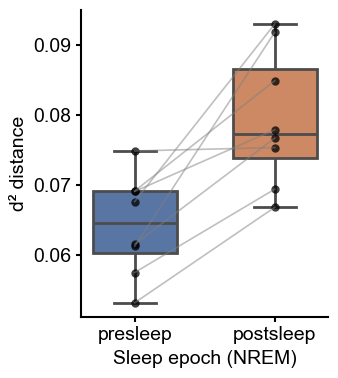

                  Mixed Linear Model Regression Results
Model:                    MixedLM       Dependent Variable:       d2     
No. Observations:         16            Method:                   ML     
No. Groups:               5             Scale:                    0.0000 
Min. group size:          2             Log-Likelihood:           49.6833
Max. group size:          4             Converged:                Yes    
Mean group size:          3.2                                            
-------------------------------------------------------------------------
                                 Coef. Std.Err.   z   P>|z| [0.025 0.975]
-------------------------------------------------------------------------
Intercept                        0.064    0.007 9.746 0.000  0.051  0.077
C(sleep_epoch_plot)[T.postsleep] 0.015    0.002 6.733 0.000  0.011  0.020
session Var                      0.000                                   

post vs pre: beta=0.01523 ± 0.002262, p=1.658e-11


c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1533: RuntimeWarning: divide by zero encountered in log
  cov_aug_logdet = cov_re_logdet + np.sum(np.log(vc_var))
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1537: RuntimeWarning: divide by zero encountered in divide
  solver = _smw_solver(1., ex_r, ex2_r, cov_re_inv, 1 / vc_var)
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1542: RuntimeWarning: divide by zero encountered in divide
  ld = _smw_logdet(1., ex_r, ex2_r, cov_re_inv, 1 / vc_var,
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:573: RuntimeWarning: invalid value encountered in scalar add
  return B_logdet + ld + ld1
c:\Users\Cornell\.conda\envs\criticality\Lib\site-packages\statsmodels\regression\mixed_linear_model.py:1634: UserWarning: Random effects 

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False
mpl.rcParams["axes.linewidth"] = 1.5
mpl.rcParams["xtick.major.width"] = 1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5

def _despine(ax):
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(False)

# -------------------------
# Settings
# -------------------------
plot_epochs = ["presleep", "midsleep"]
xtick_labels = ["presleep", "postsleep"]   # display label remap midsleep->postsleep
epoch_color_map = {
    "presleep": epoch_colors["presleep"],
    "midsleep": epoch_colors["postsleep"],  # intentional remap
}

# REQUIRED: column that identifies session
SESSION_COL = "file_id"

# Within-session summary statistic:
AGG = "mean"  # "mean" or "median"

# -------------------------
# 1) Reduce to one number per session per epoch
# -------------------------
df = nrem.loc[nrem["sleep_epoch"].isin(plot_epochs), [SESSION_COL, "sleep_epoch", "d2"]].dropna().copy()

if AGG == "mean":
    sess = (df.groupby([SESSION_COL, "sleep_epoch"])["d2"]
              .mean()
              .rename("d2_z_sess")
              .reset_index())
else:
    sess = (df.groupby([SESSION_COL, "sleep_epoch"])["d2"]
              .median()
              .rename("d2_z_sess")
              .reset_index())

# Pivot to wide (paired)
wide = sess.pivot(index=SESSION_COL, columns="sleep_epoch", values="d2_z_sess")

# Keep only sessions with both epochs
wide = wide.dropna(subset=plot_epochs)

pre = wide["presleep"].to_numpy()
mid = wide["midsleep"].to_numpy()
n_pair = len(wide)

print(f"Paired sessions: {n_pair}")

# -------------------------
# 2) Plot: paired lines + boxplot overlay
# -------------------------
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

# wide has index = session, columns = presleep / midsleep
# wide = wide.dropna(subset=["presleep","midsleep"])

long = (
    wide
    .reset_index()
    .melt(id_vars=SESSION_COL,
          value_vars=["presleep", "midsleep"],
          var_name="sleep_epoch",
          value_name="d2")
)

# remap midsleep -> postsleep for display
long["sleep_epoch_plot"] = long["sleep_epoch"].replace({"midsleep": "postsleep"})

fig, ax = plt.subplots(figsize=(3.6, 4))

palette = {
    "presleep": epoch_colors["presleep"],
    "postsleep": epoch_colors["postsleep"]
}

# --- boxplot ---
sns.boxplot(
    data=long,
    x="sleep_epoch_plot",
    y="d2",
    order=["presleep", "postsleep"],
    palette=palette,
    width=0.6,
    showfliers=False,
    linewidth=2,
    ax=ax,
    zorder=1
)

# --- jittered points ---
sns.stripplot(
    data=long,
    x="sleep_epoch_plot",
    y="d2",
    order=["presleep", "postsleep"],
    color="k",
    size=6,
    jitter=0,
    alpha=0.75,
    ax=ax,
    zorder=2
)

# --- paired lines ---
sns.lineplot(
    data=long,
    x="sleep_epoch_plot",
    y="d2",
    units=SESSION_COL,    estimator=None,
    sort=False,
    color="gray",
    alpha=0.5,
    linewidth=1.2,
    legend=False,
    ax=ax,
    zorder=3
)

# formatting
ax.set_xlabel("Sleep epoch (NREM)")
ax.set_ylabel("d² distance")
_despine(ax)

plt.tight_layout()
save_path = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\S2_D_ripple_ablate_d2z_vs_sleepepoch_paired.svg"
plt.savefig(save_path,dpi=300,bbox_inches="tight")
plt.show()

import pandas as pd
import statsmodels.formula.api as smf

# long must contain: d2, sleep_epoch_plot (presleep/postsleep), file_id, animal

lmm_df = long.copy()
lmm_df["animal"] = lmm_df["file_id"].str.extract(r"^([A-Za-z]+[0-9]+)", expand=False)
# Ensure the epoch is categorical with presleep as reference
lmm_df["sleep_epoch_plot"] = pd.Categorical(
    lmm_df["sleep_epoch_plot"],
    categories=["presleep", "postsleep"],
    ordered=True
)

# Paired LMM:
# - groups = animal (random intercept per animal)
# - vc_formula adds a random intercept per session (file_id),
#   which pairs presleep/postsleep within each file_id
model = smf.mixedlm(
    "d2 ~ C(sleep_epoch_plot)",              # fixed effect: epoch (post vs pre)
    data=lmm_df,
    groups=lmm_df["animal"],                 # random intercept: animal
    vc_formula={"session": "0 + C(file_id)"} # random intercept: session/file_id
)

res = model.fit(reml=False, method="lbfgs")
print(res.summary())

# Extract the p-value for postsleep vs presleep
term = "C(sleep_epoch_plot)[T.postsleep]"
p = res.pvalues[term]
beta = res.params[term]
se = res.bse[term]
print(f"post vs pre: beta={beta:.4g} ± {se:.4g}, p={p:.4g}")

In [5]:
lmm_df

,file_id,sleep_epoch,d2,sleep_epoch_plot
0,PPP20_day4_CA1.pkl,presleep,0.053171,presleep
1,PPP20_day5_CA1.pkl,presleep,0.061553,presleep
2,PPP21_day4_CA1.pkl,presleep,0.057495,presleep
3,PPP21_day5_CA1.pkl,presleep,0.067640,presleep
4,PPP4_day11_CA1.pkl,presleep,0.061237,presleep
5,PPP7_day10_CA1.pkl,presleep,0.069153,presleep
6,PPP7_day7_CA1.pkl,presleep,0.074882,presleep
7,PPP8_day8_CA1.pkl,presleep,0.069089,presleep
8,PPP20_day4_CA1.pkl,midsleep,0.066827,postsleep
9,PPP20_day5_CA1.pkl,midsleep,0.076726,postsleep


Ablate ripple timecourse through

In [43]:
import scipy.stats as stats

print("\n===== Correlation: d² vs time, per epoch =====")

corr_results = []

for ep in keep_epochs:
    sub = grouped[grouped["sleep_epoch"] == ep]
    sub = sub[sub["t_min"] <= 50]  # match the plotted time window

    if len(sub) < 3:
        print(f"{ep}: not enough points")
        continue

    x = sub["t_min"].values
    y = sub["d2_mean"].values

    # Pearson correlation
    pearson_r, pearson_p = stats.pearsonr(x, y)

    # Spearman correlation (rank-based)
    spearman_r, spearman_p = stats.spearmanr(x, y)

    print(f"\nEpoch: {ep}")
    print(f"  Pearson r = {pearson_r:.4f},   p = {pearson_p:.4g}")
    print(f"  Spearman rho = {spearman_r:.4f}, p = {spearman_p:.4g}")

    corr_results.append({
        "epoch": ep,
        "pearson_r": pearson_r,
        "pearson_p": pearson_p,
        "spearman_r": spearman_r,
        "spearman_p": spearman_p
    })

# Convert to DataFrame if needed
corr_df = pd.DataFrame(corr_results)


===== Correlation: d² vs time, per epoch =====

Epoch: presleep
  Pearson r = -0.3465,   p = 0.5678
  Spearman rho = -0.3000, p = 0.6238

Epoch: midsleep
  Pearson r = -0.9535,   p = 0.01197
  Spearman rho = -1.0000, p = 1.404e-24

Epoch: postsleep
  Pearson r = -0.8471,   p = 0.07009
  Spearman rho = -0.9000, p = 0.03739


S1 H state transition

===== Sessions in df_snips =====
Animal: PPP20, Day: day4, n_snippets=6
Animal: PPP20, Day: day5, n_snippets=3
Animal: PPP21, Day: day4, n_snippets=3
Animal: PPP21, Day: day5, n_snippets=3
Animal: PPP4, Day: day10, n_snippets=3
Animal: PPP7, Day: day7, n_snippets=3
Animal: PPP7, Day: day8, n_snippets=3
Animal: PPP8, Day: day7, n_snippets=3


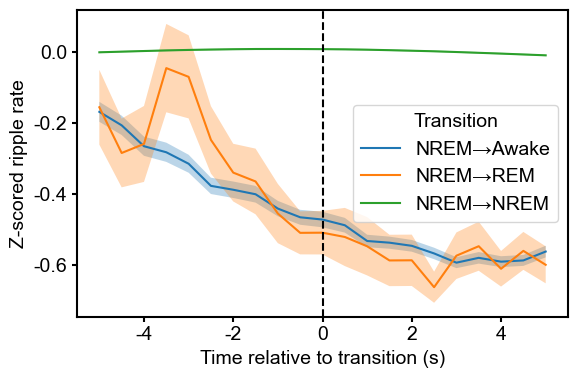

<Figure size 640x480 with 0 Axes>

   transition animal    day     session     slope
0  NREM→Awake  PPP20   day4  PPP20_day4 -0.028176
1  NREM→Awake  PPP20   day5  PPP20_day5 -0.074962
2  NREM→Awake  PPP21   day4  PPP21_day4 -0.083982
3  NREM→Awake  PPP21   day5  PPP21_day5 -0.074316
4  NREM→Awake   PPP4  day10  PPP4_day10 -0.080961
   transition  n_files  median_slope   p_value
0  NREM→Awake        8     -0.074639  0.003906
1   NREM→NREM        8      0.002411  1.000000
2    NREM→REM        8     -0.064532  0.007812


In [56]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 1. Load snippets DataFrame
pkl_path = r"D:\Documents\GitHub\R_Project\PPP\codebook\Criticality_analysis\avalanche\transition_snippets.pkl"
df_snips = pd.read_pickle(pkl_path)


# 2. Compute mean and std per (animal_name, day) for z-scoring
session_stats = {}
for (animal, day), grp in df_snips.groupby(['animal_name', 'day']):
    all_vals = np.concatenate(grp['snippets'].values)
    session_mean = all_vals.mean()
    session_std  = all_vals.std(ddof=1)
    session_stats[(animal, day)] = (session_mean, session_std)

# 3. Apply z-score normalization to each snippet array
def zscore_snippet(row):
    mu, sigma = session_stats[(row['animal_name'], row['day'])]
    return (row['snippets'] - mu) / sigma

df_snips['z_snippets'] = df_snips.apply(zscore_snippet, axis=1)

# 4. Define time axis from any snippet length
bin_size = 0.5
snippet_length = df_snips['snippets'].iloc[0].shape[1]
half_bins = snippet_length // 2
times_rel = (np.arange(snippet_length) - half_bins) * bin_size
sessions = df_snips.groupby(['animal_name', 'day']).size().reset_index(name="n_snippets")

print("===== Sessions in df_snips =====")
for _, row in sessions.iterrows():
    print(f"Animal: {row['animal_name']}, Day: {row['day']}, n_snippets={row['n_snippets']}")

# 5. Pool z-scored data and compute mean±SEM per transition
pooled_z = {}
for trans in df_snips['transition'].unique():
    arr = np.vstack(df_snips.loc[df_snips['transition'] == trans, 'z_snippets'].values)
    mean_z = arr.mean(axis=0)
    sem_z  = arr.std(axis=0, ddof=1) / np.sqrt(arr.shape[0])
    pooled_z[trans] = (mean_z, sem_z)

# 6. Plot z-scored curves
fig, ax = plt.subplots(figsize=(6,4))
for trans, (mean_z, sem_z) in pooled_z.items():
    ax.plot(times_rel, mean_z, label=trans)
    ax.fill_between(times_rel, mean_z - sem_z, mean_z + sem_z, alpha=0.3)

ax.axvline(0, color='k', linestyle='--')
ax.set_xlabel("Time relative to transition (s)")
ax.set_ylabel("Z-scored ripple rate")
ax.legend(title="Transition")
plt.tight_layout()
plt.show()

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.show()
import numpy as np
import pandas as pd
from scipy.stats import linregress, wilcoxon

# ---- Time axis ----
bin_size = 0.5
snippet_length = df_snips['z_snippets'].iloc[0].shape[0]
half_bins = snippet_length // 2
times_rel = (np.arange(snippet_length) - half_bins) * bin_size

pre_idx = times_rel < 0   # only t < 0 sec
xs_pre = times_rel[pre_idx]

# ---------------------------------------------------------
# FUNCTION: compute pre-transition slope for ONE session
# ---------------------------------------------------------
import numpy as np
from scipy.stats import linregress, wilcoxon

BIN_SIZE = 0.5  # seconds per bin

def compute_pre_slope(z_curve, bin_size=BIN_SIZE):
    """
    Compute pre-transition slope for a single z-scored curve.
    z_curve: 1D array (length T).
    Uses that curve's own length to build time axis; no global mask.
    """
    z_curve = np.asarray(z_curve, float)
    T = z_curve.size
    if T < 3:
        return np.nan

    half_bins = T // 2
    times_rel = (np.arange(T) - half_bins) * bin_size

    # only t < 0
    mask = times_rel < 0
    xs = times_rel[mask]
    ys = z_curve[mask]

    if ys.size < 2:
        return np.nan

    lr = linregress(xs, ys)
    return lr.slope
results = []

for trans, g_trans in df_snips.groupby("transition"):
    for (animal, day), g_sess in g_trans.groupby(["animal_name", "day"]):

        # pool snippets → mean curve for this session & transition
        Z = np.vstack(g_sess["z_snippets"].values)   # (n_events, T)
        mean_curve = Z.mean(axis=0)

        slope = compute_pre_slope(mean_curve)

        results.append({
            "transition": trans,
            "animal": animal,
            "day": day,
            "session": f"{animal}_{day}",
            "slope": slope,
        })

df_slopes = pd.DataFrame(results)


df_slopes = pd.DataFrame(results)
print(df_slopes.head())
transition_tests = []

for trans, g in df_slopes.groupby("transition"):
    slopes = g["slope"].dropna().values
    if len(slopes) < 2:
        print(f"Skipping {trans} (only {len(slopes)} sessions).")
        continue

    stat, p = wilcoxon(slopes, alternative="less")  # test slope < 0
    transition_tests.append({
        "transition": trans,
        "n_files": len(slopes),
        "median_slope": np.median(slopes),
        "p_value": p,
    })

df_tests = pd.DataFrame(transition_tests)
print(df_tests)

In [49]:
pre_idx = times_rel < 0   # select only t < 0
x = times_rel[pre_idx]    # time axis (negative values)
y = mean_z[pre_idx]       # pooled mean z-d2
from scipy.stats import spearmanr
rho, p = spearmanr(x, y)
print(f"Spearman rho = {rho:.3f}, p = {p:.3g}")

Spearman rho = 0.964, p = 7.32e-06


State transition

Loading session from: W:\data\PPP\PPP20\day4\complex_system
  Found 1 matching files.
Loading session from: W:\data\PPP\PPP20\day5\complex_system
  Found 1 matching files.
Loading session from: W:\data\PPP\PPP21\day5\complex_system
  Found 1 matching files.
Loading session from: W:\data\PPP\PPP21\day4\complex_system
  Found 1 matching files.
Loading session from: W:\data\PPP\PPP8\day8\complex_system
  Found 1 matching files.
Loading session from: W:\data\PPP\PPP4\day11\complex_system
  Found 1 matching files.
Loading session from: W:\data\PPP\PPP7\day7\complex_system
  Found 1 matching files.
Loading session from: W:\data\PPP\PPP7\day8\complex_system
  Found 1 matching files.
Loading session from: W:\data\PPP\PPP7\day12\complex_system
  Found 1 matching files.
Loading session from: W:\data\PPP\PPP7\day10\complex_system
  Found 1 matching files.
Loading session from: W:\data\PPP\PPP23\day7\complex_system
  Found 1 matching files.
Loading session from: W:\data\PPP\PPP23\day8\complex_syst

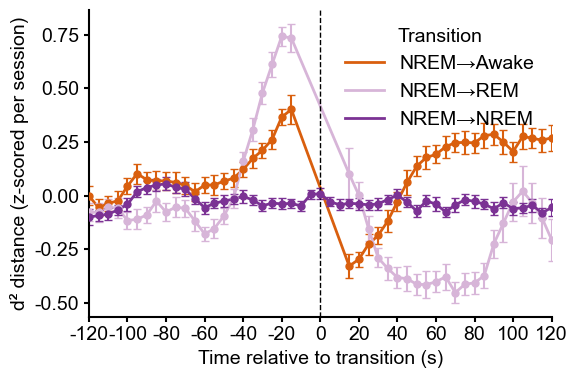

In [136]:
import os, re, glob
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import sem
import matplotlib as mpl
# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# =====================================================
# 1. Load state, center_s, d2 from *_time_resolved_state_transition
# =====================================================

def _infer_animal_day_from_path(basepath):
    basepath = os.path.normpath(basepath)
    animal = os.path.basename(os.path.dirname(basepath))
    day_raw = os.path.basename(basepath)
    mday = re.search(r"day(\d+)", day_raw, flags=re.I)
    day = int(mday.group(1)) if mday else None
    return animal, day

def _extract_state_d2_center_from_mat(mat_path, region=None, animal=None, day=None):
    """
    Extract per-window state, center_s and d2 from a *_time_resolved_state_transition.mat file.

    Returns DataFrame with columns:
        ['state', 'center_s', 'd2', 'region', 'animal', 'day']
    """
    mat = _load_mat_any(mat_path)

    results = mat.get("results", None)
    if results is None:
        return pd.DataFrame(columns=["state","center_s","d2","region","animal","day"])

    # results is typically a MATLAB struct array with fields: state, center, d2, d2_err
    if isinstance(results, dict):
        iter_results = list(results.values())
    else:
        iter_results = list(results if isinstance(results, (list, tuple)) else np.atleast_1d(results))

    rows = []
    for it in iter_results:
        # get state / center / d2 for each state block
        if hasattr(it, "get"):
            st = _to_state_str(it.get("state", "UNKNOWN"))
            centers_raw = it.get("center", [])
            d2_raw      = it.get("d2", [])
        elif isinstance(it, dict) or hasattr(it, "__getitem__"):
            st = _to_state_str(it.get("state", it["state"] if "state" in it else "UNKNOWN"))
            centers_raw = it.get("center", it["center"] if "center" in it else [])
            d2_raw      = it.get("d2", it["d2"] if "d2" in it else [])
        else:
            continue

        centers = _to_1d_array(centers_raw)
        d2_vals = _to_1d_array(d2_raw)

        # align lengths, filter nan
        n = min(centers.size, d2_vals.size)
        if n == 0:
            continue
        centers = centers[:n]
        d2_vals = d2_vals[:n]

        mask = np.isfinite(centers) & np.isfinite(d2_vals)
        centers = centers[mask]
        d2_vals = d2_vals[mask]
        if centers.size == 0:
            continue

        st_up = st.upper()
        if st_up == "WAKE":
            st_up = "AWAKE"
        if st_up not in ("NREM", "REM", "AWAKE"):
            continue

        rows.append(pd.DataFrame({
            "state":  st_up,
            "center_s": centers,
            "d2":     d2_vals,
            "region": region if region else "",
            "animal": animal if animal else "",
            "day":    day if day is not None else np.nan,
        }))

    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame(
        columns=["state","center_s","d2","region","animal","day"]
    )

def load_state_d2_from_session(basepath, region="CA1"):
    """
    Load one session: basepath\complex_system\*_time_resolved_state_transition*.mat.
    Returns DataFrame with state, center_s, d2, region, animal, day.
    """
    search_dir = Path(basepath) / "complex_system"
    print(f"Loading session from: {search_dir}")
    if not search_dir.exists():
        return pd.DataFrame(columns=["state","center_s","d2","region","animal","day"])

    # filename pattern
    pattern = "*_time_resolved_state_transition*.mat"
    files = glob.glob(str(search_dir / pattern))
    if not files:
        return pd.DataFrame(columns=["state","center_s","d2","region","animal","day"])
    else:
        print(f"  Found {len(files)} matching files.")  
    # pick newest file if multiple
    mat_path = max(files, key=os.path.getmtime)

    animal, day = _infer_animal_day_from_path(basepath)
    df = _extract_state_d2_center_from_mat(mat_path, region=region, animal=animal, day=day)
    return df

# =====================================================
# 2. Build big DataFrame across all basepaths & z-score per session
# =====================================================

basepaths = [
    r"W:\data\PPP\PPP20\day4",
    r"W:\data\PPP\PPP20\day5",
    r"W:\data\PPP\PPP21\day5",
    r"W:\data\PPP\PPP21\day4",
    r"W:\data\PPP\PPP8\day8",
    r"W:\data\PPP\PPP4\day11",
    r"W:\data\PPP\PPP7\day7",
    r"W:\data\PPP\PPP7\day8",
    r"W:\data\PPP\PPP7\day12",
    r"W:\data\PPP\PPP7\day10",
    r"W:\data\PPP\PPP23\day7",
    r"W:\data\PPP\PPP23\day8",
    r"W:\data\PPP\PPP20\day3",
    r"W:\data\PPP\PPP21\day3",
]

dfs = []
for bp in basepaths:
    dtmp = load_state_d2_from_session(bp, region="CA1")
    if not dtmp.empty:
        dfs.append(dtmp)

df_all = pd.concat(dfs, ignore_index=True)
df_all["session"] = df_all["animal"].astype(str) + "_day" + df_all["day"].astype(int).astype(str)

# z-score d2 within each session
def _zscore(x):
    mu = x.mean()
    sd = x.std(ddof=0)
    if sd == 0 or not np.isfinite(sd):
        return np.full_like(x, np.nan, dtype=float)
    return (x - mu) / sd

df_all["d2_z"] = df_all.groupby("session")["d2"].transform(_zscore)
df_all = df_all[np.isfinite(df_all["d2_z"])].copy()

# =====================================================
# 3. Detect transitions and collect ±3 min snippets
# =====================================================

def find_transition_events(df_sess, thr_sec=5.0):
    """
    Given a single-session df (sorted by time), find:
      - NREM→REM
      - NREM→AWAKE
      - NREM→NREM (potential control)
    where consecutive centers are within thr_sec.
    Returns list of dicts: {session, t0, transition}
    """
    df_sess = df_sess.sort_values("center_s").reset_index(drop=True)
    centers = df_sess["center_s"].to_numpy()
    states  = df_sess["state"].to_numpy()

    events = []
    for i in range(len(df_sess) - 1):
        dt = centers[i+1] - centers[i]
        if dt > thr_sec:
            continue
        s1, s2 = states[i], states[i+1]
        if s1 != "NREM":
            continue

        if s2 == "REM":
            label = "NREM→REM"
        elif s2 == "AWAKE":
            label = "NREM→Awake"
        elif s2 == "NREM":
            label = "NREM→NREM"
        else:
            continue

        t0 = 0.5 * (centers[i] + centers[i+1])  # midpoint between windows
        events.append({
            "session": df_sess["session"].iloc[0],
            "t0": t0,
            "transition": label,
        })
    return events

# --- 3a. Collect all events across sessions ---
all_events = []
for sess, g in df_all.groupby("session"):
    all_events.extend(find_transition_events(g, thr_sec=60))

events_df = pd.DataFrame(all_events)
if events_df.empty:
    raise RuntimeError("No transitions detected!")

# --- 3b. Subsample NREM→NREM as control to match real transitions ---
real_mask = events_df["transition"].isin(["NREM→REM", "NREM→Awake"])
n_real = real_mask.sum()

ctrl_mask = events_df["transition"] == "NREM→NREM"
ctrl_candidates = events_df[ctrl_mask]

if not ctrl_candidates.empty:
    n_ctrl = min(len(ctrl_candidates), n_real)
    ctrl_sample = ctrl_candidates.sample(n=n_ctrl, random_state=0, replace=False)
    selected_events = pd.concat([events_df[real_mask], ctrl_sample], ignore_index=True)
else:
    selected_events = events_df[real_mask].copy()

# =====================================================
# 4. Build pooled snippets: ±3 min around each transition
# =====================================================

PRE  = 120.0  # seconds
POST = 120.0  # seconds

# for fast access, index df_all by session
session_dfs = {s: g.sort_values("center_s").reset_index(drop=True)
               for s, g in df_all.groupby("session")}

snippet_rows = []

for _, ev in selected_events.iterrows():
    sess = ev["session"]
    t0   = ev["t0"]
    label = ev["transition"]

    g = session_dfs[sess]
    mask = (g["center_s"] >= t0 - PRE) & (g["center_s"] <= t0 + POST)
    sub = g.loc[mask, ["center_s", "d2_z"]].copy()
    if sub.empty:
        continue

    sub["t_rel"] = sub["center_s"] - t0
    for _, row in sub.iterrows():
        snippet_rows.append({
            "session": sess,
            "transition": label,
            "t_rel": row["t_rel"],
            "d2_z": row["d2_z"],
        })

snip_df = pd.DataFrame(snippet_rows)
if snip_df.empty:
    raise RuntimeError("No snippet points collected!")

# =====================================================
# 5. Pool across events: mean ± SEM for each t_rel & transition
# =====================================================

# round t_rel to the step size
STEP = 5
snip_df["t_rel_round"] = (np.round(snip_df["t_rel"] / STEP) * STEP).astype(float)

grouped = (snip_df
           .groupby(["transition", "t_rel_round"])["d2_z"]
           .agg(["mean", sem, "count"])
           .reset_index()
           .rename(columns={"mean": "d2_mean", "sem": "d2_sem"}))

# =====================================================
# 6. Plot mean ± SEM around transitions
# =====================================================

plt.figure(figsize=(6, 4))
ax = plt.gca()

colors = {
    "NREM→Awake": "#d95f0e",
    "NREM→REM":   "#d7b5d8",
    "NREM→NREM":  "#7b3294",
}

for trans in ["NREM→Awake", "NREM→REM", "NREM→NREM"]:
    sub = grouped[grouped["transition"] == trans]
    if sub.empty:
        continue

    x = sub["t_rel_round"].to_numpy()
    y = sub["d2_mean"].to_numpy()
    e = sub["d2_sem"].to_numpy()
    c = colors.get(trans, "gray")

    # ---- Mean line ----
    ax.plot(x, y, color=c, linewidth=2, label=trans)

    # ---- Scatter points ----
    ax.scatter(x, y, color=c, s=25, zorder=3)

    # ---- SEM error bars ----
    ax.errorbar(
        x, y, yerr=e,
        fmt="none",        # no extra markers (we already used scatter)
        ecolor=c,
        elinewidth=1.5,
        capsize=3,
        zorder=2
    )

# ---- Transition reference line ----
ax.axvline(0, color="k", linestyle="--", linewidth=1)

# ---- Axes formatting ----
ax.set_xlim(-PRE, POST)
ax.set_xlabel("Time relative to transition (s)")
ax.set_ylabel("d² distance (z-scored per session)")
ax.set_xticks(np.arange(-PRE, POST + 1, 20))
ax.legend(title="Transition", frameon=False)

# ---- Clean style ----
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
save_fig_path=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\S1_H_nrem_d2_transition_snippets.svg"
plt.savefig(save_fig_path)
plt.show()

In [147]:
from scipy.stats import ttest_rel, wilcoxon, spearmanr

baseline_win  = (-120, -80)
pre_win       = (-30, -15)
trend_win     = (-20, 35)

results_session_paired = {}

for trans in ["NREM→Awake", "NREM→REM", "NREM→NREM"]:
    sub = snip_df[snip_df["transition"] == trans].copy()
    sub = sub[np.isfinite(sub["d2_z"])]

    rows = []

    for sess, g in sub.groupby("session"):
        x = g["t_rel_round"].to_numpy()
        y = g["d2_z"].to_numpy()

        base_vals = y[(x >= baseline_win[0]) & (x <= baseline_win[1])]
        pre_vals  = y[(x >= pre_win[0])      & (x <= pre_win[1])]

        if base_vals.size == 0 or pre_vals.size == 0:
            continue

        rows.append({
            "session": sess,
            "base_mean": np.nanmean(base_vals),
            "pre_mean":  np.nanmean(pre_vals),
        })

    if not rows:
        continue

    sess_df = pd.DataFrame(rows)

    diff = sess_df["pre_mean"] - sess_df["base_mean"]

    # --- Paired test (choose ONE) ---
    tstat, p_ttest = ttest_rel(
        sess_df["pre_mean"], sess_df["base_mean"]
    )

    wstat, p_wil = wilcoxon(
        sess_df["pre_mean"], sess_df["base_mean"]
    )

    # --- Trend (session-paired Spearman) ---
    trend_rows = []
    for sess, g in sub.groupby("session"):
        x = g["t_rel_round"].to_numpy()
        y = g["d2_z"].to_numpy()

        m = (x >= trend_win[0]) & (x <= trend_win[1])
        if m.sum() < 3:
            continue

        rho,  p_rho = spearmanr(x[m], y[m])
        trend_rows.append({"rho": rho, "p": p_rho})

    trend_rows = np.array(trend_rows)
    rho_vals = np.array([r["rho"] for r in trend_rows if np.isfinite(r["rho"])])

    if len(rho_vals) >= 3:
        wstat, p_group = wilcoxon(rho_vals)
    else:
        wstat, p_group = np.nan, np.nan
    results_session_paired[trans] = {
        "mean_pre_minus_base": diff.mean(),
        "p_ttest": p_ttest,
        "p_wilcoxon": p_wil,
        "n_sessions": len(sess_df),
        "mean_spearman_rho": np.nanmean(rho_vals),
        "p_spearman_group": p_group,
    }
print("\n===== Paired session results =====")
for k, v in results_session_paired.items():
    print(f"\nTransition: {k}")
    print(f"  n_sessions = {v['n_sessions']}")
    print(f"  Mean pre - baseline d² = {v['mean_pre_minus_base']:.4f}")
    print(f"  Paired t-test p = {v['p_ttest']:.4g}")
    print(f"  Wilcoxon p = {v['p_wilcoxon']:.4g}")
    print(f"  Mean Spearman rho (trend) = {v['mean_spearman_rho']:.4f}")
    print(f"  Mean Spearman p (trend) = {v['p_spearman_group']:.4g}")


===== Paired session results =====

Transition: NREM→Awake
  n_sessions = 14
  Mean pre - baseline d² = 0.2700
  Paired t-test p = 0.006373
  Wilcoxon p = 0.003052
  Mean Spearman rho (trend) = -0.1789
  Mean Spearman p (trend) = 0.002319

Transition: NREM→REM
  n_sessions = 11
  Mean pre - baseline d² = 0.6551
  Paired t-test p = 1.115e-05
  Wilcoxon p = 0.0009766
  Mean Spearman rho (trend) = -0.4444
  Mean Spearman p (trend) = 0.00293

Transition: NREM→NREM
  n_sessions = 14
  Mean pre - baseline d² = 0.0003
  Paired t-test p = 0.9937
  Wilcoxon p = 0.9032
  Mean Spearman rho (trend) = 0.0049
  Mean Spearman p (trend) = 0.9515


Processing W:\data\PPP\PPP20\day4
Processing W:\data\PPP\PPP20\day5
Processing W:\data\PPP\PPP21\day5
Processing W:\data\PPP\PPP21\day4
Processing W:\data\PPP\PPP8\day8
Processing W:\data\PPP\PPP4\day11
Processing W:\data\PPP\PPP7\day7
Processing W:\data\PPP\PPP7\day8
Processing W:\data\PPP\PPP7\day12
Processing W:\data\PPP\PPP7\day10
Processing W:\data\PPP\PPP23\day7
Processing W:\data\PPP\PPP23\day8
Processing W:\data\PPP\PPP20\day3
Processing W:\data\PPP\PPP21\day3


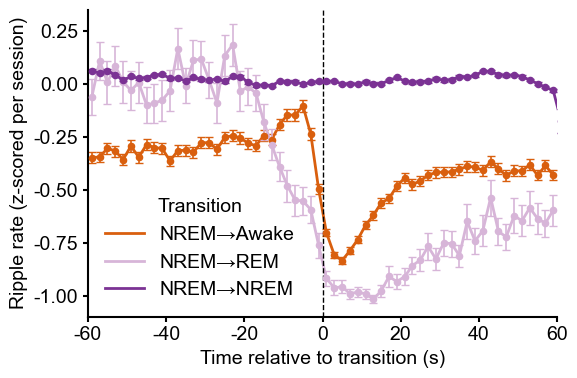

In [149]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import nelpy as nel

# =========================
# Parameters
# =========================
BIN  = 2    # ripple-rate bin (s)
PRE  = 60.0     # seconds before transition
POST = 60.0     # seconds after transition

TRANSITIONS = ["NREM→Awake", "NREM→REM", "NREM→NREM"]

colors = {
    "NREM→Awake": "#d95f0e",
    "NREM→REM":   "#d7b5d8",
    "NREM→NREM":  "#7b3294",
}

# =========================
# Helpers
# =========================

import numpy as np
import nelpy as nel

def find_transitions_within_epoch(
    nrem_ep,
    wake_ep,
    rem_ep,
    epoch_ep,
    max_gap=10.0,
    max_back=2.0,
    n_controls_per_real=20,  # Keep this high to reduce noise!
    # required_pre/required_post should match the plotting window (e.g. 60s)
    required_pre=60.0,
    required_post=60.0   
):
    """
    Finds real transitions and generates 'Safe' NREM->NREM controls.
    Control points are now guaranteed to have 'required_pre' seconds of NREM before
    and 'required_post' seconds of NREM after, ensuring the whole window is NREM.
    """
    transitions = []

    # ---------- restrict states to this epoch ----------
    nrem = nrem_ep & epoch_ep
    wake = wake_ep & epoch_ep
    rem  = rem_ep  & epoch_ep

    # to numpy arrays
    nrem_starts = np.asarray(getattr(nrem, "starts", []), float)
    nrem_stops  = np.asarray(getattr(nrem, "stops",  []), float)
    wake_starts = np.asarray(getattr(wake, "starts", []), float)
    rem_starts  = np.asarray(getattr(rem,  "starts",  []), float)

    if nrem_starts.size == 0 or len(epoch_ep) == 0:
        return transitions

    ep_start = float(epoch_ep.starts[0])
    ep_stop  = float(epoch_ep.stops[0])

    # ---------- 1) real NREM→Awake / NREM→REM transitions ----------
    real_transition_times = [] 

    for ns, ne in zip(nrem_starts, nrem_stops):
        t0 = float(ne)
        if (t0 < ep_start) or (t0 > ep_stop):
            continue

        candidates = []
        # candidate WAKE
        if wake_starts.size > 0:
            dw = wake_starts - t0
            idx = np.where((dw >= -max_back) & (dw <= max_gap))[0]
            if idx.size > 0:
                j = idx[np.argmin(np.abs(dw[idx]))]
                candidates.append(("NREM→Awake", float(wake_starts[j])))

        # candidate REM
        if rem_starts.size > 0:
            dr = rem_starts - t0
            idx = np.where((dr >= -max_back) & (dr <= max_gap))[0]
            if idx.size > 0:
                j = idx[np.argmin(np.abs(dr[idx]))]
                candidates.append(("NREM→REM", float(rem_starts[j])))

        if candidates:
            kind, ts = sorted(candidates, key=lambda x: x[1])[0]
            transitions.append({"t": t0, "kind": kind})
            real_transition_times.append(t0)

    if len(real_transition_times) == 0:
        return transitions

    # ---------- 2) STRICT NREM→NREM controls ----------
    # We only use segments that are long enough to hold the full window
    # i.e., Length > (required_pre + required_post)
    
    usable_segments = []
    for ns, ne in zip(nrem_starts, nrem_stops):
        # Calculate the "Safe Zone" for the center point (t=0)
        valid_start = ns + required_pre
        valid_stop  = ne - required_post
        
        # If the bout is too short, valid_stop will be less than valid_start
        if valid_stop > valid_start:
            usable_segments.append((valid_start, valid_stop))

    if len(usable_segments) == 0:
        # No NREM bouts are long enough to hold the full window
        return transitions

    rng = np.random.default_rng()

    # Generate controls
    for _ in real_transition_times:
        for _ in range(n_controls_per_real):
            # Pick a random valid segment
            seg_idx = rng.integers(low=0, high=len(usable_segments))
            s, e = usable_segments[seg_idx]
            
            # Pick a random time inside the safe zone
            t_ctrl = float(rng.uniform(s, e))
            
            if (t_ctrl < ep_start) or (t_ctrl > ep_stop):
                continue
                
            transitions.append({"t": t_ctrl, "kind": "NREM→NREM"})

    return transitions

def bin_ripple_rate_around_transition(peaks, t0, pre, post, bin_size=0.5):
    """
    Bin ripple peaks in [t0-pre, t0+post] and return:
        t_rel: bin centers relative to t0 (can be negative)
        rate:  ripple rate (Hz) per bin
    """
    if peaks is None or len(peaks) == 0:
        return np.array([]), np.array([])

    t_start = t0 - pre
    t_stop  = t0 + post

    edges = np.arange(t_start, t_stop + bin_size, bin_size)
    if edges.size < 2:
        return np.array([]), np.array([])

    counts, _ = np.histogram(peaks, bins=edges)
    rate = counts / float(bin_size)
    centers = 0.5 * (edges[:-1] + edges[1:])
    t_rel = centers - t0      # negative before, positive after

    return t_rel, rate


def extract_ripple_peaks(ripple_events):
    """
    Handle different ripple Event formats.
    Here ripple_events is a DataFrame (possibly empty).
    """
    if ripple_events is None:
        return np.array([])

    # If it's a DataFrame:
    if isinstance(ripple_events, pd.DataFrame):
        if ripple_events.empty:
            return np.array([])
        # try to auto-detect a peak/ time column
        peak_col = None
        for c in ripple_events.columns:
            cl = c.lower()
            if "peak" in cl or "time" in cl or "ts" in cl:
                peak_col = c
                break
        if peak_col is None:
            # no usable column
            return np.array([])
        return ripple_events[peak_col].to_numpy(dtype=float)

    # If it's some nelpy-like ripple object with .peaks:
    if hasattr(ripple_events, "peaks"):
        return np.asarray(ripple_events.peaks, float)

    # Fallback: nothing usable
    return np.array([])


# =========================
# Main loop over basepaths
# =========================

all_rows = []

for basepath in basepaths:
    print(f"Processing {basepath}")

    # ---------- sleep states ----------
    state_dict = loading.load_SleepState_states(basepath)
    nrem_epochs  = nel.EpochArray(state_dict["NREMstate"])
    awake_epochs = nel.EpochArray(state_dict["WAKEstate"])
    rem_epochs   = nel.EpochArray(state_dict["REMstate"])

    # ---------- ripples ----------
    ripple_events = loading.load_ripples_events(basepath=basepath)
    ripple_peaks  = extract_ripple_peaks(ripple_events)

    if ripple_events.empty:
        print("  -> no ripples, skipping session")
        continue

    # ---------- epochs table ----------
    epoch_df = loading.load_epoch(basepath)  # adapt name if needed
    sleep_epochs = epoch_df[epoch_df["environment"] == "sleep"]

    if sleep_epochs.empty:
        print("  -> no sleep epochs, skipping session")
        continue

    animal_id = Path(basepath).parts[-2]  # folder structure

    rows_this_basepath = []

    # loop over sleep epochs
    for _, row in sleep_epochs.iterrows():
        ep = nel.EpochArray([[row["startTime"], row["stopTime"]]])

        transitions = find_transitions_within_epoch(
            nrem_epochs, awake_epochs, rem_epochs, ep
        )

        for tr in transitions:
            if tr["kind"] not in TRANSITIONS:
                continue

            t0 = tr["t"]
            t_rel, rate = bin_ripple_rate_around_transition(
                ripple_peaks, t0, PRE, POST, bin_size=BIN
            )
            if t_rel.size == 0:
                continue

            for tt, rr in zip(t_rel, rate):
                rows_this_basepath.append(
                    dict(
                        animal=animal_id,
                        basepath=basepath,
                        transition=tr["kind"],
                        t_rel=tt,
                        ripple_rate=rr,
                    )
                )

    if not rows_this_basepath:
        print("  -> no usable transitions in this session")
        continue

    df_bp = pd.DataFrame(rows_this_basepath)

    # z-score ripple_rate within this basepath
    mu = df_bp["ripple_rate"].mean()
    sd = df_bp["ripple_rate"].std(ddof=0)
    if sd == 0 or np.isnan(sd):
        df_bp["ripple_rate_z"] = np.nan
    else:
        df_bp["ripple_rate_z"] = (df_bp["ripple_rate"] - mu) / sd

    all_rows.append(df_bp)

# =========================
# Pool & aggregate
# =========================

if not all_rows:
    raise RuntimeError("No valid data collected from any basepath")

all_df = pd.concat(all_rows, ignore_index=True)
all_df = all_df.dropna(subset=["ripple_rate_z"])

# round time to bin grid for grouping
all_df["t_rel_round"] = (np.floor(all_df["t_rel"] / BIN) * BIN) + (0.5 * BIN)

grouped = (
    all_df
    .groupby(["transition", "t_rel_round"])["ripple_rate_z"]
    .agg(rate_mean="mean", rate_sem="sem")
    .reset_index()
    .sort_values(["transition", "t_rel_round"])
)

# =========================
# Plotting
# =========================

fig, ax = plt.subplots(figsize=(6, 4))

for trans in TRANSITIONS:
    sub = grouped[grouped["transition"] == trans]
    if sub.empty:
        continue

    x = sub["t_rel_round"].to_numpy()
    y = sub["rate_mean"].to_numpy()
    e = sub["rate_sem"].to_numpy()
    c = colors.get(trans, "gray")

    # line
    ax.plot(x, y, color=c, linewidth=2, label=trans)

    # scatter
    ax.scatter(x, y, color=c, s=20, zorder=3)

    # error bars
    ax.errorbar(
        x, y, yerr=e,
        fmt="none",
        ecolor=c,
        elinewidth=1.2,
        capsize=3,
        zorder=2,
    )

# vertical line at transition
ax.axvline(0, color="k", linestyle="--", linewidth=1)

ax.set_xlim(-PRE, POST)
ax.set_xlabel("Time relative to transition (s)")
ax.set_ylabel("Ripple rate (z-scored per session)")

ax.legend(title="Transition", frameon=False)

# clean look
ax.grid(False)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
fig_path=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\S1_I_nrem_ripple_transition_snippets.svg"
plt.savefig(fig_path)
plt.show()


In [151]:
from scipy import stats
import numpy as np

baseline_win = (-120, -80)
pre_win      = (-30, -15)
trend_win    = (-20, 35)

print("===== Ripple-rate paired session results =====")

for trans in TRANSITIONS:
    df_t = all_df[all_df["transition"] == trans]
    if df_t.empty:
        print(f"\nTransition: {trans}\n  -> no data\n")
        continue

    sess_results = []

    # session = basepath
    for sess, g in df_t.groupby("basepath"):
        x = g["t_rel_round"].to_numpy()
        y = g["ripple_rate_z"].to_numpy()

        base_mask  = (x >= baseline_win[0]) & (x <= baseline_win[1])
        pre_mask   = (x >= pre_win[0])      & (x <= pre_win[1])
        trend_mask = (x >= trend_win[0])    & (x <= trend_win[1])

        if base_mask.sum() == 0 or pre_mask.sum() == 0:
            continue

        base_mean = np.nanmean(y[base_mask])
        pre_mean  = np.nanmean(y[pre_mask])

        # Spearman trend across peri-transition window
        if trend_mask.sum() >= 3:
            rho, p_trend = stats.spearmanr(
                x[trend_mask], y[trend_mask], nan_policy="omit"
            )
        else:
            rho, p_trend = np.nan, np.nan

        sess_results.append(
            dict(
                session=sess,
                base_mean=base_mean,
                pre_mean=pre_mean,
                rho=rho,
                p_trend=p_trend,
            )
        )

    if not sess_results:
        print(f"\nTransition: {trans}\n  -> no usable sessions\n")
        continue

    base_arr = np.array([r["base_mean"] for r in sess_results], float)
    pre_arr  = np.array([r["pre_mean"]  for r in sess_results], float)

    diff = pre_arr - base_arr
    n_sessions = np.isfinite(diff).sum()
    mean_diff  = float(np.nanmean(diff))

    # Paired t-test
    if n_sessions >= 2:
        t_res = stats.ttest_rel(pre_arr, base_arr, nan_policy="omit")
        p_t = t_res.pvalue
    else:
        p_t = np.nan

    # Wilcoxon signed-rank test
    try:
        w_res = stats.wilcoxon(pre_arr, base_arr)
        p_w = w_res.pvalue
    except ValueError:
        p_w = np.nan

    # Trend summary
    rhos      = np.array([r["rho"]      for r in sess_results], float)
    p_trends  = np.array([r["p_trend"]  for r in sess_results], float)
    mean_rho  = float(np.nanmean(rhos))
    mean_p_tr = float(np.nanmean(p_trends))

    print(f"\nTransition: {trans}")
    print(f"  n_sessions = {n_sessions}")
    print(f"  Mean pre - baseline ripple-rate z = {mean_diff:.4f}")
    print(f"  Paired t-test p = {p_t:.6g}")
    print(f"  Wilcoxon p = {p_w:.6g}")
    print(f"  Mean Spearman rho (trend)  = {mean_rho:.4f}")
    print(f"  Mean Spearman p (trend)    = {mean_p_tr:.4g}")

===== Ripple-rate paired session results =====

Transition: NREM→Awake
  -> no usable sessions


Transition: NREM→REM
  -> no usable sessions


Transition: NREM→NREM
  -> no usable sessions



S6_C ISI entropy after ablate ripples

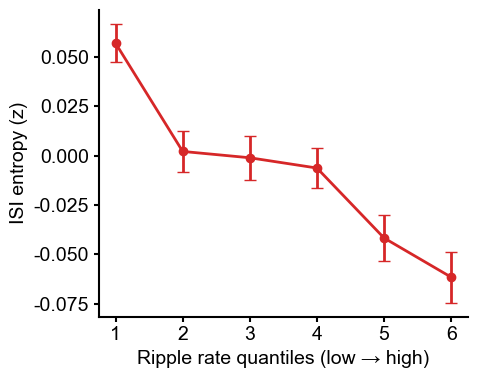

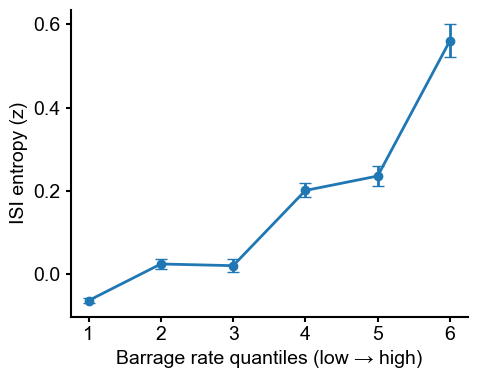

✅ Done. D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\S6_C_pooled_ISIentropyZ_vs_ripple_tile_after_rippleablate.svg

Ripple linear trend
  slope     : -0.0208365
  intercept : 0.0643789
  rvalue    : -0.952483
  pvalue    : 0.00333315
  stderr    : 0.00333161
  Pearson r   : -0.9525
  Pearson p   : 0.003333

Barrage linear trend
  slope     : 0.112657
  intercept : -0.231889
  rvalue    : 0.930084
  pvalue    : 0.00716153
  stderr    : 0.0222476
  Pearson r   : 0.9301
  Pearson p   : 0.007162


In [192]:
import os, glob, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib as mpl

# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# ==========================
# ---------- I/O ----------
def load_pooled_per_center(save_dir, state_filter="NREM"):
    if not os.path.isdir(save_dir): raise FileNotFoundError(save_dir)
    files = sorted(glob.glob(os.path.join(save_dir, "*.pkl")))
    if not files: raise FileNotFoundError(f"No .pkl in {save_dir}")

    want_num = ["center_s","isi_entropy","n_spikes","ripple_rate","barrage_rate"]
    out = []
    for f in files:
        try:
            obj = pd.read_pickle(f)
        except Exception:
            with open(f, "rb") as fh: obj = pickle.load(fh)

        if isinstance(obj, dict):
            df = obj.get("per_center")
            if not isinstance(df, pd.DataFrame): continue
            animal, day = obj.get("animal_name"), obj.get("day")
        elif isinstance(obj, pd.DataFrame):
            df, animal, day = obj.copy(), None, None
        else:
            continue

        base = os.path.splitext(os.path.basename(f))[0].split("_")
        df["animal_name"] = df.get("animal_name", animal or (base[0] if base else "unknown"))
        df["day"]         = df.get("day",         day    or (base[1] if len(base)>1 else "unknown"))

        if "state" in df.columns and state_filter is not None:
            df = df[df["state"].astype(str).str.lower()==str(state_filter).lower()]
            if df.empty: continue

        for c in want_num:
            if c in df.columns: df[c] = pd.to_numeric(df[c], errors="coerce")

        out.append(df)

    if not out: return pd.DataFrame()
    pooled = pd.concat(out, ignore_index=True)
    sort_cols = [c for c in ["animal_name","day","center_s"] if c in pooled.columns]
    return pooled.sort_values(sort_cols).reset_index(drop=True)

# ---------- per-session z ----------
def add_session_zscores(df, target_cols, session_cols=("animal_name","day"), robust=False, eps=1e-12):
    cols = [target_cols] if isinstance(target_cols, str) else list(target_cols)
    x, g = df.copy(), df.groupby(list(session_cols), dropna=False)
    for c in cols:
        if robust:
            med = g[c].transform("median")
            mad = g[c].transform(lambda s: np.median(np.abs(s - np.median(s))))
            z = (x[c]-med)/(1.4826*mad+eps)
        else:
            mu = g[c].transform("mean")
            sd = g[c].transform(lambda s: s.std(ddof=1))
            z = (x[c]-mu)/sd
        z = pd.to_numeric(z, errors="coerce"); z[~np.isfinite(z)] = np.nan
        x[f"{c}_z"] = z
    return x

# ---------- per-session tiles ----------
def add_session_tiles(df, by="ripple", k=6, session_cols=("animal_name","day"), middle_on_constant=True):
    rate = {"ripple":"ripple_rate","barrage":"barrage_rate"}.get(str(by).lower())
    if not rate: raise ValueError("by must be 'ripple' or 'barrage'")
    x = df.copy(); tcol = f"tile_{by}_sess"; x[tcol] = np.nan

    for _, sub in x.groupby(list(session_cols), dropna=False):
        idx = sub.index
        r   = pd.to_numeric(sub[rate], errors="coerce")
        ok  = r.index[r.to_numpy(float).astype(np.float64)==r.to_numpy(float)]  # keep index; numeric
        r   = r.loc[ok]; rvals = r.to_numpy(float); ok = ok[np.isfinite(rvals)]; rvals = rvals[np.isfinite(rvals)]
        if rvals.size < 2: continue

        try:
            q = pd.qcut(rvals, q=k, labels=False, duplicates="drop")
            lab = pd.Series(q.astype(int)+1, index=ok)
            # make consecutive 1..U
            uniq = {old:i+1 for i,old in enumerate(sorted(lab.unique()))}
            x.loc[lab.index, tcol] = lab.map(uniq).to_numpy(int)
        except Exception:
            if rvals.max() == rvals.min():
                if middle_on_constant: x.loc[ok, tcol] = int(np.ceil(k/2))
            else:
                ranks = pd.Series(rvals, index=ok).rank(method="average", pct=True)
                x.loc[ok, tcol] = np.clip(np.ceil(ranks*k).astype(int), 1, k)
    return x

# ---------- aggregate ----------
def aggregate_from_precomputed_tiles(df, tile_col, value_col, rate_col,
                                     session_cols=("animal_name","day"),
                                     equal_session_weight=True, error_mode="windows"):
    def sem(a):
        a = pd.to_numeric(pd.Series(a), errors="coerce"); a = a[np.isfinite(a)]
        return np.nan if a.size<=1 else float(a.std(ddof=1)/np.sqrt(a.size))

    need = {tile_col, value_col, rate_col}
    if missing := [c for c in need if c not in df.columns]: raise KeyError(f"Missing {missing}")

    x = df[np.isfinite(df[value_col]) & np.isfinite(df[rate_col]) & np.isfinite(df[tile_col])].copy()
    if x.empty:
        return pd.DataFrame(columns=[tile_col, f"{value_col}_mean", f"{value_col}_sem",
                                     f"{value_col}_median","n_sessions","n_windows",
                                     f"{rate_col}_mean",f"{rate_col}_min",f"{rate_col}_max"])

    if equal_session_weight:
        g1 = x.groupby(list(session_cols)+[tile_col], dropna=False)
        sess_val = g1[value_col].mean().rename("v")
        sess_rt  = g1[rate_col].mean().rename("r")
        g2 = sess_val.reset_index().groupby(tile_col, dropna=False)
        out = pd.DataFrame({
            f"{value_col}_mean":   g2["v"].mean(),
            f"{value_col}_median": g2["v"].median(),
            "n_sessions":          g2.size()
        }).reset_index()
        out["n_windows"] = x.groupby(tile_col, dropna=False).size().to_numpy()
        out[f"{value_col}_sem_sessions"] = g2["v"].apply(sem).to_numpy()
        out[f"{value_col}_sem_windows"]  = x.groupby(tile_col, dropna=False)[value_col].apply(sem).to_numpy()
        out[f"{rate_col}_mean"] = sess_rt.reset_index().groupby(tile_col)["r"].mean().to_numpy()
        out[f"{rate_col}_min"]  = sess_rt.reset_index().groupby(tile_col)["r"].min().to_numpy()
        out[f"{rate_col}_max"]  = sess_rt.reset_index().groupby(tile_col)["r"].max().to_numpy()
        if error_mode=="sessions":
            out[f"{value_col}_sem"] = out[f"{value_col}_sem_sessions"]
        elif error_mode=="windows":
            out[f"{value_col}_sem"] = out[f"{value_col}_sem_windows"]
        elif error_mode=="auto":
            y = out[f"{value_col}_sem_sessions"].to_numpy()
            y2= out[f"{value_col}_sem_windows"].to_numpy()
            n = out["n_sessions"].to_numpy(int)
            y[(n<2)|~np.isfinite(y)] = y2[(n<2)|~np.isfinite(y)]
            out[f"{value_col}_sem"] = y
        else:
            raise ValueError("error_mode ∈ {'sessions','windows','auto'}")
    else:
        g = x.groupby(tile_col, dropna=False)
        out = pd.DataFrame({
            f"{value_col}_mean":   g[value_col].mean(),
            f"{value_col}_median": g[value_col].median(),
            "n_windows":           g.size(),
            f"{value_col}_sem_windows": g[value_col].apply(sem),
            f"{rate_col}_mean": g[rate_col].mean(),
            f"{rate_col}_min" : g[rate_col].min(),
            f"{rate_col}_max" : g[rate_col].max(),
        }).reset_index()
        out["n_sessions"] = np.nan
        out[f"{value_col}_sem"] = out[f"{value_col}_sem_windows"]

    return out.sort_values(tile_col).reset_index(drop=True)

# ---------- plotting ----------
def plot_tiles_line(tiles_ripple, tiles_barrage, value_col="isi_entropy",
                    suptitle=None, figsize=(5,4), sharey=False,
                    tile_cols=("tile_ripple","tile_barrage")):
    import matplotlib.pyplot as plt
    import pandas as pd
    import numpy as np

    def style(ax):
        ax.grid(False)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    def plot_single(tbl, tcol, title, color):
        fig, ax = plt.subplots(figsize=figsize)
        style(ax)
        mean, sem = f"{value_col}_mean", f"{value_col}_sem"

        if not isinstance(tbl, pd.DataFrame) or tbl.empty or tcol not in tbl.columns:
            ax.text(0.5, 0.5, "No data", ha="center", va="center")
            return fig

        if mean not in tbl.columns:
            ax.text(0.5, 0.5, f"Missing '{mean}'", ha="center", va="center")
            return fig

        d = tbl.dropna(subset=[mean]).sort_values(tcol)
        if d.empty:
            ax.text(0.5, 0.5, "No valid data", ha="center", va="center")
            return fig

        x = d[tcol].to_numpy(int)
        y = d[mean].to_numpy(float)
        yerr = d[sem].to_numpy(float) if sem in d.columns else None
        ax.errorbar(x, y, yerr=yerr, marker="o", linewidth=2, capsize=4, color=color)
        ax.set_xticks(x)
        ax.set_xlabel(title)
        ax.set_ylabel("ISI entropy (z)")
        fig.tight_layout()
        return fig

    # Ripple plot
    fig_rip = plot_single(tiles_ripple, tile_cols[0],
                          "Ripple rate quantiles (low → high)",
                          color="tab:red")

    # Barrage plot
    fig_bar = plot_single(tiles_barrage, tile_cols[1],
                          "Barrage rate quantiles (low → high)",
                          color="tab:blue")


    return fig_rip, fig_bar


# ---------- pipeline ----------
if __name__ == "__main__":
    save_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\ripple_ablate\ISI_entropy"
    pooled_df = load_pooled_per_center(save_dir, state_filter="NREM")
    if pooled_df.empty: raise RuntimeError("No pooled data found.")

    pooled_df = add_session_tiles(pooled_df, by="ripple",  k=6)
    pooled_df = add_session_tiles(pooled_df, by="barrage", k=6)
    pooled_df = add_session_zscores(pooled_df, "isi_entropy", robust=False)

    tiles_rip = aggregate_from_precomputed_tiles(pooled_df, "tile_ripple_sess",  "isi_entropy_z", "ripple_rate")
    tiles_bar = aggregate_from_precomputed_tiles(pooled_df, "tile_barrage_sess", "isi_entropy_z", "barrage_rate")
    fig_rip, fig_bar = plot_tiles_line(
        tiles_rip, tiles_bar, value_col="isi_entropy_z",
        suptitle="Per-session z-scored ISI entropy (NREM, all animals)",
        tile_cols=("tile_ripple_sess","tile_barrage_sess")
    )
    plt.show()
    save_path=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary"
    out_plot = os.path.join(save_path, "S6_C_pooled_ISIentropyZ_vs_ripple_tile_after_rippleablate.svg")
    fig_rip.savefig(out_plot, dpi=300, bbox_inches="tight")
    fig_bar.savefig(out_plot.replace("_rippleablate.svg", "_barrage.svg"), dpi=300, bbox_inches="tight")
    print("✅ Done.", out_plot)
def compute_linear_trend(x, y, use_scipy=True):
    """
    Compute linear trend y = slope*x + intercept.

    Returns a dict with:
      slope, intercept, rvalue, pvalue, stderr
    """
    import numpy as np
    from scipy.stats import linregress

    x, y = np.asarray(x, float), np.asarray(y, float)
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 2:
        return dict(slope=np.nan, intercept=np.nan,
                    rvalue=np.nan, pvalue=np.nan, stderr=np.nan)

    if use_scipy:
        res = linregress(x[mask], y[mask])
        return dict(slope=float(res.slope), intercept=float(res.intercept),
                    rvalue=float(res.rvalue), pvalue=float(res.pvalue), stderr=float(res.stderr))
    else:
        A = np.vstack([x[mask], np.ones(mask.sum())]).T
        slope, intercept = np.linalg.lstsq(A, y[mask], rcond=None)[0]
        yhat = slope*x[mask] + intercept
        ss_res = np.sum((y[mask]-yhat)**2)
        ss_tot = np.sum((y[mask]-y[mask].mean())**2)
        r = np.sqrt(max(0, 1 - ss_res/ss_tot)) if ss_tot > 0 else np.nan
        return dict(slope=float(slope), intercept=float(intercept),
                    rvalue=float(r), pvalue=np.nan, stderr=np.nan)
# --- compute trends OUTSIDE the plot function ---

# Ripple
# --- compute & print linear trends (outside plotting) ---
# requires compute_linear_trend(x, y)
from scipy.stats import pearsonr

# --- linear trend ---
trend_rip = compute_linear_trend(
    tiles_rip["tile_ripple_sess"],
    tiles_rip["isi_entropy_z_mean"]
)
trend_bar = compute_linear_trend(
    tiles_bar["tile_barrage_sess"],
    tiles_bar["isi_entropy_z_mean"]
)

# --- Pearson correlation ---
def safe_pearsonr(x, y):
    import numpy as np
    from scipy.stats import pearsonr
    x, y = np.asarray(x, float), np.asarray(y, float)
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 2:
        return np.nan, np.nan
    r, p = pearsonr(x[mask], y[mask])
    return float(r), float(p)

r_rip, p_rip = safe_pearsonr(tiles_rip["tile_ripple_sess"], tiles_rip["isi_entropy_z_mean"])
r_bar, p_bar = safe_pearsonr(tiles_bar["tile_barrage_sess"], tiles_bar["isi_entropy_z_mean"])

# --- print results ---
print("\nRipple linear trend")
for k, v in trend_rip.items():
    print(f"  {k:10s}: {v:.6g}")
print(f"  Pearson r   : {r_rip:.4f}")
print(f"  Pearson p   : {p_rip:.4g}")

print("\nBarrage linear trend")
for k, v in trend_bar.items():
    print(f"  {k:10s}: {v:.6g}")
print(f"  Pearson r   : {r_bar:.4f}")
print(f"  Pearson p   : {p_bar:.4g}")

ablate_barr

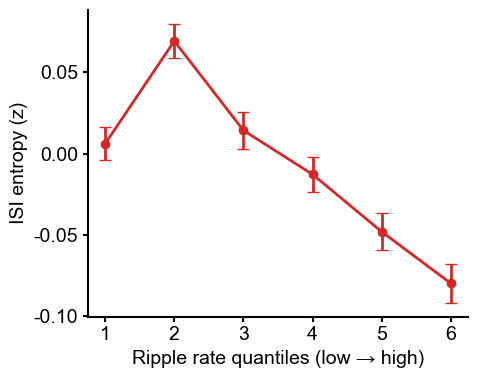

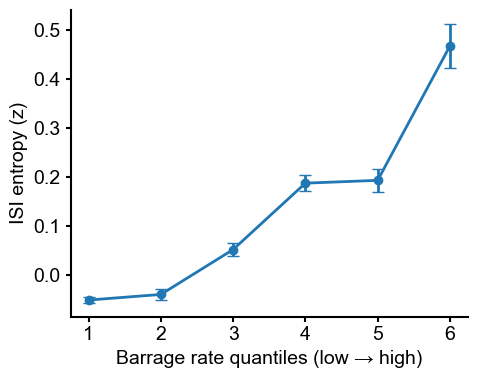

✅ Done. D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\S3_H_pooled_ISIentropyZ_vs_ripple_tile.svg

Ripple linear trend
  slope     : -0.0230798
  intercept : 0.0723616
  rvalue    : -0.833525
  pvalue    : 0.0392642
  stderr    : 0.00764893
  Pearson r   : -0.8335
  Pearson p   : 0.03926

Barrage linear trend
  slope     : 0.097706
  intercept : -0.206741
  rvalue    : 0.942922
  pvalue    : 0.00479387
  stderr    : 0.0172535
  Pearson r   : 0.9429
  Pearson p   : 0.004794


In [38]:
import os, glob, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
import matplotlib as mpl

# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# ==========================
# ---------- I/O ----------
def load_pooled_per_center(save_dir, state_filter="NREM"):
    if not os.path.isdir(save_dir): raise FileNotFoundError(save_dir)
    files = sorted(glob.glob(os.path.join(save_dir, "*.pkl")))
    if not files: raise FileNotFoundError(f"No .pkl in {save_dir}")

    want_num = ["center_s","isi_entropy","n_spikes","ripple_rate","barrage_rate"]
    out = []
    for f in files:
        try:
            obj = pd.read_pickle(f)
        except Exception:
            with open(f, "rb") as fh: obj = pickle.load(fh)

        if isinstance(obj, dict):
            df = obj.get("per_center")
            if not isinstance(df, pd.DataFrame): continue
            animal, day = obj.get("animal_name"), obj.get("day")
        elif isinstance(obj, pd.DataFrame):
            df, animal, day = obj.copy(), None, None
        else:
            continue

        base = os.path.splitext(os.path.basename(f))[0].split("_")
        df["animal_name"] = df.get("animal_name", animal or (base[0] if base else "unknown"))
        df["day"]         = df.get("day",         day    or (base[1] if len(base)>1 else "unknown"))

        if "state" in df.columns and state_filter is not None:
            df = df[df["state"].astype(str).str.lower()==str(state_filter).lower()]
            if df.empty: continue

        for c in want_num:
            if c in df.columns: df[c] = pd.to_numeric(df[c], errors="coerce")

        out.append(df)

    if not out: return pd.DataFrame()
    pooled = pd.concat(out, ignore_index=True)
    sort_cols = [c for c in ["animal_name","day","center_s"] if c in pooled.columns]
    return pooled.sort_values(sort_cols).reset_index(drop=True)

# ---------- per-session z ----------
def add_session_zscores(df, target_cols, session_cols=("animal_name","day"), robust=False, eps=1e-12):
    cols = [target_cols] if isinstance(target_cols, str) else list(target_cols)
    x, g = df.copy(), df.groupby(list(session_cols), dropna=False)
    for c in cols:
        if robust:
            med = g[c].transform("median")
            mad = g[c].transform(lambda s: np.median(np.abs(s - np.median(s))))
            z = (x[c]-med)/(1.4826*mad+eps)
        else:
            mu = g[c].transform("mean")
            sd = g[c].transform(lambda s: s.std(ddof=1))
            z = (x[c]-mu)/sd
        z = pd.to_numeric(z, errors="coerce"); z[~np.isfinite(z)] = np.nan
        x[f"{c}_z"] = z
    return x

# ---------- per-session tiles ----------
def add_session_tiles(df, by="ripple", k=6, session_cols=("animal_name","day"), middle_on_constant=True):
    rate = {"ripple":"ripple_rate","barrage":"barrage_rate"}.get(str(by).lower())
    if not rate: raise ValueError("by must be 'ripple' or 'barrage'")
    x = df.copy(); tcol = f"tile_{by}_sess"; x[tcol] = np.nan

    for _, sub in x.groupby(list(session_cols), dropna=False):
        idx = sub.index
        r   = pd.to_numeric(sub[rate], errors="coerce")
        ok  = r.index[r.to_numpy(float).astype(np.float64)==r.to_numpy(float)]  # keep index; numeric
        r   = r.loc[ok]; rvals = r.to_numpy(float); ok = ok[np.isfinite(rvals)]; rvals = rvals[np.isfinite(rvals)]
        if rvals.size < 2: continue

        try:
            q = pd.qcut(rvals, q=k, labels=False, duplicates="drop")
            lab = pd.Series(q.astype(int)+1, index=ok)
            # make consecutive 1..U
            uniq = {old:i+1 for i,old in enumerate(sorted(lab.unique()))}
            x.loc[lab.index, tcol] = lab.map(uniq).to_numpy(int)
        except Exception:
            if rvals.max() == rvals.min():
                if middle_on_constant: x.loc[ok, tcol] = int(np.ceil(k/2))
            else:
                ranks = pd.Series(rvals, index=ok).rank(method="average", pct=True)
                x.loc[ok, tcol] = np.clip(np.ceil(ranks*k).astype(int), 1, k)
    return x

# ---------- aggregate ----------
def aggregate_from_precomputed_tiles(df, tile_col, value_col, rate_col,
                                     session_cols=("animal_name","day"),
                                     equal_session_weight=True, error_mode="windows"):
    def sem(a):
        a = pd.to_numeric(pd.Series(a), errors="coerce"); a = a[np.isfinite(a)]
        return np.nan if a.size<=1 else float(a.std(ddof=1)/np.sqrt(a.size))

    need = {tile_col, value_col, rate_col}
    if missing := [c for c in need if c not in df.columns]: raise KeyError(f"Missing {missing}")

    x = df[np.isfinite(df[value_col]) & np.isfinite(df[rate_col]) & np.isfinite(df[tile_col])].copy()
    if x.empty:
        return pd.DataFrame(columns=[tile_col, f"{value_col}_mean", f"{value_col}_sem",
                                     f"{value_col}_median","n_sessions","n_windows",
                                     f"{rate_col}_mean",f"{rate_col}_min",f"{rate_col}_max"])

    if equal_session_weight:
        g1 = x.groupby(list(session_cols)+[tile_col], dropna=False)
        sess_val = g1[value_col].mean().rename("v")
        sess_rt  = g1[rate_col].mean().rename("r")
        g2 = sess_val.reset_index().groupby(tile_col, dropna=False)
        out = pd.DataFrame({
            f"{value_col}_mean":   g2["v"].mean(),
            f"{value_col}_median": g2["v"].median(),
            "n_sessions":          g2.size()
        }).reset_index()
        out["n_windows"] = x.groupby(tile_col, dropna=False).size().to_numpy()
        out[f"{value_col}_sem_sessions"] = g2["v"].apply(sem).to_numpy()
        out[f"{value_col}_sem_windows"]  = x.groupby(tile_col, dropna=False)[value_col].apply(sem).to_numpy()
        out[f"{rate_col}_mean"] = sess_rt.reset_index().groupby(tile_col)["r"].mean().to_numpy()
        out[f"{rate_col}_min"]  = sess_rt.reset_index().groupby(tile_col)["r"].min().to_numpy()
        out[f"{rate_col}_max"]  = sess_rt.reset_index().groupby(tile_col)["r"].max().to_numpy()
        if error_mode=="sessions":
            out[f"{value_col}_sem"] = out[f"{value_col}_sem_sessions"]
        elif error_mode=="windows":
            out[f"{value_col}_sem"] = out[f"{value_col}_sem_windows"]
        elif error_mode=="auto":
            y = out[f"{value_col}_sem_sessions"].to_numpy()
            y2= out[f"{value_col}_sem_windows"].to_numpy()
            n = out["n_sessions"].to_numpy(int)
            y[(n<2)|~np.isfinite(y)] = y2[(n<2)|~np.isfinite(y)]
            out[f"{value_col}_sem"] = y
        else:
            raise ValueError("error_mode ∈ {'sessions','windows','auto'}")
    else:
        g = x.groupby(tile_col, dropna=False)
        out = pd.DataFrame({
            f"{value_col}_mean":   g[value_col].mean(),
            f"{value_col}_median": g[value_col].median(),
            "n_windows":           g.size(),
            f"{value_col}_sem_windows": g[value_col].apply(sem),
            f"{rate_col}_mean": g[rate_col].mean(),
            f"{rate_col}_min" : g[rate_col].min(),
            f"{rate_col}_max" : g[rate_col].max(),
        }).reset_index()
        out["n_sessions"] = np.nan
        out[f"{value_col}_sem"] = out[f"{value_col}_sem_windows"]

    return out.sort_values(tile_col).reset_index(drop=True)

# ---------- plotting ----------
def plot_tiles_line(tiles_ripple, tiles_barrage, value_col="isi_entropy",
                    suptitle=None, figsize=(5,4), sharey=False,
                    tile_cols=("tile_ripple","tile_barrage")):
    import matplotlib.pyplot as plt
    import pandas as pd
    import numpy as np

    def style(ax):
        ax.grid(False)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    def plot_single(tbl, tcol, title, color):
        fig, ax = plt.subplots(figsize=figsize)
        style(ax)
        mean, sem = f"{value_col}_mean", f"{value_col}_sem"

        if not isinstance(tbl, pd.DataFrame) or tbl.empty or tcol not in tbl.columns:
            ax.text(0.5, 0.5, "No data", ha="center", va="center")
            return fig

        if mean not in tbl.columns:
            ax.text(0.5, 0.5, f"Missing '{mean}'", ha="center", va="center")
            return fig

        d = tbl.dropna(subset=[mean]).sort_values(tcol)
        if d.empty:
            ax.text(0.5, 0.5, "No valid data", ha="center", va="center")
            return fig

        x = d[tcol].to_numpy(int)
        y = d[mean].to_numpy(float)
        yerr = d[sem].to_numpy(float) if sem in d.columns else None
        ax.errorbar(x, y, yerr=yerr, marker="o", linewidth=2, capsize=4, color=color)
        ax.set_xticks(x)
        ax.set_xlabel(title)
        ax.set_ylabel("ISI entropy (z)")
        fig.tight_layout()
        return fig

    # Ripple plot
    fig_rip = plot_single(tiles_ripple, tile_cols[0],
                          "Ripple rate quantiles (low → high)",
                          color="tab:red")

    # Barrage plot
    fig_bar = plot_single(tiles_barrage, tile_cols[1],
                          "Barrage rate quantiles (low → high)",
                          color="tab:blue")


    return fig_rip, fig_bar


# ---------- pipeline ----------
if __name__ == "__main__":
    save_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\barr_ablate"
    pooled_df = load_pooled_per_center(save_dir, state_filter="NREM")
    if pooled_df.empty: raise RuntimeError("No pooled data found.")

    pooled_df = add_session_tiles(pooled_df, by="ripple",  k=6)
    pooled_df = add_session_tiles(pooled_df, by="barrage", k=6)
    pooled_df = add_session_zscores(pooled_df, "isi_entropy", robust=False)

    tiles_rip = aggregate_from_precomputed_tiles(pooled_df, "tile_ripple_sess",  "isi_entropy_z", "ripple_rate")
    tiles_bar = aggregate_from_precomputed_tiles(pooled_df, "tile_barrage_sess", "isi_entropy_z", "barrage_rate")
    fig_rip, fig_bar = plot_tiles_line(
        tiles_rip, tiles_bar, value_col="isi_entropy_z",
        suptitle="Per-session z-scored ISI entropy (NREM, all animals)",
        tile_cols=("tile_ripple_sess","tile_barrage_sess")
    )
    plt.show()
    save_path=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary"
    out_plot = os.path.join(save_path, "S3_H_pooled_ISIentropyZ_vs_ripple_tile.svg")
    fig_rip.savefig(out_plot, dpi=300, bbox_inches="tight")
    fig_bar.savefig(out_plot.replace("_ripple_tile.svg", "_barrage.svg"), dpi=300, bbox_inches="tight")
    print("✅ Done.", out_plot)
def compute_linear_trend(x, y, use_scipy=True):
    """
    Compute linear trend y = slope*x + intercept.

    Returns a dict with:
      slope, intercept, rvalue, pvalue, stderr
    """
    import numpy as np
    from scipy.stats import linregress

    x, y = np.asarray(x, float), np.asarray(y, float)
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 2:
        return dict(slope=np.nan, intercept=np.nan,
                    rvalue=np.nan, pvalue=np.nan, stderr=np.nan)

    if use_scipy:
        res = linregress(x[mask], y[mask])
        return dict(slope=float(res.slope), intercept=float(res.intercept),
                    rvalue=float(res.rvalue), pvalue=float(res.pvalue), stderr=float(res.stderr))
    else:
        A = np.vstack([x[mask], np.ones(mask.sum())]).T
        slope, intercept = np.linalg.lstsq(A, y[mask], rcond=None)[0]
        yhat = slope*x[mask] + intercept
        ss_res = np.sum((y[mask]-yhat)**2)
        ss_tot = np.sum((y[mask]-y[mask].mean())**2)
        r = np.sqrt(max(0, 1 - ss_res/ss_tot)) if ss_tot > 0 else np.nan
        return dict(slope=float(slope), intercept=float(intercept),
                    rvalue=float(r), pvalue=np.nan, stderr=np.nan)
# --- compute trends OUTSIDE the plot function ---

# Ripple
# --- compute & print linear trends (outside plotting) ---
# requires compute_linear_trend(x, y)
from scipy.stats import pearsonr

# --- linear trend ---
trend_rip = compute_linear_trend(
    tiles_rip["tile_ripple_sess"],
    tiles_rip["isi_entropy_z_mean"]
)
trend_bar = compute_linear_trend(
    tiles_bar["tile_barrage_sess"],
    tiles_bar["isi_entropy_z_mean"]
)

# --- Pearson correlation ---
def safe_pearsonr(x, y):
    import numpy as np
    from scipy.stats import pearsonr
    x, y = np.asarray(x, float), np.asarray(y, float)
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 2:
        return np.nan, np.nan
    r, p = pearsonr(x[mask], y[mask])
    return float(r), float(p)

r_rip, p_rip = safe_pearsonr(tiles_rip["tile_ripple_sess"], tiles_rip["isi_entropy_z_mean"])
r_bar, p_bar = safe_pearsonr(tiles_bar["tile_barrage_sess"], tiles_bar["isi_entropy_z_mean"])

# --- print results ---
print("\nRipple linear trend")
for k, v in trend_rip.items():
    print(f"  {k:10s}: {v:.6g}")
print(f"  Pearson r   : {r_rip:.4f}")
print(f"  Pearson p   : {p_rip:.4g}")

print("\nBarrage linear trend")
for k, v in trend_bar.items():
    print(f"  {k:10s}: {v:.6g}")
print(f"  Pearson r   : {r_bar:.4f}")
print(f"  Pearson p   : {p_bar:.4g}")

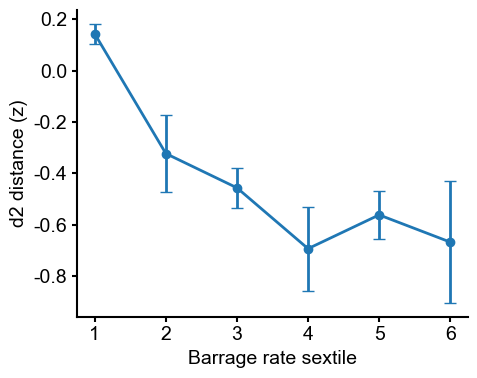

✅ Saved: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary\S3_H_pooled_D2Z_vs_barrage_tile_equalwidth.svg

Barrage: D2(z) vs tile trend
  slope     : -0.143059
  intercept : 0.0740364
  rvalue    : -0.86054
  pvalue    : 0.0278174
  stderr    : 0.0423407
  Pearson r   : -0.8605
  Pearson p   : 0.02782

✅ Done.


In [11]:
import os, glob, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

# ==========================
# ---------- STYLE ----------
# ==========================
mpl.rcParams['svg.fonttype'] = 'none'
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

mpl.rcParams['axes.unicode_minus'] = False
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5
mpl.rcParams["xtick.major.width"] = 1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5


# ==========================
# ---------- I/O ----------
# ==========================
def load_pooled_per_center(save_dir, state_filter="NREM"):
    """
    Loads all *.pkl in save_dir. Each pkl is either:
      - dict with key "per_center" (DataFrame), or
      - a DataFrame directly
    """
    if not os.path.isdir(save_dir):
        raise FileNotFoundError(save_dir)
    files = sorted(glob.glob(os.path.join(save_dir, "*.pkl")))
    if not files:
        raise FileNotFoundError(f"No .pkl in {save_dir}")

    want_num = ["center_s", "d2", "n_spikes", "ripple_rate", "barrage_rate"]

    out = []
    for f in files:
        try:
            obj = pd.read_pickle(f)
        except Exception:
            with open(f, "rb") as fh:
                obj = pickle.load(fh)

        if isinstance(obj, dict):
            df = obj.get("per_center")
            if not isinstance(df, pd.DataFrame):
                continue
            animal, day = obj.get("animal_name"), obj.get("day")
        elif isinstance(obj, pd.DataFrame):
            df, animal, day = obj.copy(), None, None
        else:
            continue

        base = os.path.splitext(os.path.basename(f))[0].split("_")
        df["animal_name"] = df.get("animal_name", animal or (base[0] if base else "unknown"))
        df["day"]         = df.get("day",         day    or (base[1] if len(base) > 1 else "unknown"))

        if "state" in df.columns and state_filter is not None:
            df = df[df["state"].astype(str).str.lower() == str(state_filter).lower()]
            if df.empty:
                continue

        for c in want_num:
            if c in df.columns:
                df[c] = pd.to_numeric(df[c], errors="coerce")

        out.append(df)

    if not out:
        return pd.DataFrame()

    pooled = pd.concat(out, ignore_index=True)
    sort_cols = [c for c in ["animal_name", "day", "center_s"] if c in pooled.columns]
    return pooled.sort_values(sort_cols).reset_index(drop=True)


# ==========================
# ------ per-session z ------
# ==========================
def add_session_zscores(df, target_cols, session_cols=("animal_name", "day"), robust=False, eps=1e-12):
    """
    Adds per-session z-scores for target_cols:
      new column name: f"{col}_z"
    """
    cols = [target_cols] if isinstance(target_cols, str) else list(target_cols)
    x = df.copy()
    g = x.groupby(list(session_cols), dropna=False)

    for c in cols:
        if c not in x.columns:
            raise KeyError(f"Missing target col: {c}")

        if robust:
            med = g[c].transform("median")
            mad = g[c].transform(lambda s: np.median(np.abs(s - np.median(s))))
            z = (x[c] - med) / (1.4826 * mad + eps)
        else:
            mu = g[c].transform("mean")
            sd = g[c].transform(lambda s: s.std(ddof=1))
            z = (x[c] - mu) / sd

        z = pd.to_numeric(z, errors="coerce")
        z[~np.isfinite(z)] = np.nan
        x[f"{c}_z"] = z

    return x


# ==========================
# ------ per-session tiles ---
# ==========================
def add_session_tiles(
    df,
    by="barrage",
    k=6,
    mode="quantile",  # "quantile" (equal-count) OR "width" (equal-width)
    session_cols=("animal_name", "day"),
    middle_on_constant=True,
    eps=1e-12
):
    """
    Adds per-session tiles for rate (barrage or ripple).

    mode:
      - "quantile": equal-count bins per session (uses qcut; fallback to rank-percentiles)
      - "width":    equal-width bins per session (uses cut on [min,max])

    tile column name: tile_{by}_sess
    """
    rate = {"ripple": "ripple_rate", "barrage": "barrage_rate"}.get(str(by).lower())
    if not rate:
        raise ValueError("by must be 'ripple' or 'barrage'")

    mode = str(mode).lower()
    if mode not in ("quantile", "width"):
        raise ValueError("mode must be 'quantile' or 'width'")

    x = df.copy()
    tcol = f"tile_{by}_sess"
    x[tcol] = np.nan

    for _, sub in x.groupby(list(session_cols), dropna=False):
        r = pd.to_numeric(sub[rate], errors="coerce")
        ok = r.index[np.isfinite(r.to_numpy(float))]
        r = r.loc[ok]
        rvals = r.to_numpy(float)
        ok = ok[np.isfinite(rvals)]
        rvals = rvals[np.isfinite(rvals)]

        if rvals.size < 2:
            continue

        rmin, rmax = float(np.nanmin(rvals)), float(np.nanmax(rvals))

        # constant session
        if not np.isfinite(rmin) or not np.isfinite(rmax) or abs(rmax - rmin) < eps:
            if middle_on_constant:
                x.loc[ok, tcol] = int(np.ceil(k / 2))
            continue

        if mode == "quantile":
            # Equal-count bins
            try:
                q = pd.qcut(rvals, q=k, labels=False, duplicates="drop")
                lab = pd.Series(q.astype(int) + 1, index=ok)
                # compress to consecutive 1..U if duplicates="drop" reduced bins
                uniq = {old: i + 1 for i, old in enumerate(sorted(lab.unique()))}
                x.loc[lab.index, tcol] = lab.map(uniq).to_numpy(int)
            except Exception:
                # fallback: percentile ranks (still equal-count-ish)
                ranks = pd.Series(rvals, index=ok).rank(method="average", pct=True)
                x.loc[ok, tcol] = np.clip(np.ceil(ranks * k).astype(int), 1, k)

        else:
            # mode == "width": Equal-width bins between min and max
            # bins edges: [min, ..., max], with include_lowest=True
            try:
                b = pd.cut(
                    rvals,
                    bins=k,
                    labels=False,
                    include_lowest=True,
                    right=True
                )
                # b is 0..(k-1); make it 1..k
                lab = pd.Series(b.astype(int) + 1, index=ok)
                x.loc[lab.index, tcol] = lab.to_numpy(int)
            except Exception:
                # fallback: manual equal-width via normalized position
                frac = (rvals - rmin) / (rmax - rmin)
                x.loc[ok, tcol] = np.clip(np.floor(frac * k).astype(int) + 1, 1, k)

    return x


# ==========================
# -------- aggregate --------
# ==========================
def aggregate_from_precomputed_tiles(
    df, tile_col, value_col, rate_col,
    session_cols=("animal_name", "day"),
    equal_session_weight=True,
    error_mode="sessions"
):
    """
    Aggregates value_col within each tile:
      - equal_session_weight=True: average session means (each session counts equally)
      - error_mode: 'sessions'|'windows'|'auto'
    """
    def sem(a):
        a = pd.to_numeric(pd.Series(a), errors="coerce")
        a = a[np.isfinite(a)]
        return np.nan if a.size <= 1 else float(a.std(ddof=1) / np.sqrt(a.size))

    need = {tile_col, value_col, rate_col}
    missing = [c for c in need if c not in df.columns]
    if missing:
        raise KeyError(f"Missing {missing}")

    x = df[np.isfinite(df[value_col]) & np.isfinite(df[rate_col]) & np.isfinite(df[tile_col])].copy()
    if x.empty:
        return pd.DataFrame(columns=[tile_col, f"{value_col}_mean", f"{value_col}_sem",
                                     f"{value_col}_median", "n_sessions", "n_windows",
                                     f"{rate_col}_mean", f"{rate_col}_min", f"{rate_col}_max"])

    if equal_session_weight:
        g1 = x.groupby(list(session_cols) + [tile_col], dropna=False)
        sess_val = g1[value_col].mean().rename("v")
        sess_rt  = g1[rate_col].mean().rename("r")

        g2 = sess_val.reset_index().groupby(tile_col, dropna=False)
        out = pd.DataFrame({
            tile_col: g2.size().index,
            f"{value_col}_mean":   g2["v"].mean().to_numpy(),
            f"{value_col}_median": g2["v"].median().to_numpy(),
            "n_sessions":          g2.size().to_numpy()
        })

        out["n_windows"] = x.groupby(tile_col, dropna=False).size().reindex(out[tile_col]).to_numpy()

        sem_sessions = g2["v"].apply(sem).reindex(out[tile_col]).to_numpy()
        sem_windows  = x.groupby(tile_col, dropna=False)[value_col].apply(sem).reindex(out[tile_col]).to_numpy()

        out[f"{value_col}_sem_sessions"] = sem_sessions
        out[f"{value_col}_sem_windows"]  = sem_windows

        rt_by_tile = sess_rt.reset_index().groupby(tile_col)["r"]
        out[f"{rate_col}_mean"] = rt_by_tile.mean().reindex(out[tile_col]).to_numpy()
        out[f"{rate_col}_min"]  = rt_by_tile.min().reindex(out[tile_col]).to_numpy()
        out[f"{rate_col}_max"]  = rt_by_tile.max().reindex(out[tile_col]).to_numpy()

        if error_mode == "sessions":
            out[f"{value_col}_sem"] = out[f"{value_col}_sem_sessions"]
        elif error_mode == "windows":
            out[f"{value_col}_sem"] = out[f"{value_col}_sem_windows"]
        elif error_mode == "auto":
            y = out[f"{value_col}_sem_sessions"].to_numpy()
            y2 = out[f"{value_col}_sem_windows"].to_numpy()
            n = out["n_sessions"].to_numpy(int)
            bad = (n < 2) | (~np.isfinite(y))
            y[bad] = y2[bad]
            out[f"{value_col}_sem"] = y
        else:
            raise ValueError("error_mode ∈ {'sessions','windows','auto'}")
    else:
        g = x.groupby(tile_col, dropna=False)
        out = pd.DataFrame({
            tile_col: g.size().index,
            f"{value_col}_mean":   g[value_col].mean().to_numpy(),
            f"{value_col}_median": g[value_col].median().to_numpy(),
            "n_windows":           g.size().to_numpy(),
            f"{value_col}_sem_windows": g[value_col].apply(sem).to_numpy(),
            f"{rate_col}_mean": g[rate_col].mean().to_numpy(),
            f"{rate_col}_min":  g[rate_col].min().to_numpy(),
            f"{rate_col}_max":  g[rate_col].max().to_numpy(),
        })
        out["n_sessions"] = np.nan
        out[f"{value_col}_sem"] = out[f"{value_col}_sem_windows"]

    return out.sort_values(tile_col).reset_index(drop=True)


# ==========================
# -------- plotting ---------
# ==========================
def plot_tiles_line_barrage_only(
    tiles_barrage,
    value_col="d2_z",
    suptitle=None,
    figsize=(5, 4),
    tile_col="tile_barrage_sess"
):
    """
    Single-panel line plot: d2 (z/session) vs barrage-rate tiles.
    Uses the SEM column produced by aggregate_from_precomputed_tiles:
      f"{value_col}_sem"
    """
    def style(ax):
        ax.grid(False)
        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)

    fig, ax = plt.subplots(figsize=figsize)
    style(ax)

    mean_col = f"{value_col}_mean"
    sem_col  = f"{value_col}_sem"

    if not isinstance(tiles_barrage, pd.DataFrame) or tiles_barrage.empty:
        ax.text(0.5, 0.5, "No data", ha="center", va="center")
        return fig

    if mean_col not in tiles_barrage.columns or tile_col not in tiles_barrage.columns:
        ax.text(0.5, 0.5, f"Missing '{mean_col}' or '{tile_col}'", ha="center", va="center")
        return fig

    d = tiles_barrage.dropna(subset=[mean_col]).sort_values(tile_col)
    if d.empty:
        ax.text(0.5, 0.5, "No valid data", ha="center", va="center")
        return fig

    x = d[tile_col].to_numpy(int)
    y = d[mean_col].to_numpy(float)
    yerr = d[sem_col].to_numpy(float) if sem_col in d.columns else None

    ax.errorbar(x, y, yerr=yerr, marker="o", linewidth=2, capsize=4, color="tab:blue")
    ax.set_xticks(x)
    ax.set_xlabel("Barrage rate sextile")
    ax.set_ylabel("d2 distance (z)")

    if suptitle:
        fig.suptitle(suptitle, y=1.02)

    fig.tight_layout()
    return fig


# ==========================
# ----- trend helpers -------
# ==========================
def compute_linear_trend(x, y, use_scipy=True):
    """
    Compute linear trend y = slope*x + intercept.

    Returns dict with:
      slope, intercept, rvalue, pvalue, stderr
    """
    from scipy.stats import linregress
    x, y = np.asarray(x, float), np.asarray(y, float)
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 2:
        return dict(slope=np.nan, intercept=np.nan,
                    rvalue=np.nan, pvalue=np.nan, stderr=np.nan)

    if use_scipy:
        res = linregress(x[mask], y[mask])
        return dict(slope=float(res.slope), intercept=float(res.intercept),
                    rvalue=float(res.rvalue), pvalue=float(res.pvalue), stderr=float(res.stderr))

    A = np.vstack([x[mask], np.ones(mask.sum())]).T
    slope, intercept = np.linalg.lstsq(A, y[mask], rcond=None)[0]
    yhat = slope * x[mask] + intercept
    ss_res = np.sum((y[mask] - yhat) ** 2)
    ss_tot = np.sum((y[mask] - y[mask].mean()) ** 2)
    r = np.sqrt(max(0, 1 - ss_res / ss_tot)) if ss_tot > 0 else np.nan
    return dict(slope=float(slope), intercept=float(intercept),
                rvalue=float(r), pvalue=np.nan, stderr=np.nan)


def safe_pearsonr(x, y):
    from scipy.stats import pearsonr
    x, y = np.asarray(x, float), np.asarray(y, float)
    mask = np.isfinite(x) & np.isfinite(y)
    if mask.sum() < 2:
        return np.nan, np.nan
    r, p = pearsonr(x[mask], y[mask])
    return float(r), float(p)


# ==========================
# ---------- pipeline -------
# ==========================
if __name__ == "__main__":
    save_dir = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\barr_ablate"
    save_path = r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_planc\supplementary"

    # Choose tile mode:
    #   "quantile" -> sextiles/equal-count (pd.qcut)
    #   "width"    -> equal-width bins (pd.cut)
    TILE_MODE = "width"  # change to "width" for equal-width tiles
    K_TILES = 6

    pooled_df = load_pooled_per_center(save_dir, state_filter="NREM")
    if pooled_df.empty:
        raise RuntimeError("No pooled data found.")

    if "d2" not in pooled_df.columns:
        raise KeyError("Your pooled_df has no 'd2' column. Check your per_center outputs.")
    if "barrage_rate" not in pooled_df.columns:
        raise KeyError("Your pooled_df has no 'barrage_rate' column. Check your per_center outputs.")

    # Tiles: barrage only, per-session
    pooled_df = add_session_tiles(pooled_df, by="barrage", k=K_TILES, mode=TILE_MODE)

    # Z-score d2 within (animal_name, day)
    pooled_df = add_session_zscores(pooled_df, "d2", robust=False)

    # Aggregate d2_z vs barrage tiles
    tiles_bar = aggregate_from_precomputed_tiles(
        pooled_df,
        tile_col="tile_barrage_sess",
        value_col="d2_z",
        rate_col="barrage_rate",
        equal_session_weight=True,
        error_mode="sessions"   # cross-session SEM (SEM of session means)
    )

    # Plot
    fig_bar = plot_tiles_line_barrage_only(
        tiles_bar,
        value_col="d2_z",
        suptitle=None,
        tile_col="tile_barrage_sess"
    )
    plt.show()

    # Save
    os.makedirs(save_path, exist_ok=True)
    tag = "sextile" if TILE_MODE == "quantile" else "equalwidth"
    out_plot = os.path.join(save_path, f"S3_H_pooled_D2Z_vs_barrage_tile_{tag}.svg")
    fig_bar.savefig(out_plot, dpi=300, bbox_inches="tight")
    print("✅ Saved:", out_plot)

    # Trends (on tile means)
    trend_bar = compute_linear_trend(
        tiles_bar["tile_barrage_sess"],
        tiles_bar["d2_z_mean"]
    )
    r_bar, p_bar = safe_pearsonr(
        tiles_bar["tile_barrage_sess"],
        tiles_bar["d2_z_mean"]
    )

    print("\nBarrage: D2(z) vs tile trend")
    for k, v in trend_bar.items():
        print(f"  {k:10s}: {v:.6g}")
    print(f"  Pearson r   : {r_bar:.4f}")
    print(f"  Pearson p   : {p_bar:.4g}")

    print("\n✅ Done.")

S4 C

Paired Wilcoxon signed-rank test results (grouping by animal_name and day):
Avalanche Size - Alpha:     W = 9.000, p = 3.07e-08
Avalanche Duration - Alpha: W = 11.000, p = 1.02e-07
Avalanche Size - KS_stat:   W = 45.000, p = 1.54e-05
Avalanche Duration - KS_stat: W = 110.000, p = 1.06e-02


C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\2293530823.py:182: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\2293530823.py:190: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\2293530823.py:198: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\2293530823.py:204: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for th

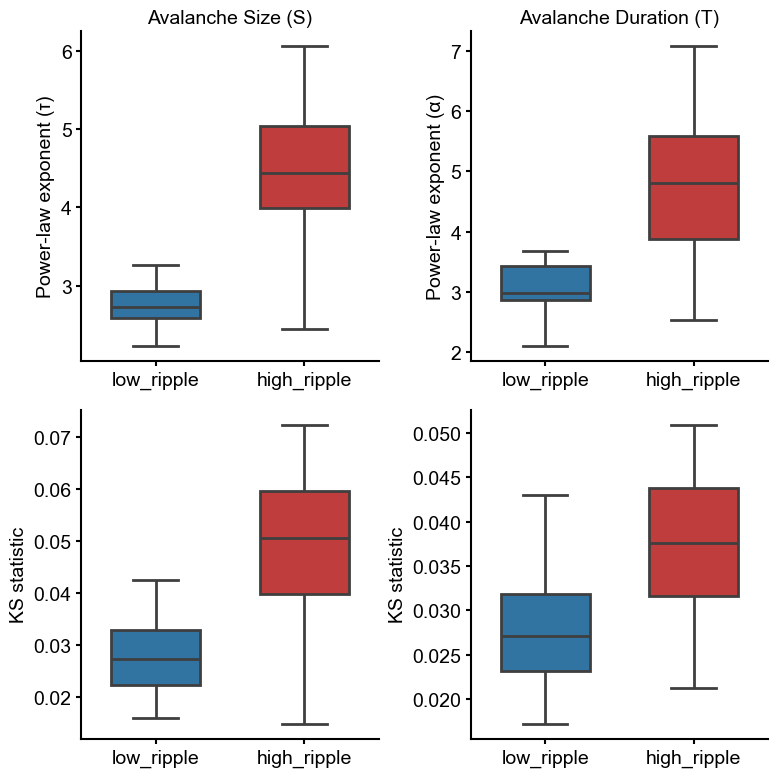

Avalanche Size (alpha):
  high_ripple: median = 4.436
  low_ripple: median = 2.723

Avalanche Duration (alpha):
  high_ripple: median = 4.806
  low_ripple: median = 2.984

Avalanche Size (ks_stat):
  high_ripple: median = 0.051
  low_ripple: median = 0.027

Avalanche Duration (ks_stat):
  high_ripple: median = 0.038
  low_ripple: median = 0.027

Total sessions = 31
Total animals  = 6


In [158]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import ttest_rel
import os, re, glob, numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
# ---------- Summary stats ----------
import os, glob, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl


# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# Load both CSV files for alpha
csv_path_alpha_size = r"D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples\log\av_size_all_sleep.csv"
csv_path_alpha_duration = r"D:\Documents\GitHub\Sleep_criticaltiy\data\l_h_ripples\log\av_duration_all_sleep.csv"

df_size = pd.read_csv(csv_path_alpha_size)
df_duration = pd.read_csv(csv_path_alpha_duration)

# ---------------------------
# 2. Filter for sleep_idx == 0 or 4.
# ---------------------------
# 3. Check that each dataset has exactly 2 labels.
# ---------------------------
labels_size = df_size['label'].unique()
labels_duration = df_duration['label'].unique()

assert len(labels_size) == 2, f"Expected exactly 2 labels for size, got {labels_size}"
assert len(labels_duration) == 2, f"Expected exactly 2 labels for duration, got {labels_duration}"

# ---------------------------
# 4. Function to pivot the DataFrame for a given measure ('alpha' or 'ks_stat').
# ---------------------------
def create_pivot(df, measure):
    # Pivot with index consisting of animal_name, day, and sleep_idx.
    pivot_df = df.pivot_table(
        index=['animal_name', 'day', 'sleep_idx'],
        columns='label',
        values=measure
    ).dropna()
    return pivot_df

# Create pivot tables for both measures and for both CSV files.
# For avalanche size.
pivot_size_alpha = create_pivot(df_size, 'alpha')
pivot_size_ks    = create_pivot(df_size, 'ks_stat')

# For avalanche duration.
pivot_duration_alpha = create_pivot(df_duration, 'alpha')
pivot_duration_ks    = create_pivot(df_duration, 'ks_stat')

# ---------------------------
# 5. Group the pivot data by (animal_name, day), averaging if needed.
# This provides one value per (animal, day) pair.
# ---------------------------
grouped_size_alpha = pivot_size_alpha.reset_index().groupby(['animal_name', 'day', 'sleep_idx']).mean()
grouped_duration_alpha = pivot_duration_alpha.reset_index().groupby(['animal_name', 'day', 'sleep_idx']).mean()
grouped_size_ks = pivot_size_ks.reset_index().groupby(['animal_name', 'day', 'sleep_idx']).mean()
grouped_duration_ks = pivot_duration_ks.reset_index().groupby(['animal_name', 'day', 'sleep_idx']).mean()

# ---------------------------
# 6. Perform paired t-tests on the grouped data.
# ---------------------------
# For alpha measure.
from scipy.stats import wilcoxon
import numpy as np
from scipy.stats import wilcoxon

def paired_wilcoxon_with_n(x, y):
    x = np.asarray(x, float)
    y = np.asarray(y, float)
    mask = np.isfinite(x) & np.isfinite(y)
    n_sessions = mask.sum()
    
    if n_sessions < 2:
        return np.nan, np.nan, n_sessions
    
    stat, p = wilcoxon(x[mask], y[mask])
    return stat, p, n_sessions

# --- Alpha (power-law exponent) ---
w_stat_size_alpha, p_val_size_alpha, n_size_alpha = paired_wilcoxon_with_n(
    grouped_size_alpha["low_ripple"],
    grouped_size_alpha["high_ripple"]
)

w_stat_duration_alpha, p_val_duration_alpha, n_duration_alpha = paired_wilcoxon_with_n(
    grouped_duration_alpha["low_ripple"],
    grouped_duration_alpha["high_ripple"]
)

# --- KS statistic ---
w_stat_size_ks, p_val_size_ks, n_size_ks = paired_wilcoxon_with_n(
    grouped_size_ks["low_ripple"],
    grouped_size_ks["high_ripple"]
)

w_stat_duration_ks, p_val_duration_ks, n_duration_ks = paired_wilcoxon_with_n(
    grouped_duration_ks["low_ripple"],
    grouped_duration_ks["high_ripple"]
)


print("Paired Wilcoxon signed-rank test results (grouping by animal_name and day):")
print(f"Avalanche Size - Alpha:     W = {w_stat_size_alpha:.3f}, p = {p_val_size_alpha:.2e}")
print(f"Avalanche Duration - Alpha: W = {w_stat_duration_alpha:.3f}, p = {p_val_duration_alpha:.2e}")
print(f"Avalanche Size - KS_stat:   W = {w_stat_size_ks:.3f}, p = {p_val_size_ks:.2e}")
print(f"Avalanche Duration - KS_stat: W = {w_stat_duration_ks:.3f}, p = {p_val_duration_ks:.2e}")
# ---------------------------
# 7. Melt the grouped data for plotting.
# ---------------------------
def melt_grouped(grouped_df, measure):
    # grouped_df has index ['animal_name', 'day'] and columns (labels)
    return grouped_df.reset_index().melt(id_vars=['animal_name', 'day', 'sleep_idx'],
                                         value_vars=["low_ripple", "high_ripple"],
                                         var_name='Label',
                                         value_name=measure)

melted_size_alpha = melt_grouped(grouped_size_alpha, 'alpha')
melted_duration_alpha = melt_grouped(grouped_duration_alpha, 'alpha')
melted_size_ks = melt_grouped(grouped_size_ks, 'ks_stat')
melted_duration_ks = melt_grouped(grouped_duration_ks, 'ks_stat')

# ---------------------------
# 8. Plotting: 2 rows x 2 columns.
# Row 0: Avalanche Size and Duration for "alpha"
# Row 1: Avalanche Size and Duration for "ks_stat"
# The boxplot order is explicitly set to display "low_ripple" first.
# ---------------------------
import matplotlib.pyplot as plt
import seaborn as sns

# Create a 2x2 grid of subplots
fig, axes = plt.subplots(2, 2, figsize=(8, 8))
palette = {"low_ripple": "tab:blue", "high_ripple": "tab:red"}
# Top row: Alpha measure.
# Avalanche Size (left)
sns.boxplot(data=melted_size_alpha, x='Label', y='alpha', palette=palette,
            showfliers=False, width=0.6,linewidth=2, order=["low_ripple", "high_ripple"], ax=axes[0, 0])
axes[0, 0].set_title(f"Avalanche Size (S)")
axes[0, 0].set_ylabel("Power-law exponent (τ)")

axes[0, 0].grid(False)

# Avalanche Duration (right)
sns.boxplot(data=melted_duration_alpha, x='Label', y='alpha', palette=palette,
            showfliers=False, width=0.6,linewidth=2, order=["low_ripple", "high_ripple"], ax=axes[0, 1])
axes[0, 1].set_title(f"Avalanche Duration (T)")
axes[0, 1].set_ylabel("Power-law exponent (α)")
axes[0, 1].grid(False)

# Bottom row: KS stat.
# Avalanche Size (left)
sns.boxplot(data=melted_size_ks, x='Label', y='ks_stat', palette=palette,
            showfliers=False, width=0.6,linewidth=2, order=["low_ripple", "high_ripple"], ax=axes[1, 0])
axes[1, 0].set_ylabel("KS statistic")
axes[1, 0].grid(False)

# Avalanche Duration (right)
sns.boxplot(data=melted_duration_ks, x='Label', y='ks_stat', palette=palette,
            showfliers=False, width=0.6,linewidth=2, order=["low_ripple", "high_ripple"], ax=axes[1, 1])
axes[1, 1].set_ylabel("KS statistic")
axes[1, 1].grid(False)
for ax in axes.flatten():
    ax.set_xlabel("")  # remove "Label" from all subplots
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig(r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\figS4_C_low_high_ripple_avalanche_fit_bar_equalsample.svg")  # SVG is vector-based
plt.show()
# Compute and print median values for each condition
for title, (df_name, col_name) in {
    "Avalanche Size (alpha)": ("melted_size_alpha", "alpha"),
    "Avalanche Duration (alpha)": ("melted_duration_alpha", "alpha"),
    "Avalanche Size (ks_stat)": ("melted_size_ks", "ks_stat"),
    "Avalanche Duration (ks_stat)": ("melted_duration_ks", "ks_stat"),
}.items():
    df = globals()[df_name]  # Get DataFrame from variable name
    medians = df.groupby("Label")[col_name].median()
    print(f"{title}:")
    for label, median in medians.items():
        print(f"  {label}: median = {median:.3f}")
    print()
# Pick any one of them (they all have the same session structure)
g = grouped_size_alpha.reset_index()

# ---- number of total sessions ----
n_sessions = g[["animal_name", "day", "sleep_idx"]].drop_duplicates().shape[0]

# ---- number of unique animals ----
n_animals = g["animal_name"].nunique()

print(f"Total sessions = {n_sessions}")
print(f"Total animals  = {n_animals}")


Wilcoxon signed-rank test between low_ripple and high_ripple:
W = 24.000, p = 1.0986e-02, n = 17


C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\4234677335.py:85: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



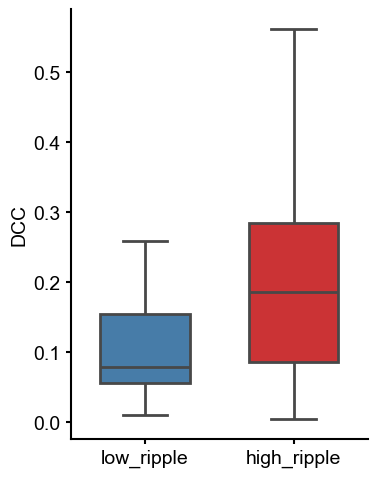

In [165]:
# Load the CSV
import matplotlib as mpl
# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
csv_path = r"D:\Documents\GitHub\R_Project\PPP\codebook\Criticality_analysis\avalanche\dcc_all_all_sleep.csv"
df = pd.read_csv(csv_path)


# Check the labels
labels = df['label'].unique()
assert len(labels) == 2, f"Expected exactly 2 labels, got {labels}"

# Reshape the data into wide format: one row per animal-day, two columns for each label
pivot_df = df.pivot_table(
    index=['animal_name', 'day', 'sleep_idx'],
    columns='label',
    values='dcc'
).dropna()  # Drop any rows that don't have both labels

# Perform paired t-test
from scipy.stats import wilcoxon
import numpy as np

# Extract paired values and remove NaNs safely
x = pivot_df[labels[0]].to_numpy(float)
y = pivot_df[labels[1]].to_numpy(float)

mask = np.isfinite(x) & np.isfinite(y)
x = x[mask]
y = y[mask]

w_stat, p_val = wilcoxon(x, y)

print(f"\nWilcoxon signed-rank test between {labels[0]} and {labels[1]}:")
print(f"W = {w_stat:.3f}, p = {p_val:.4e}, n = {len(x)}")

# Melt for boxplot
melted_df = pivot_df.reset_index().melt(id_vars=['animal_name', 'day'], 
                                        value_vars=labels,
                                        var_name='Label',
                                        value_name='DCC')

# Plot boxplot
plt.figure(figsize=(4, 5))
palette = {"low_ripple": sns.color_palette("Set1")[1], "high_ripple": sns.color_palette("Set1")[0]}
ax = sns.boxplot(data=melted_df, x='Label', y='DCC', palette=palette, showfliers=False, width=0.6,linewidth=2)

# Customize appearance
ax.grid(False)  # Remove grid
ax.spines['top'].set_visible(False)   # Remove top spine
ax.spines['right'].set_visible(False) # Remove right spine
ax.set_xlabel("") 
plt.tight_layout()
plt.savefig(r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\S5_D_low_high_ripple_dcc.svg")  # SVG is vector-based
plt.show()

S8 mean firing rate

Pooled rows: 181594  |  Files read: 12


C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\1470672648.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\1470672648.py:97: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.


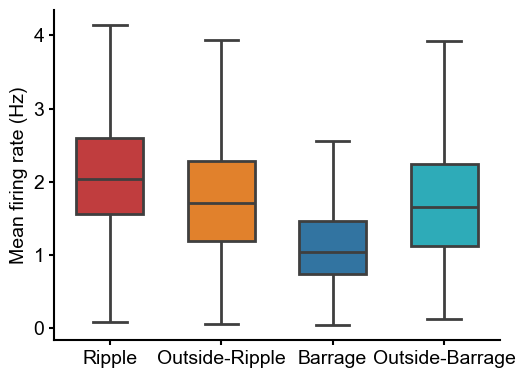

[Paired Wilcoxon per-file] Ripple:  Nfiles=12, T=0, p=4.883e-04, p_bonf=9.766e-04
[Paired Wilcoxon per-file] Barrage: Nfiles=12, T=2, p=1.465e-03, p_bonf=2.930e-03


In [208]:
import os, re, pickle, glob
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
import matplotlib as mpl
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'Liberation Sans', 'DejaVu Sans', 'sans-serif']

# Make mathtext look like Arial
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Arial'
mpl.rcParams['mathtext.it'] = 'Arial:italic'
mpl.rcParams['mathtext.bf'] = 'Arial:bold' 

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# --- config ---
DATA_DIR = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\MUA"
FIG_OUT  = Path(DATA_DIR) / "pooled_ripple_barrage_boxplot.svg"

# filename pattern: {animal}_{day}_ripple_barr_MUA.pkl
fname_re = re.compile(r"^(?P<animal>[^_]+)_(?P<day>[^_]+)_ripple_barr_MUA\.pkl$", re.I)

rows = []
metas = []

for fp in glob.glob(os.path.join(DATA_DIR, "*_ripple_barr_MUA.pkl")):
    name = os.path.basename(fp)
    m = fname_re.match(name)
    animal = m.group("animal") if m else "UNK"
    day    = m.group("day")    if m else "UNK"
    try:
        with open(fp, "rb") as f:
            payload = pickle.load(f)
        df_box = payload["df_box"].copy()
        df_box["animal"] = animal
        df_box["day"]    = day
        df_box["file"]   = name
        rows.append(df_box)

        meta = payload.get("meta", {}).copy()
        meta.update(dict(animal=animal, day=day, file=name))
        metas.append(meta)
    except Exception as e:
        print(f"[warn] skip {name}: {e}")

# pooled data
pooled = pd.concat(rows, ignore_index=True) if rows else pd.DataFrame(columns=["condition","mean_rate","animal","day","file"])
print(f"Pooled rows: {len(pooled)}  |  Files read: {len(rows)}")
palette = {
    "Ripple-Event":  "tab:red",
    "Ripple-Baseline":  "tab:orange",
    "Barrage-Event": "tab:blue",
    "Barrage-Baseline":    "tab:cyan",
}
# ---- plot: four-group boxplot ----
order = ["Ripple-Event","Ripple-Baseline","Barrage-Event","Barrage-Baseline"]
    # use matplotlib 'tab:' named colors
label_map = {
    "Ripple-Event":     "Ripple",
    "Ripple-Baseline":  "Outside-Ripple",
    "Barrage-Event":    "Barrage",
    "Barrage-Baseline": "Outside-Barrage",
}

plt.figure(figsize=(5.5,4))
ax = sns.boxplot(
    data=pooled, x="condition", y="mean_rate",
    order=order, palette=palette,showcaps=True, showfliers=False, width=0.6,linewidth=2
)
# optional: lightly show all points
ax.set_xticklabels([label_map.get(t.get_text(), t.get_text()) for t in ax.get_xticklabels()])
ax.set_xlabel("")
ax.set_ylabel("Mean firing rate (Hz)")

# style: remove grid and top/right spines
ax.grid(False)
for s in ("top","right"): ax.spines[s].set_visible(False)

plt.tight_layout()
plt.savefig(FIG_OUT, dpi=300)
save_path=r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\S8_A_pooled_ripple_barrage_boxplot.svg"
plt.savefig(save_path, dpi=300)
plt.show()
# --- Paired Wilcoxon per-file (Event vs Baseline) ---
from scipy.stats import wilcoxon

# per-file means for each condition
perfile = (
    pooled.groupby(["file","condition"], as_index=False)["mean_rate"].mean()
          .pivot(index="file", columns="condition", values="mean_rate")
)

# Ripple (paired by file)
rip_pairs = perfile[["Ripple-Event","Ripple-Baseline"]].dropna()
T_rip, p_rip = wilcoxon(rip_pairs["Ripple-Event"], rip_pairs["Ripple-Baseline"])
p_rip_bonf = min(1.0, p_rip * 2)  # Bonferroni for 2 tests

# Barrage (paired by file)
bar_pairs = perfile[["Barrage-Event","Barrage-Baseline"]].dropna()
T_bar, p_bar = wilcoxon(bar_pairs["Barrage-Event"], bar_pairs["Barrage-Baseline"])
p_bar_bonf = min(1.0, p_bar * 2)

print(f"[Paired Wilcoxon per-file] Ripple:  Nfiles={len(rip_pairs)}, T={T_rip:.0f}, p={p_rip:.3e}, p_bonf={p_rip_bonf:.3e}")
print(f"[Paired Wilcoxon per-file] Barrage: Nfiles={len(bar_pairs)}, T={T_bar:.0f}, p={p_bar:.3e}, p_bonf={p_bar_bonf:.3e}")

S8 B C

✅ MUA Loader: Used 11 files; skipped 0.
✅ MUA Loader: Used 9 files; skipped 2.
✅ Corr Loader: Loaded 46338 windows from 11 files.
   [warn] qcut failed for barrage_rate; falling back to rank-based tiling with q=6

--- Binning Strategy Note ---
MUA data ('pooled_..._mua') is binned by *per-file* event rate quantiles.
Corr data ('tiles_..._corr') is binned by *global* event rate quantiles.
The plots will compare these two different binning schemes.

MUA vs tile:   slope=0.2298, R²=0.991, p=3.07e-05, n=6
Corr vs tile:   slope=0.3643, R²=0.897, p=0.00408, n=6
Saved: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\S8_B_dual_ripple_tiles.svg
MUA vs tile:   slope=-0.1863, R²=0.971, p=0.000319, n=6
Corr vs tile:   slope=0.002372, R²=0.001, p=0.953, n=6
Saved: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\S8_C_dual_barrage_tiles.svg


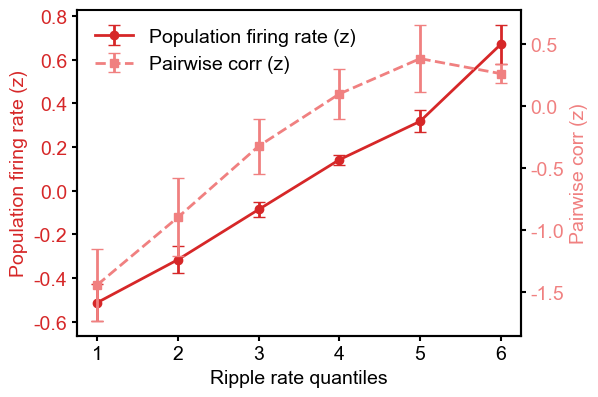

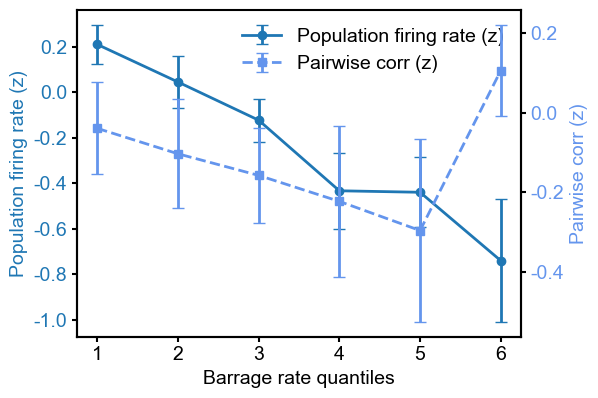

In [205]:
import os
import glob
import pickle
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from scipy.stats import sem as scipy_sem # Use a named import to avoid confusion
from scipy.stats import linregress

import numpy as np
from scipy.stats import gaussian_kde
import matplotlib as mpl

import matplotlib as mpl

# Global font: prefer Arial, with safe fallbacks
mpl.rcParams['svg.fonttype'] = 'none' 
mpl.rcParams['text.usetex'] = False
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.family'] = 'sans-serif'
mpl.rcParams['font.sans-serif'] = [
    'Helvetica Neue', 'Helvetica', 'Arial', 'Liberation Sans', 'DejaVu Sans'
]

# Mathtext to match
mpl.rcParams['mathtext.fontset'] = 'custom'
mpl.rcParams['mathtext.rm'] = 'Helvetica Neue'   # or 'Helvetica'
mpl.rcParams['mathtext.it'] = 'Helvetica Neue:italic'
mpl.rcParams['mathtext.bf'] = 'Helvetica Neue:bold'

# (optional) sizes + minus sign
mpl.rcParams['font.size'] = 16
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams['axes.unicode_minus'] = False

# Global sizes (tweak to taste)
mpl.rcParams['font.size'] = 14
mpl.rcParams['axes.titlesize'] = 14
mpl.rcParams['axes.labelsize'] = 14
mpl.rcParams['xtick.labelsize'] = 14
mpl.rcParams['ytick.labelsize'] = 14
mpl.rcParams['legend.fontsize'] = 14
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
mpl.rcParams["axes.linewidth"] = 1.5       # spine width
mpl.rcParams["xtick.major.width"] =1.5
mpl.rcParams["ytick.major.width"] = 1.5
mpl.rcParams["xtick.minor.width"] = 1.5
mpl.rcParams["ytick.minor.width"] = 1.5
# ==========================
# Helpers
# ==========================
def _lintrend(x_1based, y):
    """Simple linear trend of y vs tile index (1..K). Returns dict with stats."""
    x = np.asarray(x_1based, float)
    y = np.asarray(y, float)
    ok = np.isfinite(x) & np.isfinite(y)
    x, y = x[ok], y[ok]
    if x.size < 2:
        return {"slope": np.nan, "intercept": np.nan, "r2": np.nan, "p": np.nan, "n": int(x.size)}
    r = linregress(x, y)
    return {"slope": r.slope, "intercept": r.intercept, "r2": r.rvalue**2, "p": r.pvalue, "n": int(x.size)}

def _sem(x):
    """Safe standard error of the mean."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    return np.nan if x.size < 2 else float(np.nanstd(x, ddof=1) / np.sqrt(x.size))

def _infer_group_cols(df):
    """Infer file/animal-day grouping columns."""
    cols = df.columns
    if {"animal_name","day"}.issubset(cols):
        return ["animal_name","day"]
    if "file_id" in cols:
        return ["file_id"]
    raise ValueError("Need either ['animal_name','day'] or 'file_id' in the DataFrame.")

def _ensure_numeric_tiles(df):
    """Converts a tile column (e.g., 'Q1') to numeric (e.g., 1)."""
    df = df.copy()
    if "tile" in df.columns and pd.api.types.is_integer_dtype(df["tile"]):
        return df
    
    # Find the tile label column
    tile_col = None
    for c in df.columns:
        if "tile" in str(c).lower() or c == "index":
            tile_col = c; break
    if tile_col is None and df.index.name is not None:
        df = df.reset_index()
        tile_col = df.columns[0]
    elif tile_col is None:
        df.insert(0, "tile_label", [f"Q{i+1}" for i in range(len(df))])
        tile_col = "tile_label"

    # Map Qk -> k
    def _to_int(s):
        s = str(s).upper()
        return int(s[1:]) if s.startswith("Q") and s[1:].isdigit() else (int(s) if s.isdigit() else np.nan)
    
    df["tile"] = df[tile_col].map(_to_int).astype("Int64")
    return df.dropna(subset=["tile"]).copy()

def _make_tiles_labels(df, value_col, k):
    """Helper to create quantile labels, with a fallback to rank-based tiling."""
    try:
        lab = pd.qcut(df[value_col], q=k,
                      labels=[f"Q{i}" for i in range(1, k + 1)],
                      duplicates="drop")
        if lab.isna().all():
            raise ValueError("all NaN labels")
        return lab
    except Exception:
        rk = df[value_col].rank(method="first")
        q = min(k, int(rk.notna().sum()))
        print(f"   [warn] qcut failed for {value_col}; falling back to rank-based tiling with q={q}")
        return pd.qcut(rk, q=q, labels=[f"Q{i}" for i in range(1, q + 1)])

# ==========================
# 1) MUA Data Loader
# ==========================
def load_pool_event_tiles(
    pkl_dir,
    *,
    rate_col,
    mua_col="MUA_rate",
    state="NREM",
    n_bins=6,
    min_bins_required=2,
):
    """Loads MUA data, z-scores MUA *per file*, and bins by event rate *per file*."""
    pkl_dir = Path(pkl_dir)
    pooled = []
    used, skipped = 0, 0

    for file_path in pkl_dir.glob("*.pkl"):
        try:
            obj = pd.read_pickle(file_path)
            df = obj.get("ca1_complete_df") or obj.get("df") or (obj if isinstance(obj, pd.DataFrame) else None)

            if not isinstance(df, pd.DataFrame) or df.empty or "state" not in df.columns:
                skipped += 1; continue

            df = df[df["state"] == state].copy()
            need = [mua_col, rate_col]
            if df.empty or not set(need).issubset(df.columns):
                skipped += 1; continue

            df = df[need].replace([np.inf, -np.inf], np.nan).dropna()
            if df.empty:
                skipped += 1; continue

            # --- per-file MUA normalization (z-score) ---
            m = df[mua_col].mean()
            s = df[mua_col].std(ddof=0)
            if not np.isfinite(s) or s == 0:
                skipped += 1; continue
            df["MUA_norm"] = (df[mua_col] - m) / s

            # --- per-file quantile tiles of the event rate ---
            try:
                df["tile"] = pd.qcut(df[rate_col], q=n_bins, labels=False, duplicates="drop")
            except Exception:
                skipped += 1; continue

            if df["tile"].nunique(dropna=True) < min_bins_required:
                skipped += 1; continue

            df["tile"] = df["tile"].astype("Int64") + 1  # 1..K
            df["file_id"] = file_path.stem
            df["rate_col"] = rate_col
            df["state"] = state

            pooled.append(df[["file_id", "state", "rate_col", "MUA_norm", rate_col, "tile"]])
            used += 1
        except Exception:
            skipped += 1
            continue

    if not pooled:
        raise ValueError(f"No usable MUA data found in {pkl_dir} for {rate_col}.")

    pooled_df = pd.concat(pooled, ignore_index=True)
    print(f"✅ MUA Loader: Used {used} files; skipped {skipped}.")
    return pooled_df

# ==========================
# 2) Correlation Data Loader
# ==========================
def load_all_per_center(base_dir, state="NREM"):
    """Loads pre-computed correlation data ('per_center' DataFrames)."""
    paths = sorted(glob.glob(os.path.join(base_dir, "*.pkl")))
    frames = []
    for p in paths:
        try:
            with open(p, "rb") as f:
                data = pickle.load(f)
        except Exception as e:
            print(f"Skipping {p} (read error: {e})"); continue

        per_center = data.get("per_center", None)
        if not isinstance(per_center, pd.DataFrame) or per_center.empty:
            print(f"Skipping {p} (no per_center DataFrame)."); continue
        
        df = per_center.copy()
        
        # Add identifiers
        df["animal_name"] = data.get("animal_name", os.path.basename(p).split("_")[0])
        df["day"] = data.get("day", os.path.basename(p).split("_")[1])
        df["source_file"] = os.path.basename(p)

        # Normalize column names
        if "mean_pairwise_corr" in df.columns:
            df["paircorr"] = pd.to_numeric(df["mean_pairwise_corr"], errors="coerce")
        elif "corr_mean" in df.columns:
            df["paircorr"] = pd.to_numeric(df["corr_mean"], errors="coerce")
        else:
            print(f"Skipping {p} (no corr column)."); continue

        for rate_name in ["ripple", "barrage"]:
            col_name = f"{rate_name}_rate"
            if col_name not in df.columns:
                for alt in [f"{rate_name}_rate_hz", f"{rate_name}_rate_per_s", f"{rate_name}_occ"]:
                    if alt in df.columns:
                        df = df.rename(columns={alt: col_name}); break
        
        frames.append(df)

    if not frames:
        raise RuntimeError(f"No valid per_center DataFrames found in {base_dir}")

    pooled = pd.concat(frames, ignore_index=True)

    if "state" in pooled.columns:
        nrem = pooled["state"].astype(str).str.upper().eq(state)
        if nrem.any():
            pooled = pooled[nrem].copy()

    for col in ["paircorr", "ripple_rate", "barrage_rate"]:
        if col in pooled.columns:
            pooled[col] = pd.to_numeric(pooled[col], errors="coerce")
            
    print(f"✅ Corr Loader: Loaded {len(pooled)} windows from {pooled['source_file'].nunique()} files.")
    return pooled

# ==========================
# 3) Aggregation Functions
# ==========================
def zscore_per_file(df, value_col="paircorr", group_col="source_file"):
    """Z-scores a value column within each group."""
    df = df.copy()
    df[f"{value_col}_zscore"] = (
        df.groupby(group_col)[value_col]
          .transform(lambda x: (x - np.nanmean(x)) / (np.nanstd(x, ddof=1) or np.nan))
    )
    return df

def make_tiles_clustered(df, value_col, label_col, k=6, corr_col="paircorr_zscore"):
    """
    Bins correlation data by *global* event rate quantiles and aggregates.
    Logic: Mean-per-animal-day, then Mean/SEM of those means.
    """
    df = df.copy().dropna(subset=[value_col, corr_col])
    df[label_col] = _make_tiles_labels(df, value_col, k=k)

    # 1) Per animal-day, per tile mean
    grp = (
        df.groupby(["animal_name", "day", label_col], observed=True)[corr_col]
          .mean()
          .reset_index()
    )

    # 2) Aggregate across animal-days
    g2 = grp.groupby(label_col, observed=True)[corr_col]
    out = pd.DataFrame({
        "corr_mean": g2.mean(),
        "corr_sem": g2.apply(_sem),
        "n_animdays": g2.count()
    }).reset_index()
    
    # Ensure correct order
    order = [f"Q{i}" for i in range(1, k + 1)]
    out[label_col] = pd.Categorical(out[label_col], categories=order, ordered=True)
    return out.sort_values(label_col)

def summarize_mua_perfile_equal_weight(pooled_mua_df, n_bins=6):
    """
    Aggregates MUA data.
    Logic: Mean-per-file, then Mean/SEM of those means.
    """
    d = pooled_mua_df.copy()
    d = d[d["tile"].between(1, n_bins, inclusive="both")]
    grp_keys = _infer_group_cols(d) + ["tile"]

    # 1) Per (file, tile) mean MUA
    pf = (d.groupby(grp_keys, observed=True)["MUA_norm"]
           .mean()
           .rename("mua_file_mean")
           .reset_index())

    # 2) Across files, mean ± SEM
    g = pf.groupby("tile", observed=True)["mua_file_mean"]
    out = pd.DataFrame({
        "tile": g.mean().index.astype(int),
        "mua_mean": g.mean().values,
        "mua_sem": g.apply(_sem).values,
        "n_files": g.count().values
    }).sort_values("tile")
    return out

# ==========================
# 4) Dual-Axis Plotter
def plot_dual_mua_corr_same_agg(mua_pooled_df, corr_tiles_df, *,
                                title="NREM: MUA & pairwise corr vs event-rate tiles",
                                tag=None,  # label in prints (e.g., "Ripple" or "Barrage")
                                color_mua="black", color_corr="tab:blue",
                                mua_label="Population firing rate (z)",
                                corr_label="Pairwise corr (z)",
                                n_bins=6, save_path=None):
    
    # Summarize MUA (mean-per-file, then mean/sem of means)
    M = summarize_mua_perfile_equal_weight(mua_pooled_df, n_bins=n_bins)
    
    # Format Corr data (already mean/sem of animal-day means)
    C = _ensure_numeric_tiles(corr_tiles_df)

    # Find common tiles
    tiles = sorted(set(M["tile"]).intersection(set(C["tile"])))
    if not tiles:
        raise ValueError("No overlapping tiles between MUA and correlation tables.")

    M = M.set_index("tile").loc[tiles]
    C = C.set_index("tile").loc[tiles]
    x = np.array(tiles, int)

    fig, ax1 = plt.subplots(figsize=(6.2, 4.2))

    # Left y: MUA
    ax1.errorbar(x, M["mua_mean"], yerr=M["mua_sem"], fmt="-o", lw=2, capsize=4,
                 color=color_mua, label=mua_label)
    ax1.set_xlabel(title)
    ax1.set_ylabel(mua_label, color=color_mua)
    ax1.tick_params(axis="y", labelcolor=color_mua)
    ax1.set_xticks(x); ax1.set_xticklabels([f"Q{i}" for i in x])
    ax1.grid(False)
    sns.despine(ax=ax1, right=False)

    # Right y: Pairwise corr

    ax2 = ax1.twinx()
    ax2.errorbar(x, C["corr_mean"], yerr=C["corr_sem"], fmt="--s", lw=2, capsize=4,
                color=color_corr, label=corr_label)
    ax2.set_ylabel(corr_label, color=color_corr)

    # make sure ticks/labels are on the right and visible
    ax2.yaxis.set_label_position('right')
    ax2.yaxis.set_ticks_position('right')
    ax2.tick_params(axis='y', right=True, labelright=True, labelcolor=color_corr)
    ax2.spines['right'].set_visible(True)

    # Single legend
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="best", frameon=False)
    # current
    # ax1.set_xticklabels([f"Q{i}" for i in x])

    # replace with either of these:
    ax1.set_xticklabels([str(i) for i in x])          # "1 2 3 4 5 6"
    # or
    ax1.set_xticklabels(x.astype(int))               # same, but simpler if x is np.array

    fig.tight_layout()

    # ---------- Linear trend tests (tile index 1..K) ----------
    tag_str = f"[{tag}] " if tag else ""
    mua_tr = _lintrend(x, M["mua_mean"].values)
    cor_tr = _lintrend(x, C["corr_mean"].values)
    print(f"{tag_str}MUA vs tile:   slope={mua_tr['slope']:.4g}, R²={mua_tr['r2']:.3f}, p={mua_tr['p']:.3g}, n={mua_tr['n']}")
    print(f"{tag_str}Corr vs tile:   slope={cor_tr['slope']:.4g}, R²={cor_tr['r2']:.3f}, p={cor_tr['p']:.3g}, n={cor_tr['n']}")

    if save_path:
        Path(save_path).parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(save_path, dpi=300, bbox_inches="tight")
        print(f"Saved: {save_path}")

    # Return both trend summaries
    return fig, mua_tr, cor_tr


# ==========================
# 5) Main Execution
# ==========================
def main():
    # --- Config ---
    MUA_PKL_DIR = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\MUA_ripple_barr"
    CORR_PKL_DIR = r"D:\Documents\GitHub\Sleep_criticaltiy\data\ripple_barr\pairwise_corrlation"
    SAVE_FIG_DIR = Path(r"D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary")
    SAVE_FIG_DIR.mkdir(parents=True, exist_ok=True)
    
    N_BINS = 6
    CURRENT_STATE = "NREM"

    # --- Load MUA Data (binned *per-file*) ---
    try:
        pooled_ripple_mua = load_pool_event_tiles(
            MUA_PKL_DIR,
            rate_col="ripple_rate_hz",
            state=CURRENT_STATE,
            n_bins=N_BINS
        )
        pooled_barrage_mua = load_pool_event_tiles(
            MUA_PKL_DIR,
            rate_col="barrage_rate_hz",
            state=CURRENT_STATE,
            n_bins=N_BINS
        )
    except ValueError as e:
        print(f"MUA loading failed: {e}")
        return

    # --- Load Correlation Data (binned *globally*) ---
    try:
        pooled_corr = load_all_per_center(CORR_PKL_DIR, state=CURRENT_STATE)
        pooled_corr_z = zscore_per_file(pooled_corr, value_col="paircorr")
        
        # Note: This bins correlation data based on *global* quantiles of event rates
        tiles_rip_corr = make_tiles_clustered(
            pooled_corr_z, value_col="ripple_rate", label_col="tile_ripple", k=N_BINS
        )
        tiles_bar_corr = make_tiles_clustered(
            pooled_corr_z, value_col="barrage_rate", label_col="tile_barrage", k=N_BINS
        )
    except Exception as e:
        print(f"Correlation processing failed: {e}")
        return

    # --- Note on Binning Strategy ---
    print("\n--- Binning Strategy Note ---")
    print("MUA data ('pooled_..._mua') is binned by *per-file* event rate quantiles.")
    print("Corr data ('tiles_..._corr') is binned by *global* event rate quantiles.")
    print("The plots will compare these two different binning schemes.\n")
    
    # --- Plot Ripple ---
    plot_dual_mua_corr_same_agg(
        mua_pooled_df=pooled_ripple_mua,
        corr_tiles_df=tiles_rip_corr,
        title="Ripple rate quantiles",
        color_mua="tab:red", color_corr="#f08080",
        save_path=SAVE_FIG_DIR / "S8_B_dual_ripple_tiles.svg"
    )

    # --- Plot Barrage ---
    plot_dual_mua_corr_same_agg(
        mua_pooled_df=pooled_barrage_mua,
        corr_tiles_df=tiles_bar_corr,
        title="Barrage rate quantiles",
        color_mua="tab:blue", color_corr="#6495ed",
        save_path=SAVE_FIG_DIR / "S8_C_dual_barrage_tiles.svg"
    )

if __name__ == "__main__":
    main()

C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\3786903983.py:134: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\3786903983.py:139: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



Counts per condition:
 condition
Barrage             1830
Barrage_Shuffle     6888
Ripple              1861
Ripple_Shuffle     77018
dtype: int64


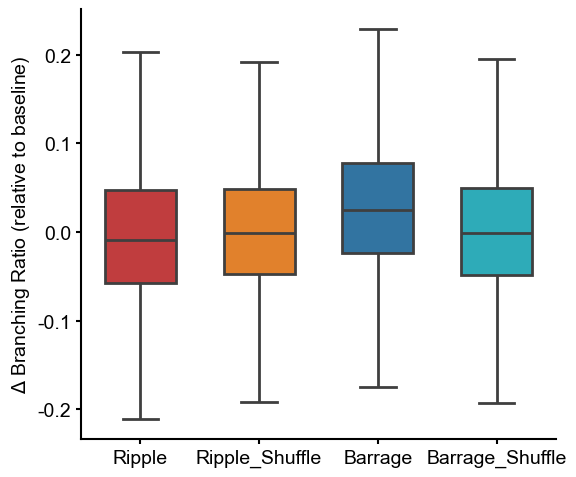

Unique file counts per condition:
condition
Barrage            11
Barrage_Shuffle    11
Ripple             11
Ripple_Shuffle     11
Name: file, dtype: int64


C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\3786903983.py:160: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\3786903983.py:203: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



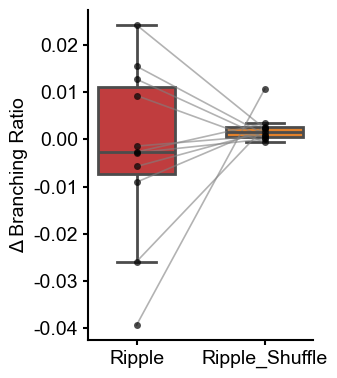

Saved Ripple plot with paired lines: D:\Documents\GitHub\Sleep_criticaltiy\reports\new_plan\supplementary\S4_ripple_br_changes_perfile_paired.svg


C:\Users\Cornell\AppData\Local\Temp\ipykernel_19128\3786903983.py:235: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.



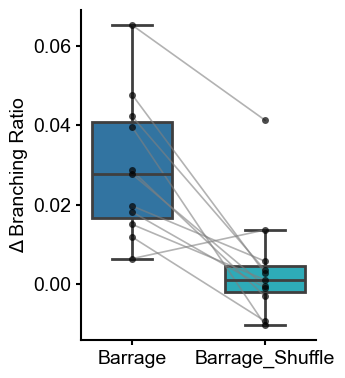

Saved Barrage plot with paired lines: D:\Documents\GitHub\Sleep_criticaltiy\reports\figure_plan\S4_barrage_br_changes_perfile_paired.svg


Presleep_predict performance

In [ ]:
import os, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# --- uses _load_mat_any ---
# _load_mat_any(mat_path)
def _load_mat_any(mat_path):
    from scipy.io import loadmat
    try:
        return loadmat(mat_path, squeeze_me=True, struct_as_record=False, simplify_cells=True)
    except TypeError:
        return loadmat(mat_path, squeeze_me=True, struct_as_record=False)
    except NotImplementedError:
        import mat73
        return mat73.loadmat(mat_path)

def _get_behavior_mat_path(basepath: str) -> Path:
    basepath = str(basepath)
    basename = os.path.basename(basepath.rstrip("\\/"))
    return Path(basepath) / f"{basename}.animal.behavior.mat"

def _extract_trials_and_correct(behavior_mat: dict):
    """
    Returns:
      trials: (N,2) float array [start, stop] in seconds
      trialCorrect: (N,) int array (0/1)
    """
    beh = behavior_mat.get("behavior", None)
    if beh is None:
        raise ValueError("Missing 'behavior' in behavior mat.")

    # handle dict-like vs attribute-like
    def _get(obj, key):
        if isinstance(obj, dict):
            return obj.get(key, None)
        return getattr(obj, key, None)

    trials = _get(beh, "trials")
    tc = _get(beh, "trialcorrect")

    if trials is None or tc is None:
        raise ValueError("Missing behavior.trials or behavior.trialCorrect in behavior mat.")

    trials = np.asarray(trials, dtype=float)
    tc = np.asarray(tc).astype(float).ravel()

    if trials.ndim != 2 or trials.shape[1] != 2:
        raise ValueError(f"behavior.trials has unexpected shape: {trials.shape}")
    if tc.shape[0] != trials.shape[0]:
        # try to salvage common matlab shapes
        if tc.size == trials.shape[0]:
            tc = tc.reshape(-1)
        else:
            raise ValueError(f"trialCorrect length {tc.shape[0]} != trials rows {trials.shape[0]}")

    # convert to 0/1 ints, keep NaNs out
    tc = tc.astype(float)
    ok = np.isfinite(tc)
    tc = tc[ok].astype(int)
    trials = trials[ok, :]

    return trials, tc

import numpy as np
import pandas as pd

def compute_last_behavior_performance(basepath: str, epoch_df: pd.DataFrame) -> dict:
    """
    Compute performance on the last behavioral epoch (non-sleep) that occurs
    immediately before the postsleep sleep epoch.

    Performance = (# trials with tc == 1) / (# trials in that behavioral epoch)

    Returns:
      performance, last_behav_start, last_behav_end, beh_epoch_name, postsleep_epoch_name
    """
    beh_path = _get_behavior_mat_path(basepath)
    if not beh_path.exists() or epoch_df is None or len(epoch_df) == 0:
        return {
            "performance": np.nan,
            "last_behav_start": np.nan,
            "last_behav_end": np.nan,
            "beh_epoch_name": None,
            "postsleep_epoch_name": None,
        }

    mat = _load_mat_any(str(beh_path))
    trials, tc = _extract_trials_and_correct(mat)

    # --- find postsleep epoch (sleep epoch after behavior) ---
    e = epoch_df.copy()
    e["name_str"] = e["name"].astype(str)
    e["startTime"] = pd.to_numeric(e["startTime"], errors="coerce")
    e["stopTime"]  = pd.to_numeric(e["stopTime"], errors="coerce")
    e = e[np.isfinite(e["startTime"]) & np.isfinite(e["stopTime"])].copy()

    name_lower = e["name_str"].str.lower()
    is_sleep = name_lower.str.contains("sleep") | name_lower.str.contains("midsleep") | name_lower.str.contains("presleep")

    sleep = e[is_sleep].copy()
    nonsleep = e[~is_sleep].copy()

    if sleep.empty or nonsleep.empty:
        return {
            "performance": np.nan,
            "last_behav_start": np.nan,
            "last_behav_end": np.nan,
            "beh_epoch_name": None,
            "postsleep_epoch_name": None,
        }

    # choose the "postsleep" as the *last* sleep epoch in the session (common)
    # or the one explicitly containing 'postsleep' if present
    postsleep_candidates = sleep[name_lower.str.contains("midsleep")]
    if not postsleep_candidates.empty:
        postsleep_row = postsleep_candidates.loc[postsleep_candidates["startTime"].idxmin()]
    else:
        postsleep_row = sleep.loc[sleep["startTime"].idxmax()]

    postsleep_start = float(postsleep_row["startTime"])
    postsleep_name = str(postsleep_row["name_str"])

    # behavioral epoch immediately before postsleep: maximize stopTime <= postsleep_start
    beh_candidates = nonsleep[nonsleep["stopTime"] <= postsleep_start]
    if beh_candidates.empty:
        # fallback: just take the last nonsleep epoch
        beh_row = nonsleep.loc[nonsleep["stopTime"].idxmax()]
    else:
        beh_row = beh_candidates.loc[beh_candidates["stopTime"].idxmax()]

    beh_start = float(beh_row["startTime"])
    beh_end   = float(beh_row["stopTime"])
    beh_name  = str(beh_row["name_str"])

    # --- restrict trials to this behavioral window ---
    t0 = trials[:, 0]
    t1 = trials[:, 1]
    in_beh = (t0 >= beh_start) & (t1 <= beh_end)

    # For point events (start only):
    # in_beh = (t0 >= beh_start) & (t0 <= beh_end)

    n = int(np.sum(in_beh))
    if n == 0:
        perf = np.nan
    else:
        perf = float(np.sum(tc[in_beh] == 1) / n)

    return {
        "performance": perf,
        "last_behav_start": beh_start,
        "last_behav_end": beh_end,
        "beh_epoch_name": beh_name,
        "postsleep_epoch_name": postsleep_name,
    }

def _find_adjacent_sleep_epochs(epoch_df: pd.DataFrame, last_behav_start: float, last_behav_end: float):
    """
    Finds:
      - presleep epoch: sleep epoch with stopTime <= last_behav_start, closest in time
      - postsleep epoch: sleep epoch with startTime >= last_behav_end, closest in time
    Sleep is detected by epoch name containing 'sleep' (case-insensitive), OR 'presleep'/'postsleep'.
    """
    if epoch_df is None or len(epoch_df) == 0:
        return None, None

    e = epoch_df.copy()
    e["name_str"] = e["name"].astype(str)

    starts = pd.to_numeric(e["startTime"], errors="coerce")
    stops  = pd.to_numeric(e["stopTime"],  errors="coerce")
    e = e[np.isfinite(starts) & np.isfinite(stops)].copy()
    e["startTime"] = starts[np.isfinite(starts) & np.isfinite(stops)]
    e["stopTime"]  = stops[np.isfinite(starts) & np.isfinite(stops)]

    name_lower = e["name_str"].str.lower()
    is_sleep = name_lower.str.contains("sleep") | name_lower.str.contains("presleep") | name_lower.str.contains("midsleep")

    sleep = e[is_sleep].copy()
    if sleep.empty:
        return None, None

    presleep = sleep[sleep["stopTime"] <= float(last_behav_start)]
    postsleep = sleep[sleep["startTime"] >= float(last_behav_end)]

    presleep_row = presleep.loc[presleep["stopTime"].idxmax()] if not presleep.empty else None
    postsleep_row = postsleep.loc[postsleep["startTime"].idxmin()] if not postsleep.empty else None

    return presleep_row, postsleep_row
def load_center_d2_from_session(basepath, region):
    """
    Loads newest 30s and newest 60s files (if any) and returns pooled
    center_s + d2 with a 'window' column ∈ {'30s','60s'}.
    """
    region = region.upper()
    search_dir = Path(basepath) / "complex_system"
    if not search_dir.exists():
        return pd.DataFrame(columns=["state","center_s","d2","window","region","animal","day"])

    pats = {
        "30s": f"*_{region}_D2_time_resolved_error_bar.mat",
    }
    animal, day = _infer_animal_day_from_path(basepath)

    out = []
    for win_label, pat in pats.items():
        files = glob.glob(str(search_dir / pat))
        if not files:
            continue
        mat_path = max(files, key=os.path.getmtime)
        df = _extract_center_d2_by_state_from_mat(mat_path, region=region, animal=animal, day=day)
        if df.empty:
            continue
        df["window"] = win_label
        out.append(df)

    return pd.concat(out, ignore_index=True) if out else pd.DataFrame(
        columns=["state","center_s","d2","window","region","animal","day"]
    )

def compute_presleep_postsleep_d2(df_sess: pd.DataFrame, epoch_df: pd.DataFrame, last_behav_start: float, last_behav_end: float):
    """
    Returns baseline (presleep NREM mean d2), postsleep NREM mean d2, and normalized values.
    We restrict by *time* using epoch start/stop rather than relying on epoch_name strings inside df_sess.
    """
    if df_sess is None or df_sess.empty:
        return {"d2_presleep": np.nan, "d2_postsleep": np.nan, "d2_norm": np.nan, "d2_delta": np.nan}

    presleep_row, postsleep_row = _find_adjacent_sleep_epochs(epoch_df, last_behav_start, last_behav_end)
    if presleep_row is None or postsleep_row is None:
        return {"d2_presleep": np.nan, "d2_postsleep": np.nan, "d2_norm": np.nan, "d2_delta": np.nan}

    t0_pre, t1_pre = float(presleep_row["startTime"]), float(presleep_row["stopTime"])
    t0_post, t1_post = float(postsleep_row["startTime"]), float(postsleep_row["stopTime"])

    d = df_sess.copy()
    d["state"] = d["state"].astype(str).str.upper()
    d["center_s"] = pd.to_numeric(d["center_s"], errors="coerce")
    d["d2"] = pd.to_numeric(d["d2"], errors="coerce")
    d = d[np.isfinite(d["center_s"]) & np.isfinite(d["d2"])]

    nrem = d[d["state"] == "NREM"]

    pre = nrem[(nrem["center_s"] >= t0_pre) & (nrem["center_s"] < t1_pre)]
    post = nrem[(nrem["center_s"] >= t0_post) & (nrem["center_s"] < t1_post)]

    d2_pre = float(pre["d2"].mean()) if len(pre) else np.nan
    d2_post = float(post["d2"].mean()) if len(post) else np.nan

    if np.isfinite(d2_pre) and d2_pre != 0 and np.isfinite(d2_post):
        d2_norm =  d2_pre
        d2_delta = d2_post - d2_pre
    else:
        d2_norm = np.nan
        d2_delta = np.nan

    return {
        "d2_presleep": d2_pre,
        "d2_postsleep": d2_post,
        "d2_norm": d2_norm,
        "d2_delta": d2_delta,
        "presleep_epoch_name": None if presleep_row is None else str(presleep_row["name_str"]),
        "postsleep_epoch_name": None if postsleep_row is None else str(postsleep_row["name_str"]),
    }

def _infer_animal_day_from_path(basepath):
    base = os.path.basename(basepath.rstrip("\\/"))
    animal = os.path.basename(os.path.dirname(basepath))
    mday = re.search(r"day(\d+)", base, flags=re.I)
    day = int(mday.group(1)) if mday else None
    return animal, day
def pooled_scatter_d2_vs_performance(paths, region="CA1"):
    rows = []
    for basepath in paths:
        # 1) load d2 time-resolved dataframe
        df_sess = load_center_d2_from_session(basepath, region)
        if df_sess is None or df_sess.empty:
            continue

        # 2) load epoch table
        try:
            epoch_df = loading.load_epoch(str(basepath))
        except Exception:
            epoch_df = None

        # 3) compute performance from behavior file
        perf_info = compute_last_behavior_performance(basepath,epoch_df)

        # 4) compute presleep/postsleep NREM d2 and normalize
        d2_info = compute_presleep_postsleep_d2(
            df_sess=df_sess,
            epoch_df=epoch_df,
            last_behav_start=perf_info["last_behav_start"],
            last_behav_end=perf_info["last_behav_end"],
        )

        animal, day = _infer_animal_day_from_path(basepath)
        rows.append({
            "basepath": basepath,
            "animal": animal,
            "day": day,
            "performance": perf_info["performance"],
            "last_behav_start": perf_info["last_behav_start"],
            "last_behav_end": perf_info["last_behav_end"],
            **d2_info
        })

    out = pd.DataFrame(rows)


    import numpy as np
    import matplotlib.pyplot as plt
    from scipy import stats

    # --- prepare data ---
    x = out["d2_norm"].to_numpy()
    y = out["performance"].to_numpy()

    # remove NaNs just in case
    mask = np.isfinite(x) & np.isfinite(y)
    x = x[mask]
    y = y[mask]

    # --- correlation ---
    if len(x) >= 3:
        r, p = stats.pearsonr(x, y)
    else:
        r, p = np.nan, np.nan

    # --- linear fit (for visualization) ---
    if len(x) >= 2:
        slope, intercept = np.polyfit(x, y, 1)
        xx = np.linspace(x.min(), x.max(), 100)
        yy = slope * xx + intercept
    else:
        xx, yy = None, None

    # --- plot ---
    fig, ax = plt.subplots(figsize=(5.5, 4.5))

    ax.scatter(x, y, s=35, alpha=0.8)

    # regression line
    if xx is not None:
        ax.plot(xx, yy, linewidth=2)

    ax.set_xlabel("Pre-sleep NREM d2 (baseline-normalized)")
    ax.set_ylabel("Performance (fraction correct in last behavior block)")

    if np.isfinite(r):
        ax.set_title(
            f"{region}: d2 (pre) vs performance\n"
            f"r = {r:.3f}, p = {p:.3g}, n = {len(x)}"
        )
    else:
        ax.set_title(f"{region}: d2 vs performance")

    # style
    ax.grid(False)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    plt.tight_layout()
    plt.show()

def _extract_center_d2_by_state_from_mat(mat_path, region=None, animal=None, day=None):
    """
    Returns DataFrame with columns:
      state, center_s, d2, region, animal, day
    """
    mat = _load_mat_any(mat_path)
    results = mat.get("results", None)
    if results is None:
        return pd.DataFrame(columns=["state","center_s","d2","region","animal","day"])

    if isinstance(results, dict):
        iter_results = list(results.values())
    else:
        iter_results = list(results if isinstance(results, (list, tuple)) else np.atleast_1d(results))

    rows = []
    for it in iter_results:
        if hasattr(it, "get"):
            st = _to_state_str(it.get("state", "UNKNOWN"))
            c_raw = it.get("center", [])
            d2_raw = it.get("d2", [])
        elif isinstance(it, dict) or hasattr(it, "__getitem__"):
            st = _to_state_str(it.get("state", it["state"] if "state" in it else "UNKNOWN"))
            c_raw = it.get("center", it["center"] if "center" in it else [])
            d2_raw = it.get("d2", it["d2"] if "d2" in it else [])
        else:
            st, c_raw, d2_raw = "UNKNOWN", [], []

        centers = _to_1d_array(c_raw)
        d2_vals = _to_1d_array(d2_raw)
        ok = np.isfinite(centers) & np.isfinite(d2_vals)
        centers, d2_vals = centers[ok], d2_vals[ok]
        if centers.size == 0:
            continue

        st_up = _to_state_str(st).upper()
        if st_up == "WAKE":
            st_up = "AWAKE"
        if st_up not in ("NREM", "AWAKE", "REM"):
            continue

        rows.append(pd.DataFrame({
            "state": st_up,
            "center_s": centers.astype(float, copy=False),
            "d2": d2_vals.astype(float, copy=False),
            "region": region if region else "",
            "animal": animal if animal else "",
            "day": day if day is not None else ""
        }))

    return pd.concat(rows, ignore_index=True) if rows else pd.DataFrame(
        columns=["state","center_s","d2","region","animal","day"]
    )

# ---- RUN ----
paths = [
    r"W:\data\PPP\PPP20\day7",
    r"W:\data\PPP\PPP20\day8",
    r"W:\data\PPP\PPP21\day7",
    r"W:\data\PPP\PPP21\day8",
    r"W:\data\PPP\PPP7\day12",
    r"W:\data\PPP\PPP7\day14",
    r"W:\data\PPP\PPP7\day8",
    r"W:\data\PPP\PPP8\day8",
    r"W:\data\PPP\PPP20\day4",
    r"W:\data\PPP\PPP20\day5",
    r"W:\data\PPP\PPP21\day4",
    r"W:\data\PPP\PPP21\day5",
    r"W:\data\PPP\PPP23\day7",
    r"W:\data\PPP\PPP23\day8",
]

pooled_df = pooled_scatter_d2_vs_performance(
    paths,
    region="CA1"
)



,animal,day,condition,value,file
0,NN16,day13,Ripple,-0.090694,NN16_day13
1,NN16,day13,Ripple,-0.096443,NN16_day13
2,NN16,day13,Ripple,NaN,NN16_day13
3,NN16,day13,Ripple,NaN,NN16_day13
4,NN16,day13,Ripple,NaN,NN16_day13
...,...,...,...,...,...
88282,PPP7,day7,Ripple_Shuffle,-0.016875,PPP7_day7
88283,PPP7,day7,Ripple_Shuffle,0.004332,PPP7_day7
88284,PPP7,day7,Ripple_Shuffle,-0.026544,PPP7_day7
88285,PPP7,day7,Ripple_Shuffle,0.063851,PPP7_day7
